# DOTA v1.0 — Object Detection in Aerial Images
## Complete AI/ML Workflow: EDA → Preprocessing → Modelling → Evaluation → Conclusion

---

**Dataset:** DOTA v1.0 (A Large-Scale Benchmark for Object Detection in Aerial Images)  
**Task:** Multi-class object detection across 15 categories in high-resolution satellite/aerial imagery  
**Models:** SimpleCNN Classifier (Baseline) · Faster R-CNN MobileNetV3-FPN (Two-Stage) · YOLOv8-Large (Single-Stage)  

---

### Table of Contents

| Section | Description |
|---------|-------------|
| **1. Introduction & Problem Statement** | Motivation, objectives, ethical considerations |
| **2. Environment Setup** | Library Installation & Imports, Device Configuration, Data Path Configuration |
| **3. Data Understanding & EDA** | Sample Image & Label Inspection, Image Format Check, <br> Original Class Distribution and Image Count Summary, Combine Datasets & Stratified Sampling, <br> Coordinate Validity Check, Image Dimension Analysis, <br> Visualise a sample image with annotated bounding boxes, Bounding Box Area, Difficulty & Object Density, <br> EDA Summary |
| **4. Preprocessing** | Stratified Re-Splitting (70/15/15), Data Augmentation (Rare Classes), Image Tiling, Compute Class Weights, <br> DOTA &rarr; YOLO Format Conversion (for YOLOv8) |
| **5. Modelling** | Reproducibility & Experiment Config, DOTA Class Mapping, <br> Baseline CNN Classifier (Model 1), <br> Faster R-CNN Model with MobileNetV3-FPN Backbone (Model 2), <br> YOLOv8-Large Detector Training Pipeline (Model 3)  |
| **6. Test Set Evaluation & Model Comparison** | SimpleCNN — Test Set Evaluation, <br> Faster R-CNN — Test Set Evaluation, <br> YOLOv8 — Test Set Evaluation, <br> Three-Model Comparison |
| **7. Critical Discussion (on the best model found)** | Hyperparameter Discussion, Overfitting & Underfitting Diagnostics, <br> Ablation Analysis, Bias & Class-Level Error Analysis |
| **8. Report Quality, References & Conclusion** | Metric justification, Cross-Validation Discussion, Limitations & Future Work, Final Conclusion |
| **9. Group Reflection** | Individual Contributions, Collaboration Challenges, Key Learnings  |
|**10. References**| |

---

**NOTE: This notebook has been executed on Google Colab Pro using an NVIDIA A100 GPU with High-RAM enabled.  
A stratified sample of 300 images (~16% of the pre-defined training and validation data merged together) is used throughout to keep the pipeline runnable in under 3 hours.**

Repository: https://csgitlab.reading.ac.uk/zd827032/csmai_dota2.0_assignment.git

---

## 1. Introduction & Problem Statement
---

### 1.1 Motivation

This project addresses multi-class object detection in aerial/satellite images using the DOTA v1.0 benchmark dataset.

Aerial object detection is critical for urban planning, disaster response, environmental monitoring, and defense. Unlike natural images, aerial images present unique challenges: extreme image sizes (up to 20,000×20,000 pixels) requiring tiling, arbitrary object orientations (oriented bounding boxes), severe class imbalance, and dense small to large structured objects mixed together.

### 1.2 Objectives

1. To perform comprehensive EDA (understanding data quality, distribution, and challenges).
2. To build an appropiate preprocessing pipeline, taking necessary measures.
3. To train and compare data on multiple architectures (CNN baseline &rarr; Faster R-CNN &rarr; YOLOv8)
4. To evaluate using standard detection metrics as per the model used(per-class AP or mAP@0.5)
5. To critically discuss bias, overfitting, limitations, and future improvements.

### 1.3 Ethical Considerations

DOTA v1.0 is a publicly available dataset that can be downloaded from the following website:  
https://captain-whu.github.io/DOTA/dataset.html

This has been licensed for research use.  
Aerial images are captured at altitudes where individuals are not identifiable.  
While doing the project, no personal data is collected, and the model is not designed for real-world monitoring or harmful deployment. The project also considered fairness by adressing class imbalance, so the results are reported honestly rather than only focusing on overall accuracy.  
Overall, the work has been carried out responsibly, with clear awareness of privacy, bias, transparency, and computational limitations.


## 2. Environment Setup
---

### 2.1 Library Installation & Imports

Install and import all libraries required for data processing, visualisation, and deep learning.

In [ ]:
# ===== Install required libraries =====
# Run the line below to install all dependencies
! pip install torch torchvision timm albumentations shapely pycocotools tqdm matplotlib seaborn pandas scikit-learn opencv-python ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 12.7 MB/s eta 0:00:00


In [ ]:
# ===== Core Python libraries =====
import os                            # Operating system interface for file/path operations
import sys                           # System-specific parameters (Python version, executable path)
import cv2                           # OpenCV for image reading, resizing, color conversion
import gc                            # Garbage collector for memory management
import json                          # JSON serialization for config/history files
import time                          # Wall-clock timing for training epochs
import math                          # Mathematical functions (isnan, etc.)
import random                        # Python random number generator for reproducibility
import warnings                      # Warning control (suppress non-critical messages)
import pickle                        # Object serialization (checkpoint metadata)
import shutil                        # High-level file operations (copy, remove directories)
import logging                       # Structured logging for training progress
import platform                      # Platform identification (OS, architecture)
from pathlib import Path             # Object-oriented filesystem paths
from collections import defaultdict, Counter  # Specialised dict/counter containers
from typing import List, Tuple, Dict, Optional  # Type hints for function signatures
from contextlib import nullcontext   # No-op context manager for conditional AMP

# ===== Data manipulation =====
import numpy as np                   # Numerical computing (arrays, linear algebra)
import pandas as pd                  # Tabular data manipulation (DataFrames)

# ===== Visualisation =====
import matplotlib.pyplot as plt      # Core plotting library
import matplotlib.patches as patches # Drawing rectangles/polygons on plots
from matplotlib.patches import Polygon as MplPolygon  # Polygon patches for OBB visualisation
from matplotlib.collections import PatchCollection    # Efficient batch rendering of patches
import seaborn as sns                # Statistical visualisation (barplots, boxplots, heatmaps)
from PIL import Image                # Pillow for lightweight image I/O

# ===== PyTorch & deep learning =====
import torch                         # Core tensor library and autograd
import torch.nn as nn                # Neural network modules (Conv2d, Linear, etc.)
import torch.nn.functional as F      # Functional API (relu, softmax, cross_entropy)
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler  # Data pipeline
import torchvision.transforms as T   # Image transformations (ToTensor, Normalize)
import torchvision.transforms.functional as TF  # Functional transforms
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn  # Detection model
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor      # Custom head
from torchvision.ops import box_iou  # IoU computation for evaluation

# ===== Augmentation & geometry =====
import albumentations as A           # Advanced image augmentation pipeline
from albumentations.pytorch import ToTensorV2  # Albumentations → PyTorch tensor bridge
from shapely.geometry import Polygon, box, MultiPolygon  # Geometric operations for OBB clipping

# ===== Scikit-learn =====
from sklearn.model_selection import train_test_split  # Stratified data splitting

# ===== Progress bars & concurrency =====
from tqdm import tqdm                # Progress bars for loops
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor  # Parallel I/O

# ===== Suppress non-critical warnings =====
warnings.filterwarnings("ignore")    # Keep notebook output clean

print("All libraries imported successfully.")
print(f"Python version : {sys.version.split()[0]}")
print(f"PyTorch version: {torch.__version__}")
print(f"Platform       : {platform.platform()}")

All libraries imported successfully.
Python version : 3.12.13
PyTorch version: 2.10.0+cu128
Platform       : Linux-6.6.113+-x86_64-with-glibc2.35


### 2.2 Device Configuration

Detect and configure the best available compute device (CUDA GPU, Apple MPS, or CPU).  

**Note:** This is a large-scale dataset which is expanded further with augmentation and tiling, leading to computationally intensive training. Therefore, a high-performance GPU (e.g., NVIDIA A100, H100, P100, etc) is required, as CPU-based training would be extremely slow.


In [ ]:
# ===== Automatic device detection =====
RUNTIME_MODE = "auto"   # Options: "auto", "cpu", "gpu", "mps"

if RUNTIME_MODE == "cpu":
    device = torch.device("cpu")                      # Force CPU mode
elif RUNTIME_MODE == "gpu":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
elif RUNTIME_MODE == "mps":
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
else:  # auto — pick the best available device
    if torch.cuda.is_available():
        device = torch.device("cuda")                 # NVIDIA GPU
    elif torch.backends.mps.is_available():
        device = torch.device("mps")                  # Apple Silicon GPU
    else:
        device = torch.device("cpu")                  # Fallback to CPU

print("Using device:", device)
if device.type == "cuda":
    print("Device name:", torch.cuda.get_device_name(0))
elif device.type == "mps":
    print("Device name: Apple Silicon GPU (MPS)")
else:
    print("Device name: CPU")


Using device: cuda
Device name: NVIDIA A100-SXM4-80GB


### 2.3 Data Path Configuration

Define all input/output directory paths.  
<br>
The original DOTA v1.0 dataset comes with pre-defined three sets:
- training (containing images + labels)
- validation (containing images + labels)
- test (containing images)

These can be downloaded from the original website.

In our analysis, we have excluded the original test folder because it has no ground-truth labels. Labels are essential for the models during training to learn correct object classes and bounding-box locations, and during evaluation to measure prediction accuracy fairly.  
Therefore, we have considered only the pre-defined training and validation set, which we later merge and then re-split into train/val/test to have a fully labelled pipeline.  
<br>
**Project Directory Structure:**

```
CSMAI_DOTA
│
├── train/                                     
│   ├── train_images/                          
│   └── train_labels/                          
│
├── val/                                       
│   ├── val_images/                            
│   └── val_labels/                            
│
├── CSMAI_Group4_DOTA_Final_Submission.ipynb    (contains python codes)
│
└── output/                                         
```

**`train/images`**: Contains all images present on the pre-defined training set.   
**`train/labels`**: Contains all labels present on the pre-defined training set.  
**`val/images`**: Contains all images present on the pre-defined validation set.   
**`val/labels`**: Contains all labels present on the pre-defined validation set.  
**`output/`**: Contains all the output files generated (augmented files, tiles, etc)

In [ ]:
# Run the below lines of code below if the notebook is run from google colab with all the data present in google drive
from google.colab import drive     # Import Google Drive module
drive.mount('/content/drive')      # Mount

Mounted at /content/drive


In [ ]:
# ===== Data path configuration =====

# Update ROOT to match environment
ROOT = "/content/drive/MyDrive/CSMAI_CW"  # Base project directory

# ----- Input paths -----
training_data_images_path = os.path.join(ROOT, "train/train_images")     # Training images
training_data_labels_path = os.path.join(ROOT, "train/train_labels")     # Training labels (DOTA format)
validation_data_images_path = os.path.join(ROOT, "val/val_images")       # Validation images
validation_data_labels_path = os.path.join(ROOT, "val/val_labels")       # Validation labels

# ----- Output directory -----
output_dir = os.path.join(ROOT, "output")    # All generated outputs
os.makedirs(output_dir, exist_ok=True)

print("Project root            :", ROOT)
print("Training images path    :", training_data_images_path)
print("Training labels path    :", training_data_labels_path)
print("Validation images path  :", validation_data_images_path)
print("Validation labels path  :", validation_data_labels_path)
print("Output directory        :", output_dir)


Project root            : /content/drive/MyDrive/CSMAI_CW
Training images path    : /content/drive/MyDrive/CSMAI_CW/train/train_images
Training labels path    : /content/drive/MyDrive/CSMAI_CW/train/train_labels
Validation images path  : /content/drive/MyDrive/CSMAI_CW/val/val_images
Validation labels path  : /content/drive/MyDrive/CSMAI_CW/val/val_labels
Output directory        : /content/drive/MyDrive/CSMAI_CW/output


## 3. Data Understanding & Exploratory Data Analysis (EDA)

This section systematically examines the DOTA v1.0 dataset to understand its structure, quality, and challenges.

---

### 3.1 Sample Image & Label Inspection

Load and display a sample image with its annotation file.

Image loaded: shape=(5502, 3875, 3), dtype=uint8


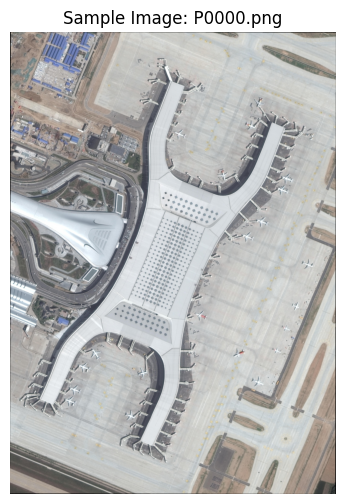


Label file content (first 1000 chars):
imagesource:GoogleEarth
gsd:0.146343590398
2753 2408 2861 2385 2888 2468 2805 2502 plane 0
3445 3391 3484 3409 3478 3422 3437 3402 large-vehicle 0
3185 4158 3195 4161 3175 4204 3164 4199 large-vehicle 0
2870 4250 2916 4268 2912 4283 2866 4263 large-vehicle 0
630 1674 628 1666 640 1654 644 1666 small-vehicle 0
636 1713 633 1706 646 1698 650 1706 small-vehicle 0
717 76 726 78 722 95 714 90 small-vehicle 0
737 82 744 84 739 101 731 98 small-vehicle 0
658 242 648 237 657 222 667 225 small-vehicle 1
735 122 754 129 750 136 733 128 small-vehicle 0
773 137 788 144 784 151 770 144 small-vehicle 0
809 153 827 161 823 168 806 160 small-vehicle 0
696 122 705 124 697 141 691 137 small-vehicle 0
707 126 714 130 706 145 700 141 small-vehicle 0
711 140 718 141 712 157 706 154 small-vehicle 1
924 113 926 106 945 115 942 122 small-vehicle 0
935 95 939 88 955 97 950 104 small-vehicle 1
856 282 864 286 856 303 849 298 small-vehicle 0
640 310 631 304 639 290 646 293

In [ ]:
 # ===== Load and display a sample training image =====
P0000_image_path = os.path.join(training_data_images_path, "P0000.png")  # Image path
P0000_image = cv2.imread(P0000_image_path)                               # Read image (BGR)

if P0000_image is None:                                                  # Check load
    print("Image not found — check data paths.")
else:
    print(f"Image loaded: shape={P0000_image.shape}, dtype={P0000_image.dtype}")  # Image info
    P0000_image_rgb = cv2.cvtColor(P0000_image, cv2.COLOR_BGR2RGB)       # BGR → RGB
    plt.figure(figsize=(6, 6))                                           # Create figure
    plt.imshow(P0000_image_rgb)                                          # Show image
    plt.title("Sample Image: P0000.png")                                 # Title
    plt.axis("off")                                                      # Hide axis
    plt.show()                                                           # Display

# ===== Load and display corresponding label =====
P0000_label_path = os.path.join(training_data_labels_path, "P0000.txt")  # Label path
with open(P0000_label_path, "r") as f:                                   # Open file
    content = f.read()                                                   # Read content
print("\nLabel file content (first 1000 chars):")                        # Header
print(content[:1000])                                                      # Preview

> **Inference:** The sample image loads correctly and the label file follows DOTA format:  
`x1 y1 x2 y2 x3 y3 x4 y4 category difficulty`.


### 3.2 Image Format Check
Check if the format of every image is consistent (e.g., .png, .jpg).

In [ ]:
# ===== Check image extensions across all folders =====
folders = [training_data_images_path, validation_data_images_path]
for folder in folders:
    extensions = set()
    for file in os.listdir(folder):
        extensions.add(os.path.splitext(file)[1].lower())
    print(os.path.basename(folder), "-->", extensions)

train_images --> {'.png', ''}
val_images --> {'.png'}


> **Inference:** All the images in the pre-defined training and validation folders are 100% loadable, and they have a consistent format (.png).

#### 3.3. Original Class Distribution and Image Count Summary

This step visualises the object class distribution in the original training and validation sets separately.  
Since each image may contain multiple objects, so we plot the object instance counts rather than image counts.  
After the plots, the total number of images in both the training and validation folders are reported.

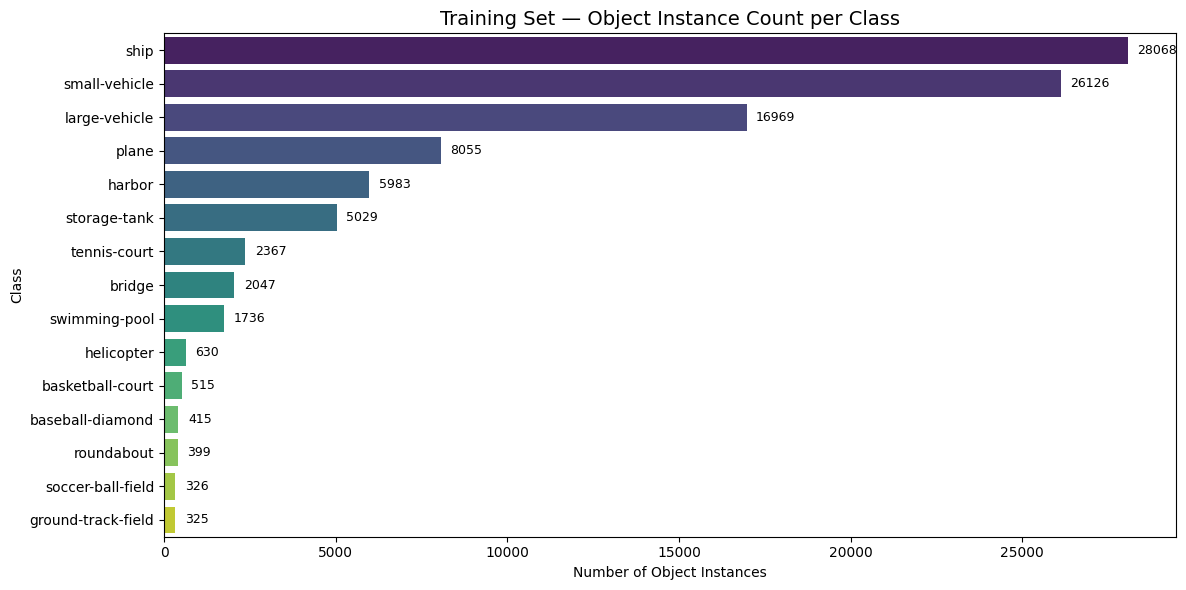

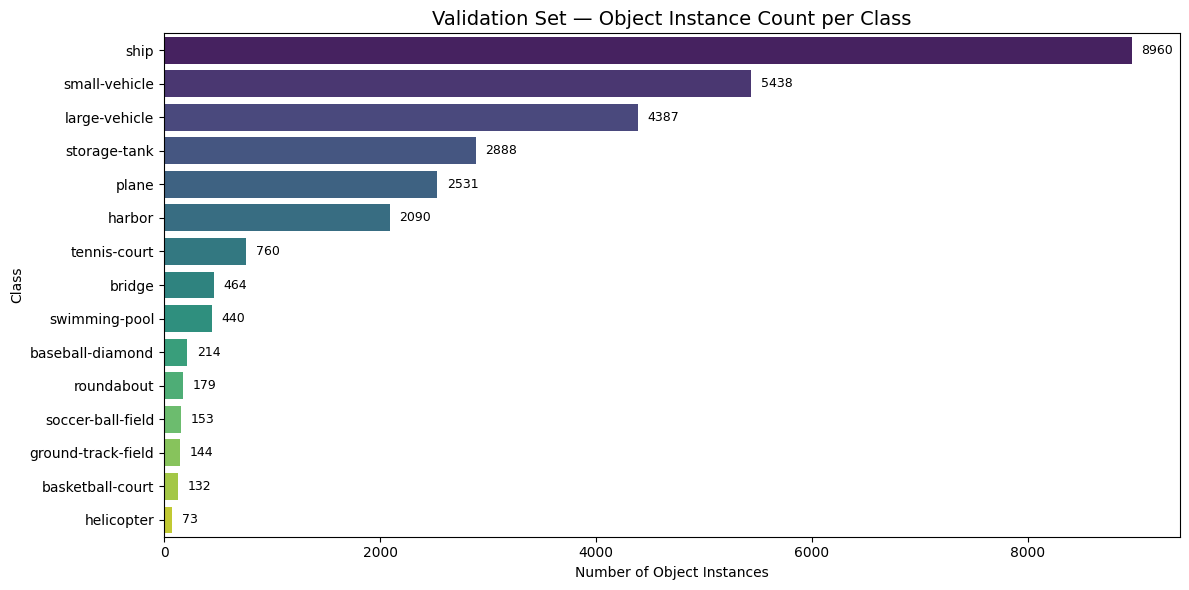

Final Dataset Summary
Total count of images present in the training folder = 1411
Total count of images present in the validation folder = 460
Total number of object instances in the training set = 98990
Total number of object instances in the validation set = 28853


In [ ]:
# ============================================================
# Class Distribution Bar Charts + Image and Instance Counts
# ============================================================

# Import required libraries
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def count_classes_in_dota_labels(label_folder):
    """
    Count object instances per class from DOTA-format label files.

    DOTA annotation format:
    x1 y1 x2 y2 x3 y3 x4 y4 category difficulty
    """

    # Create an empty counter to store class-wise object counts
    class_counts = Counter()

    # Read all label files inside the given folder
    for label_file in sorted(Path(label_folder).glob("*.txt")):

        # Open each label file
        with open(label_file, "r") as f:

            # Read annotation lines one by one
            for line in f:
                line = line.strip()

                # Skip empty lines and DOTA metadata lines
                if not line or line.startswith("imagesource") or line.startswith("gsd"):
                    continue

                # Split annotation line into columns
                parts = line.split()

                # Valid DOTA object annotation should have at least 10 columns
                if len(parts) >= 10:

                    # Class/category name is stored at index 8
                    class_name = parts[8]

                    # Add one count for this class
                    class_counts[class_name] += 1

    # Convert counter to pandas Series and sort from highest to lowest
    return pd.Series(class_counts).sort_values(ascending=False)


def plot_class_distribution(class_counts, title):
    """
    Plot one horizontal bar chart and show the count value beside each bar.
    """

    # Create a new figure
    plt.figure(figsize=(12, 6))

    # Draw horizontal bar chart
    ax = sns.barplot(
        x=class_counts.values,      # Object instance counts
        y=class_counts.index,       # Class names
        hue=class_counts.index,     # Colour bars by class
        palette="viridis",
        legend=False
    )

    # Add count label beside each bar
    for i, value in enumerate(class_counts.values):
        ax.text(
            value + 0.01 * max(class_counts.values),  # x-position
            i,                                        # y-position
            str(value),                               # text label
            va="center",
            fontsize=9
        )

    # Add title and axis labels
    plt.title(title, fontsize=14)
    plt.xlabel("Number of Object Instances")
    plt.ylabel("Class")

    # Adjust layout
    plt.tight_layout()

    # Show plot
    plt.show()


# Count object instances per class in training labels
train_class_counts = count_classes_in_dota_labels(training_data_labels_path)

# Count object instances per class in validation labels
val_class_counts = count_classes_in_dota_labels(validation_data_labels_path)


# Plot 1: Training set class distribution
plot_class_distribution(
    train_class_counts,
    "Training Set — Object Instance Count per Class"
)


# Plot 2: Validation set class distribution
plot_class_distribution(
    val_class_counts,
    "Validation Set — Object Instance Count per Class"
)


# Count total number of images in training and validation folders
train_image_count = len(list(Path(training_data_images_path).glob("*.png")))
val_image_count = len(list(Path(validation_data_images_path).glob("*.png")))

# Count total number of object instances in training and validation labels
train_instance_count = train_class_counts.sum()
val_instance_count = val_class_counts.sum()


# Print final summary after the plots
print("Final Dataset Summary")
print("=" * 45)
print(f"Total count of images present in the training folder = {train_image_count}")
print(f"Total count of images present in the validation folder = {val_image_count}")
print(f"Total number of object instances in the training set = {train_instance_count}")
print(f"Total number of object instances in the validation set = {val_instance_count}")

> **Inference:**  
> The dataset summary shows that the training set contains **1,411 images** with **98,990 object instances**, while the validation set contains **460 images** with **28,853 object instances**. This confirms that DOTA v1.0 is a large and dense object detection dataset, where each aerial image contain many annotated objects.  
>
> As the experiment should further include computationally expensive stages such as augmentation, tiling, object crop extraction (for Baseline CNN), running the full dataset would require significant GPU memory and processing time. Therefore, using a **representative sampled subset** is required for the current implementation.  
>
> The sample will be created in the next step (before the main EDA), so that the complete pipeline remains computationally feasible. Although the sampled dataset may not produce the highest benchmark accuracy, it is suitable in a scenario with limited resources and processing time.

### 3.4 Combine Datasets & Stratified Sampling
---

### 3.4.1. Combine Training & Validation Annotations

All the label files (from both training & validation folders) are read and combined to form a single dataframe called `dota_df_full`.  

The columns included in `dota_df_full` are as follows:
> - (`x1`-`y4`): bounding box coordinates which capture the four corners of oriented objects.
> - `category`: defines the object class.
> - `difficult`: flag, marking objects that are hard to recognise.
> - `image_name`: corresponding image.
> - `split`: records whether the annotation came from the training or validation folder.

This combined pool is used for stratified sampling in the next step.

In [ ]:
# ===== Combine Training & Validation Annotations =====

records = []                                               # List to store all parsed annotation records

# Loop through both training and validation label directories
for split_tag, lbl_path in [("training", training_data_labels_path),
                             ("validation", validation_data_labels_path)]:
    for lf in Path(lbl_path).glob("*.txt"):                # Find all .txt label files in folder
        img_name = lf.stem                                 # Extract image name (e.g., P0001)
        with open(lf, "r") as f:                           # Open each label file
            for line in f:                                 # Read line by line
                line = line.strip()                        # Remove leading/trailing whitespace
                # Skip empty lines and DOTA metadata headers
                if not line or line.startswith("imagesource") or line.startswith("gsd"):
                    continue
                parts = line.split()                       # Split into individual fields
                if len(parts) >= 10:                        # Valid DOTA line has 10+ fields
                    try:
                        records.append({
                            "x1": float(parts[0]), "y1": float(parts[1]),  # OBB corner 1
                            "x2": float(parts[2]), "y2": float(parts[3]),  # OBB corner 2
                            "x3": float(parts[4]), "y3": float(parts[5]),  # OBB corner 3
                            "x4": float(parts[6]), "y4": float(parts[7]),  # OBB corner 4
                            "category": parts[8],          # Object class label
                            "difficult": int(parts[9]),    # Difficulty flag (0=easy, 1=hard)
                            "image_name": img_name,        # Source image identifier
                            "split": split_tag,            # Original folder (training/validation)
                        })
                    except ValueError:
                        continue                           # Skip rows with invalid numeric values

# Convert list of records into a pandas DataFrame
dota_df_full = pd.DataFrame(records)

# Print summary of combined dataset
print(f"Combined: {dota_df_full['image_name'].nunique()} images, {len(dota_df_full):,} instances")
print(f"  Training  : {dota_df_full[dota_df_full['split']=='training']['image_name'].nunique()} images")
print(f"  Validation: {dota_df_full[dota_df_full['split']=='validation']['image_name'].nunique()} images")

dota_df_full.head()

Combined: 1865 images, 127,843 instances
  Training  : 1409 images
  Validation: 456 images


,x1,y1,x2,y2,x3,y3,x4,y4,category,difficult,image_name,split
0,5025.0,5172.0,5020.0,5534.0,4610.0,5506.0,4595.0,5170.0,plane,0,P1399,training
1,3078.0,2535.0,3069.0,2617.0,2996.0,2609.0,3004.0,2527.0,plane,0,P1399,training
2,3059.0,3048.0,3055.0,3132.0,2983.0,3128.0,2984.0,3045.0,plane,0,P1399,training
3,3005.0,2996.0,3003.0,3081.0,2928.0,3076.0,2932.0,2992.0,plane,0,P1399,training
4,3061.0,2944.0,3059.0,3028.0,2985.0,3023.0,2986.0,2943.0,plane,0,P1399,training


### 3.4.2 Stratified Dataset Sampling

Takes a sample of 300 images from the combined pool of 1,865 images using stratified sampling based on each image's dominant class.  
<br>
**Why are 300 images taken:**  
This is approximately 16% of the full dataset (300 ÷ 1865 = ~0.1608 = ~16%).  
It is large enough to retain all 15 classes with sufficient instances for stratified splitting, augmentation, and training three models, yet small enough to complete the entire pipeline on standard hardware.  
<br>
A side-by-side bar chart below compares the full and sampled distributions to verify stratification.  
<br>
**NOTE: All subsequent EDA, preprocessing, and modelling steps operate on the sampled `dota_df`. This is our master data.***

Sampled: 300 images, 17,932 instances
  Training  : 231 images, 13,189 instances
  Validation: 69 images, 4,743 instances


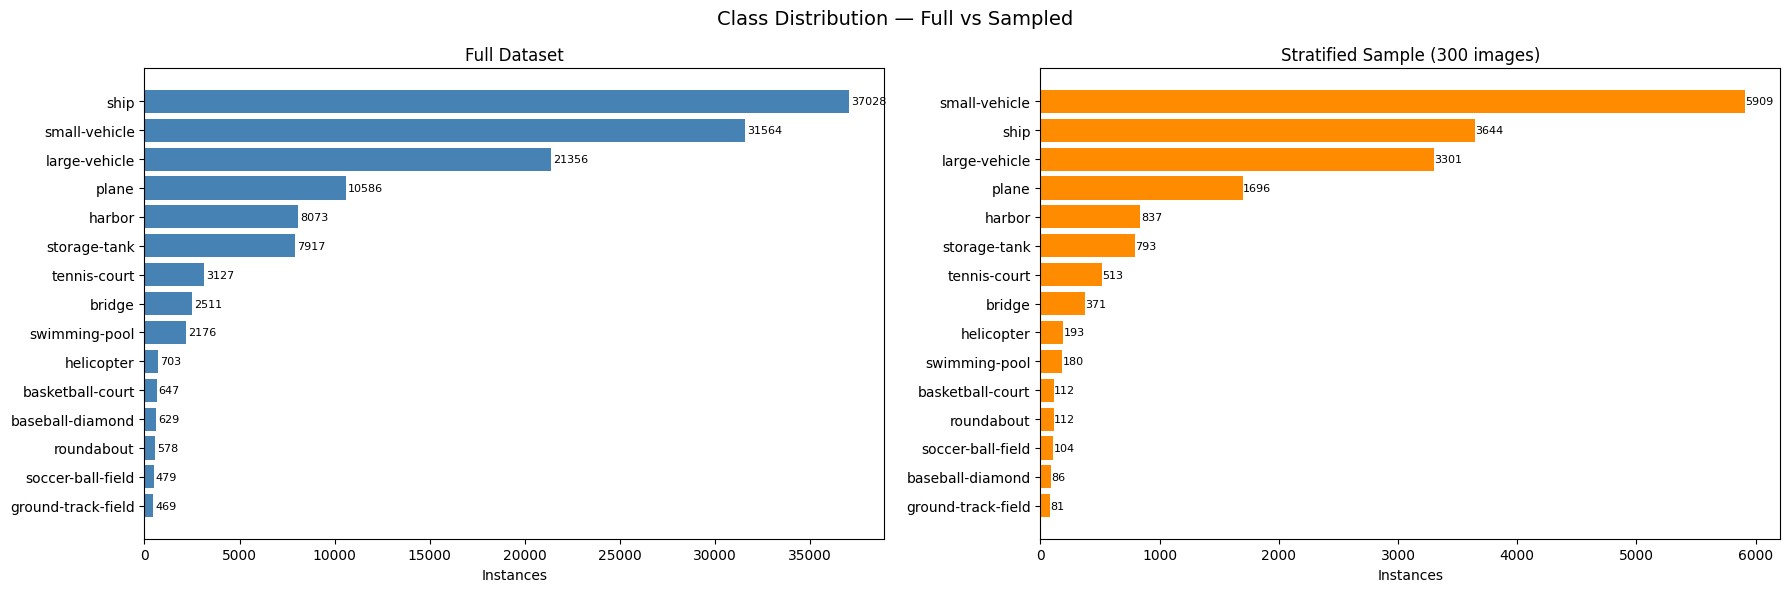



Dimension of the sampled dataframe: (17932, 12)



----------------------------------------------------------------------------------------------------------------------------------
The new master dataframe that will be considered in all the later stages is as below (printing the first 5 rows only):
----------------------------------------------------------------------------------------------------------------------------------


,x1,y1,x2,y2,x3,y3,x4,y4,category,difficult,image_name,split
451,3804.0,204.0,3818.0,203.0,3819.0,229.0,3805.0,228.0,bridge,0,P1311,training
452,2277.0,902.0,2287.0,902.0,2291.0,958.0,2281.0,957.0,bridge,0,P1311,training
453,723.0,3411.0,749.0,3409.0,749.0,3422.0,724.0,3424.0,bridge,0,P1311,training
454,944.0,3381.0,971.0,3375.0,974.0,3389.0,947.0,3394.0,bridge,0,P1311,training
455,736.0,3005.0,764.0,3000.0,766.0,3013.0,738.0,3018.0,bridge,0,P1311,training


In [ ]:
# ===== Stratified Dataset Sampling =====

SAMPLE_MODE = True                                         # True = use subset, False = full dataset
SAMPLE_SIZE = 300                                          # Number of images to sample

if SAMPLE_MODE:
    # Assign each image to its most frequent (dominant) class
    dominant = dota_df_full.groupby("image_name")["category"].agg(
        lambda x: x.value_counts().index[0]                # Pick class with most instances
    ).reset_index()
    dominant.columns = ["image_name", "dominant_class"]     # Rename for clarity

    # Stratified sample — preserves proportion of dominant classes
    sampled, _ = train_test_split(
        dominant,
        train_size=SAMPLE_SIZE,                            # Keep 300 images
        stratify=dominant["dominant_class"],                # Match class ratios
        random_state=42,                                   # Fixed seed for reproducibility
    )
    sampled_images = sampled["image_name"].tolist()         # List of selected image names

    # Filter master DataFrame to only sampled images
    dota_df = dota_df_full[dota_df_full["image_name"].isin(sampled_images)].copy()
else:
    # Use the entire dataset without sampling
    dota_df = dota_df_full.copy()

# Create working subsets based on original folder origin
df_train = dota_df[dota_df["split"] == "training"]         # Training annotations
df_val   = dota_df[dota_df["split"] == "validation"]       # Validation annotations

# Print sampling summary
print(f"Sampled: {dota_df['image_name'].nunique()} images, {len(dota_df):,} instances")
print(f"  Training  : {df_train['image_name'].nunique()} images, {len(df_train):,} instances")
print(f"  Validation: {df_val['image_name'].nunique()} images, {len(df_val):,} instances")

# -------- Compare full vs sampled class distribution --------
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: Full dataset distribution
full_counts = dota_df_full["category"].value_counts().sort_values(ascending=True)
axes[0].barh(full_counts.index, full_counts.values, color="steelblue")
axes[0].set_title("Full Dataset")
axes[0].set_xlabel("Instances")
for i, v in enumerate(full_counts.values):                 # Annotate bar values
    axes[0].text(v + 100, i, str(v), va="center", fontsize=8)

# Right: Sampled dataset distribution
sampled_counts = dota_df["category"].value_counts().sort_values(ascending=True)
axes[1].barh(sampled_counts.index, sampled_counts.values, color="darkorange")
axes[1].set_title(f"Stratified Sample ({dota_df['image_name'].nunique()} images)")
axes[1].set_xlabel("Instances")
for i, v in enumerate(sampled_counts.values):              # Annotate bar values
    axes[1].text(v + 5, i, str(v), va="center", fontsize=8)

# Overall title
plt.suptitle("Class Distribution — Full vs Sampled", fontsize=14)
plt.tight_layout()
plt.show()

# Display first few rows of sampled DataFrame
print(f"\n\nDimension of the sampled dataframe: {dota_df.shape}")

print("\n\n")
print("----------------------------------------------------------------------------------------------------------------------------------")
print("The new master dataframe that will be considered in all the later stages is as below (printing the first 5 rows only):")
print("----------------------------------------------------------------------------------------------------------------------------------")
dota_df.head()

> **Inference:**  
We see that the stratified sampling selects 300 images from the combined pool of 1865, while preserving proportional class representation across all 15 categories.  
The minor ranking variation between certain categories (for example, ship and small-vehicle, which swap top positions) is a natural consequence of image-level stratification, where sampling selects images and not individual instances, and a single aerial image can contain many instances of a particular object.  
Due to this, achieving a perfect instance-level rank preservation is statistically impossible at a 16% sample. Trying to force an exact match would mean manually choosing certain images, which could introduce bias.  
The important thing for us is that, common classes should remain common, rare classes should remain rare, and every class should be included in the sample. These conditions are alreday met.   
>
> The subsequent 70/15/15 re-split on the data in the later stage, applies its own stratification on the sampled pool, further ensuring balanced class representation across train, validation, and test sets.  
>
> We also see that there is huge class imbalance in both the samples:  
> - For the full dataset: 37,028 (ship) ÷ 469 (ground-track-field) $\approx$ 79×.
> - For the sampled dataset: 5,909 (small-vehicle) ÷ 81 (ground-track-field) $\approx$ 73×.

### 3.5 Coordinate Validity Check

Verify all bounding box coordinates are non-negative.  
Negative coordinates indicate annotation errors (this could corrupt training).


In [ ]:
# ===== Check for negative coordinates in sampled data =====
# All coordinates should be valid pixel positions (>= 0)

coord_cols = ["x1", "y1", "x2", "y2", "x3", "y3", "x4", "y4"]  # OBB coordinate columns
neg_count = (dota_df[coord_cols] < 0).any(axis=1).sum()          # Count rows with any negative

print(f"Annotations with negative coordinates: {neg_count}")
if neg_count == 0:
    print("All coordinates valid.")
else:
    print(dota_df[(dota_df[coord_cols] < 0).any(axis=1)].head())  # Show problematic rows

Annotations with negative coordinates: 0
All coordinates valid.


**Inference:** No negative coordinates found. All bounding box vertices are valid pixel positions.

### 3.6 Image Dimension Analysis

Analyse the width and height distribution of the master data (300 sampled images) to understand the scale variation in the dataset.  
This informs the choice of tile size during preprocessing.


Reading dimensions: 100%|██████████| 300/300 [03:04<00:00,  1.63it/s]


Images analysed: 300
Width  range: 387 — 7530 px
Height range: 278 — 6533 px
Mean size   : 2256 × 2179 px


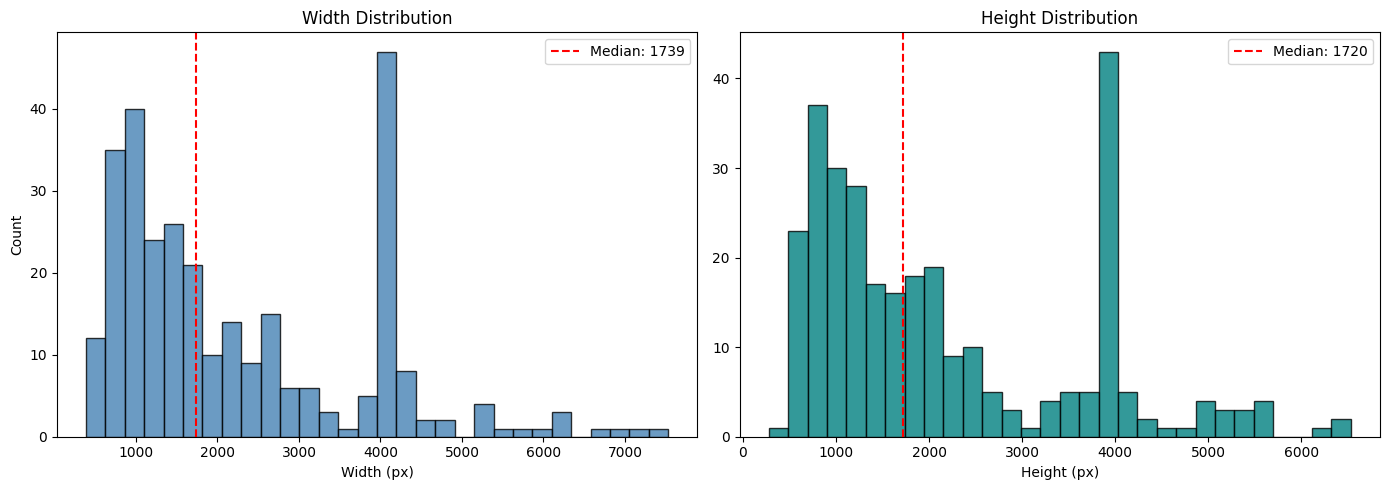

In [ ]:
# ===== Analyse image dimensions (sampled images only) =====
# Read dimensions using PIL header-only for speed

sampled_image_names = dota_df["image_name"].unique()       # 300 sampled image names

dims = []                                                  # Store dimension records
for img_name in tqdm(sampled_image_names, desc="Reading dimensions"):
    for folder in [training_data_images_path, validation_data_images_path]:
        for ext in [".png", ".jpg", ".jpeg", ".tif"]:
            full_path = os.path.join(folder, img_name + ext)
            if os.path.exists(full_path):
                with Image.open(full_path) as img:         # Header-only read
                    w, h = img.size                        # Width, height
                dims.append({"image_name": img_name, "width": w, "height": h})
                break

dim_df = pd.DataFrame(dims)                                # Dimension DataFrame

print(f"Images analysed: {len(dim_df)}")
print(f"Width  range: {dim_df['width'].min()} — {dim_df['width'].max()} px")
print(f"Height range: {dim_df['height'].min()} — {dim_df['height'].max()} px")
print(f"Mean size   : {dim_df['width'].mean():.0f} × {dim_df['height'].mean():.0f} px")

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(dim_df["width"], bins=30, color="steelblue", edgecolor="black", alpha=0.8)
axes[0].set_title("Width Distribution")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Count")
axes[0].axvline(dim_df["width"].median(), color="red", linestyle="--",
                label=f"Median: {dim_df['width'].median():.0f}")
axes[0].legend()

axes[1].hist(dim_df["height"], bins=30, color="teal", edgecolor="black", alpha=0.8)
axes[1].set_title("Height Distribution")
axes[1].set_xlabel("Height (px)")
axes[1].axvline(dim_df["height"].median(), color="red", linestyle="--",
                label=f"Median: {dim_df['height'].median():.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()

> **Inference:**  
We can see that the image dimensions vary substantially across the master data:  
> - with width ranging from 387 to 7530 pixels,
> - and height ranging from 278 to 6533 pixels.
>
> The distribution is bimodal, with clusters around ~1,000px and ~4,000px for both, and a median of 1,739×1,720 pixels.  
This wide variation confirms that raw images cannot be fed directly into detection models, which expect fixed-size inputs.  
We would require to tile the images into uniform patches and standardise them while preserving small-object details.

### 3.7 Visualise a sample image with annotated bounding boxes
____

Let's visualise the first sample image from the masterdata with its oriented bounding box (OBB) annotations overlaid.  
Each object is outlined with a colour-coded polygon and labelled with its class name, showing how DOTA annotations map onto the actual aerial imagery.



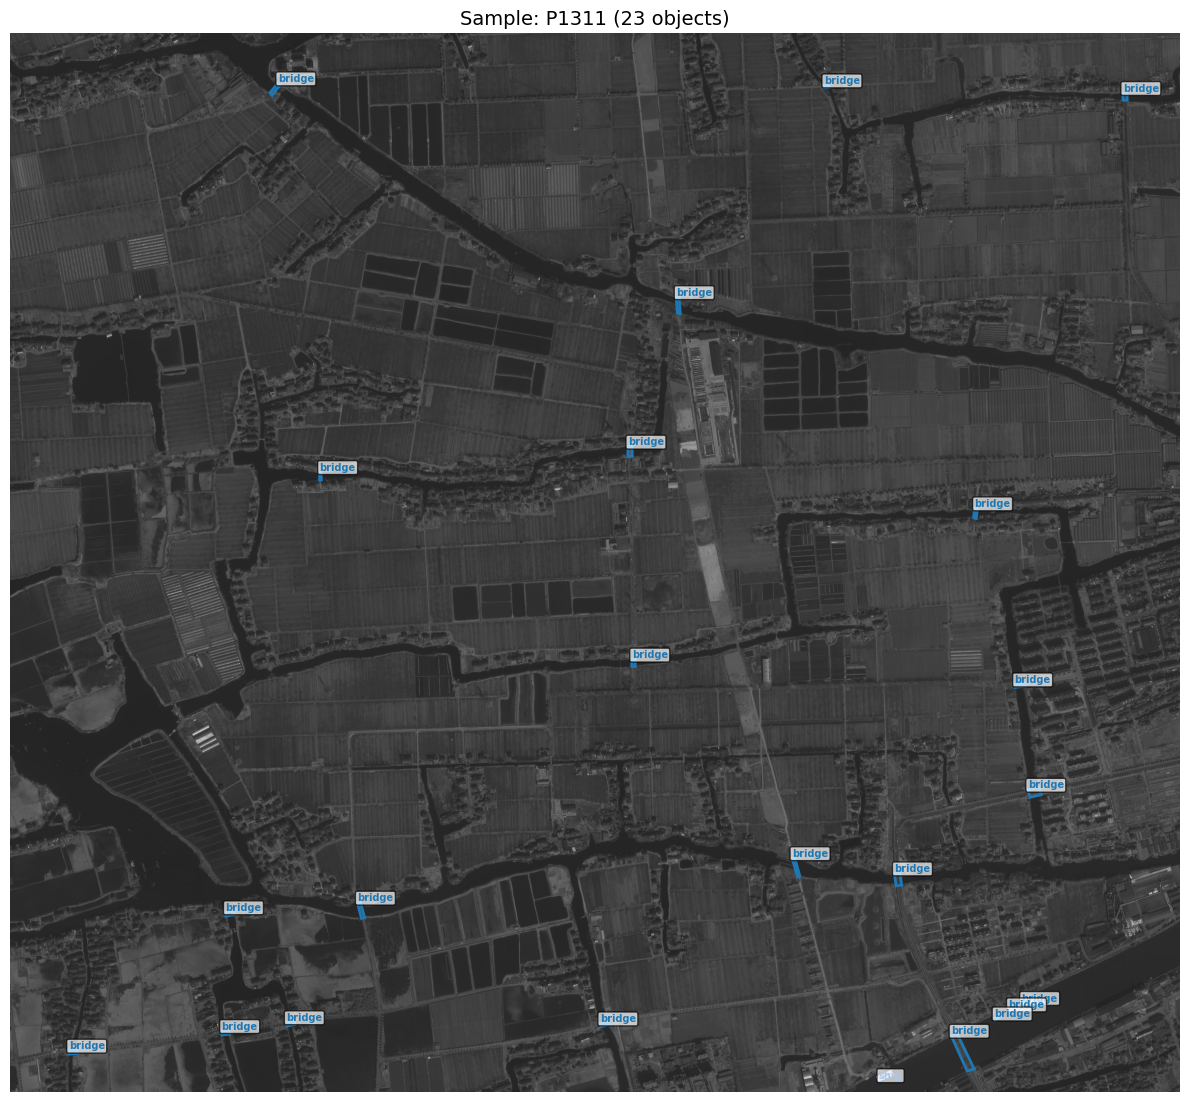

In [ ]:
from matplotlib.patches import Polygon as MplPoly

# Pick first sampled image from dota_df
sample_img_name = dota_df["image_name"].iloc[0]

# Find its path on disk
for folder, lbl_folder in [(training_data_images_path, training_data_labels_path),
                            (validation_data_images_path, validation_data_labels_path)]:
    img_candidate = os.path.join(folder, sample_img_name + ".png")
    lbl_candidate = os.path.join(lbl_folder, sample_img_name + ".txt")
    if os.path.exists(img_candidate):
        image_path = img_candidate
        label_path = lbl_candidate
        break

max_boxes = 50                                             # Max annotations to display

# Load image
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Parse DOTA annotations
instances = []
with open(label_path, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("imagesource") or line.startswith("gsd"):
            continue
        parts = line.split()
        if len(parts) >= 10:
            try:
                instances.append({
                    "x1": float(parts[0]), "y1": float(parts[1]),
                    "x2": float(parts[2]), "y2": float(parts[3]),
                    "x3": float(parts[4]), "y3": float(parts[5]),
                    "x4": float(parts[6]), "y4": float(parts[7]),
                    "category": parts[8],
                    "difficulty": int(parts[9])
                })
            except ValueError:
                continue

# Plot image with bounding boxes
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(img_rgb)

colours = plt.cm.tab20(np.linspace(0, 1, 20))
categories = sorted(set(i["category"] for i in instances))
cat_to_colour = {cat: colours[i % 20] for i, cat in enumerate(categories)}

for inst in instances[:max_boxes]:
    polygon = MplPoly(
        [(inst["x1"], inst["y1"]), (inst["x2"], inst["y2"]),
         (inst["x3"], inst["y3"]), (inst["x4"], inst["y4"])],
        closed=True, fill=False,
        edgecolor=cat_to_colour[inst["category"]], linewidth=2
    )
    ax.add_patch(polygon)
    ax.text(inst["x1"], inst["y1"] - 5, inst["category"],
            color=cat_to_colour[inst["category"]], fontsize=7, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.7))

ax.set_title(f"Sample: {sample_img_name} ({len(instances)} objects)", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.show()

### 3.8 Bounding Box Area, Difficulty & Object Density

This step analyses the size distribution of bounding boxes, the proportion of difficult annotations across classes, and the number of objects per image.  
It helps understand scale variation, annotation complexity, and scene density, which are critical for designing robust detection models and handling challenges such as small objects and crowded scenes.

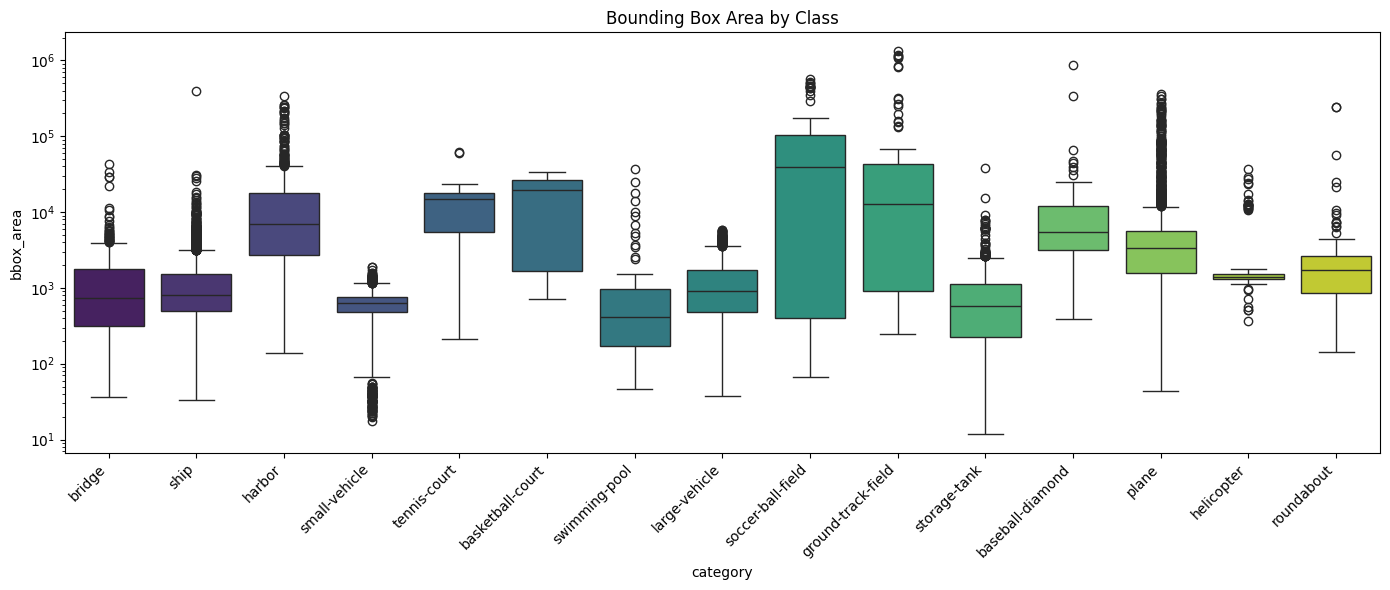

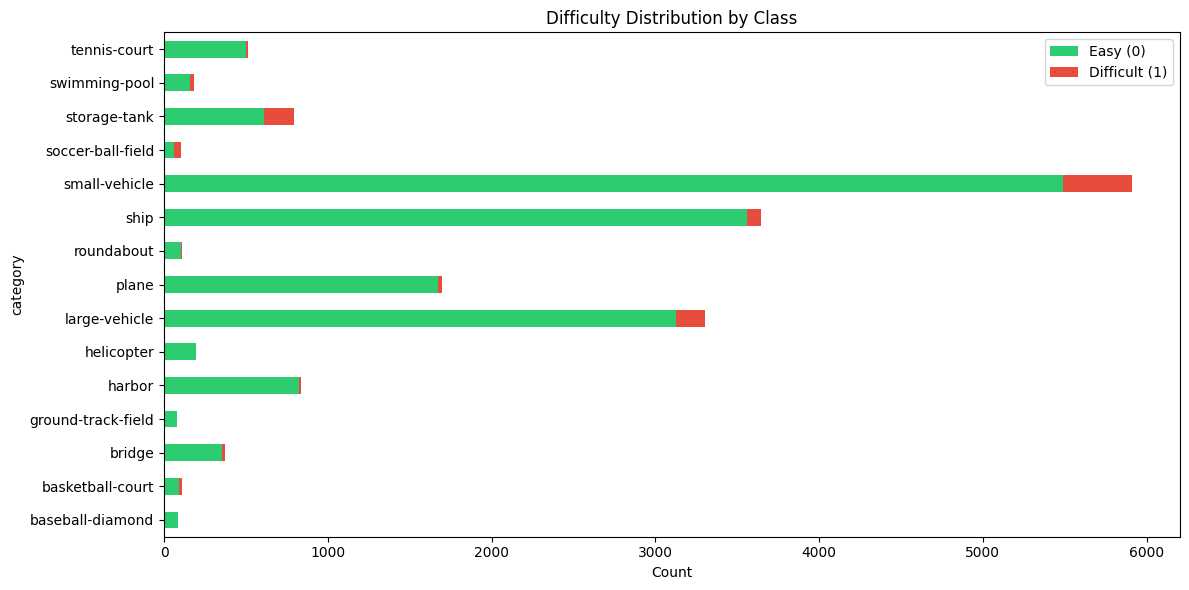

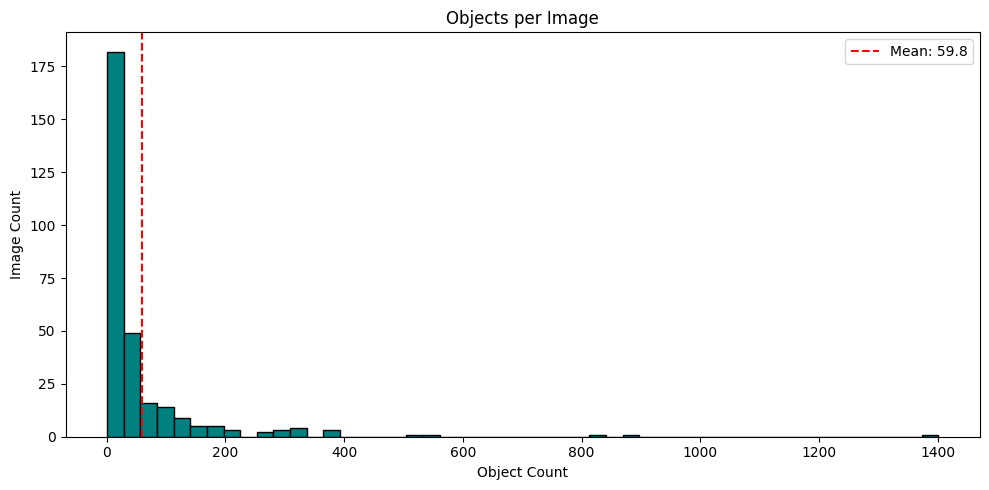

Min: 1 | Max: 1401 | Mean: 59.8


In [ ]:
# ===== Bounding box area (Shoelace formula) =====
dota_df['bbox_area'] = 0.5 * np.abs(  # Compute polygon area for OBB
    dota_df['x1']*dota_df['y2'] + dota_df['x2']*dota_df['y3'] +
    dota_df['x3']*dota_df['y4'] + dota_df['x4']*dota_df['y1']
    - dota_df['y1']*dota_df['x2'] - dota_df['y2']*dota_df['x3']
    - dota_df['y3']*dota_df['x4'] - dota_df['y4']*dota_df['x1'])

fig, ax = plt.subplots(figsize=(14, 6))  # Create plot
sns.boxplot(data=dota_df, x='category', y='bbox_area', palette='viridis', ax=ax)  # Boxplot per class
ax.set_title('Bounding Box Area by Class')  # Title
ax.set_yscale('log')  # Log scale to handle large variation
plt.xticks(rotation=45, ha='right')  # Rotate labels for readability
plt.tight_layout()
plt.show()


# ===== Difficulty distribution =====
pivot = dota_df.groupby(['category', 'difficult']).size().unstack(fill_value=0)  # Count easy vs difficult per class
pivot.plot(kind='barh', stacked=True, figsize=(12, 6), color=['#2ecc71', '#e74c3c'])  # Stacked bar plot
plt.title('Difficulty Distribution by Class')  # Title
plt.xlabel('Count')  # X-axis label
plt.legend(['Easy (0)', 'Difficult (1)'])  # Legend
plt.tight_layout()
plt.show()


# ===== Objects per image =====
obj_per_img = dota_df.groupby('image_name').size()  # Count objects in each image

fig, ax = plt.subplots(figsize=(10, 5))  # Create histogram plot
ax.hist(obj_per_img, bins=50, color='teal', edgecolor='black')  # Distribution of object counts
ax.set_title('Objects per Image')  # Title
ax.set_xlabel('Object Count'); ax.set_ylabel('Image Count')  # Axis labels

ax.axvline(obj_per_img.mean(), color='red', linestyle='--', label=f'Mean: {obj_per_img.mean():.1f}')  # Mean line
ax.legend()

plt.tight_layout()
plt.show()

print(f"Min: {obj_per_img.min()} | Max: {obj_per_img.max()} | Mean: {obj_per_img.mean():.1f}")  # Summary stats

> **Inference:**   
We see that:
> - Object scale varies enormously (tiny helicopter or small-vehicle to large ground-track-field or soccer ball field),
> - Difficulty is not uniformly distributed across classes
> - Object density varies widely (some images have hundreds of objects, while some have few).  
>
> These findings further justify tiling, class-weighted loss, and multi-scale detection.

### 3.9 EDA Summary

| Finding | Pipeline Impact |
|---------|----------------|
| 15 classes, consistent | Fixed output layer = 15 |
| 300 stratified sample preserves class proportions | Full pipeline feasible on standard hardware |
| ~73× class imbalance (small-vehicle vs ground-track-field) | Augment rare classes + class-weighted loss |
| Images range from ~300 to ~7,000 px (bimodal at approx. ~1,000 and ~4,000) <br> Objects per image varies widely (dense scenes with 100+ objects) | Tiling required with overlap <br> (prevents object truncation at boundaries) |
| Oriented bounding boxes | OBB &rarr; AABB conversion for standard detectors |
| No negative coordinates found | Annotations geometrically valid for direct use |

## 4. Data Preprocessing

This section transforms the raw DOTA dataset into formats suitable for training detection models.

---

### 4.1 Stratified Re-Splitting (70/15/15)

Re-split the master data into train/val/test using stratified sampling.  

**Why stratify again:**   
The earlier stratified sampling (Section 3.4.2) preserved class proportions when reducing 1,865 images to 300. This second stratification ensures those proportions carry through into the new train/val/test splits. This step also creates a fully labelled test set for local evaluation.  

**What this step produces:**
- `new_train_imgs` / `dota_new_train_df` — dataframe used for model training
- `new_val_imgs` / `dota_new_val_df` — dataframe used for validation
- `new_test_imgs` / `dota_new_test_df` — dataframe used for test

 Outputs include separate dataframes with image and instance summaries.

In [ ]:
# ===== Stratified Re-Split into Train / Validation / Test =====

train_ratio = 0.70
val_ratio = 0.15
test_ratio = 0.15
random_state = 42

assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6, "Ratios must sum to 1.0"

all_images = dota_df['image_name'].unique()

# -------- COMPUTE DOMINANT CLASS PER IMAGE --------
dominant_classes = [
    dota_df[dota_df['image_name'] == img]['category'].mode()[0]
    if len(dota_df[dota_df['image_name'] == img]) > 0 else 'unknown'
    for img in all_images
]

# -------- SAFE STRATIFICATION --------
# Keep increasing threshold until all groups have >= 2 members
from collections import Counter

for min_count in [2, 3, 4, 5, 10]:
    class_counts = Counter(dominant_classes)
    safe_labels = [
        cls if class_counts[cls] >= min_count else "other"
        for cls in dominant_classes
    ]
    safe_counts = Counter(safe_labels)
    if all(c >= 2 for c in safe_counts.values()):
        print(f"Using min_count={min_count}, merged {sum(1 for c in class_counts if class_counts[c] < min_count)} classes into 'other' ({safe_counts['other']} images)")
        break
else:
    # Fallback: no stratification at all
    safe_labels = None
    print("Falling back to random split (stratification not possible)")

# -------- FIRST SPLIT (TRAIN vs TEMP) --------
temp_ratio = val_ratio + test_ratio

new_train_imgs, temp_imgs, _, temp_cls = train_test_split(
    all_images,
    safe_labels if safe_labels else dominant_classes,
    test_size=temp_ratio,
    stratify=safe_labels,                                  # None = random split
    random_state=random_state
)

# -------- SECOND SPLIT (VAL vs TEST) --------
temp_counts = Counter(temp_cls) if safe_labels else {}
can_stratify = safe_labels and all(c >= 2 for c in temp_counts.values())

new_val_imgs, new_test_imgs = train_test_split(
    temp_imgs,
    test_size=0.5,
    stratify=temp_cls if can_stratify else None,
    random_state=random_state
)

# -------- PRINT RESULTS --------
print(f"\nStratified split results:")
print(f"  Train : {len(new_train_imgs)} images ({100*len(new_train_imgs)/len(all_images):.1f}%)")
print(f"  Val   : {len(new_val_imgs)} images ({100*len(new_val_imgs)/len(all_images):.1f}%)")
print(f"  Test  : {len(new_test_imgs)} images ({100*len(new_test_imgs)/len(all_images):.1f}%)")

# -------- CREATE DATAFRAMES --------
dota_new_train_df = dota_df[dota_df['image_name'].isin(new_train_imgs)]
dota_new_val_df = dota_df[dota_df['image_name'].isin(new_val_imgs)]
dota_new_test_df = dota_df[dota_df['image_name'].isin(new_test_imgs)]

print(f"\nNew Training-Dataframe: {len(dota_new_train_df)} instances across {dota_new_train_df['image_name'].nunique()} images")
print(f"New Validation-Dataframe  : {len(dota_new_val_df)} instances across {dota_new_val_df['image_name'].nunique()} images")
print(f"New Test-Dataframe : {len(dota_new_test_df)} instances across {dota_new_test_df['image_name'].nunique()} images")

Using min_count=4, merged 4 classes into 'other' (10 images)

Stratified split results:
  Train : 210 images (70.0%)
  Val   : 45 images (15.0%)
  Test  : 45 images (15.0%)

New Training-Dataframe: 11599 instances across 210 images
New Validation-Dataframe  : 3471 instances across 45 images
New Test-Dataframe : 2862 instances across 45 images


> **Inference:**  
The master-data has been successfully split into 210 training (11,599 instances), 45 validation (3,471 instances), and 45 test (2,862 instances) images.  
(Four rare dominant classes were temporarily grouped for stratification purposes only — all 15 DOTA categories remain fully represented in the resulting DataFrames)  
The 70/15/15 ratio ensures sufficient training data for all three models while reserving meaningful validation and test sets.


### 4.2 Data Augmentation (Rare Classes)

Apply geometric and photometric augmentations to images containing under-represented classes.  
The ~73× class imbalance means rare classes have insufficient training examples.  
OBB-aware augmentation via keypoints preserves annotation geometry.

**Approach:** Identify rare classes (below-median frequency), apply Albumentations with keypoint-based OBB transformation, generate 3 augmented variants per rare-class image.

In [ ]:
# Identification of Rare Classes

counts = dota_new_train_df['category'].value_counts()  # Count instances per class (training set)
threshold = counts.median()  # Use median count as threshold for rarity
rare_classes = counts[counts < threshold].index.tolist()  # Select classes below threshold

print(f"Threshold (median): {threshold}")  # Display threshold
print(f"\nRare classes to augment ({len(rare_classes)}):")  # Summary of rare classes

for rc in rare_classes:
    print(f"  {rc}: {counts[rc]} instances")  # Print each rare class with its count

Threshold (median): 266.0

Rare classes to augment (7):
  helicopter: 188 instances
  basketball-court: 94 instances
  soccer-ball-field: 84 instances
  roundabout: 79 instances
  ground-track-field: 64 instances
  baseball-diamond: 58 instances
  swimming-pool: 46 instances


In [ ]:
# Identification of images containing rare classes

rare_image_names = dota_new_train_df[
    dota_new_train_df['category'].isin(rare_classes)                 # Filter rows belonging to rare classes
]['image_name'].unique()                                             # Extract unique image names containing rare classes

# Count of such images
print(f"Images containing rare classes: {len(rare_image_names)}")

Images containing rare classes: 77


**Augmentation workflow:**
- Identification of images containing rare/underrepresented classes to balance the dataset.
- Application of geometric transformations (flip, rotation, affine) while preserving OBB structure using keypoints.
- Addition of photometric augmentations (brightness, noise, CLAHE) to improve robustness.
- Conversion of OBB annotations into keypoints and back, ensuring correct polygon transformation.
- Generation of multiple augmented samples per image to increase data diversity.
- Saving augmented images and labels in standard DOTA format.
- Skipping invalid or corrupted cases to maintain data quality and consistency.

Overall, this step reduces class imbalance and improves model generalisation.  
<br>
**Output directory structure for augmented files:**   
```
output/
└── augmented/
    ├── images/
    │   └── ...
    └── labels/
        └── ...
```
Naming convention: **originalName_augX**  
Example: P0000_aug0.png, P0000_aug1.txt  
Meaning:   
originalImageName: Source image  
augX: Augmentation index (0, 1, 2, …)
<br>  
Note: The augmentation script first deletes any existing augmented data and then creates a fresh set of images and labels on every run, ensuring consistency and avoiding duplicates.

In [ ]:
import shutil

# ===== CLEAN OUTPUT =====
aug_img_dir = os.path.join(output_dir, "augmented/images")   # Output folder for augmented images
aug_label_dir = os.path.join(output_dir, "augmented/labels") # Output folder for augmented labels

shutil.rmtree(aug_img_dir, ignore_errors=True)  # Remove old augmented images
shutil.rmtree(aug_label_dir, ignore_errors=True)  # Remove old augmented labels
os.makedirs(aug_img_dir, exist_ok=True)  # Create fresh image folder
os.makedirs(aug_label_dir, exist_ok=True)  # Create fresh label folder

# ===== TRUE OBB AUGMENTATION (POLYGON VIA KEYPOINTS) =====
transform = A.Compose(
    [
        A.HorizontalFlip(p=0.5),        # Flip horizontally
        A.VerticalFlip(p=0.3),          # Flip vertically
        A.RandomRotate90(p=0.5),        # Rotate in 90° steps

        # Geometric transforms (safe since we use keypoints)
        A.Affine(
            scale=(0.9, 1.1),           # Slight zoom in/out
            translate_percent=(-0.1, 0.1),  # Shift image
            rotate=(-30, 30),           # Arbitrary rotation
            shear=(-5, 5),              # Small shear
            p=0.5
        ),

        A.RandomBrightnessContrast(p=0.4),  # Lighting variation
        A.GaussNoise(p=0.3),                # Add noise
        A.CLAHE(p=0.3),                     # Improve contrast
    ],
    keypoint_params=A.KeypointParams(format="xy", remove_invisible=False)  # Keep all keypoints
)

# ===== SETTINGS =====
image_folders = [training_data_images_path]  # Source image folders
rare_image_names = np.unique(rare_image_names)  # Unique rare images
num_augmentations = 3  # Number of augmentations per image

total, skipped = 0, []  # Counters

# ===== LOOP =====
for name in tqdm(rare_image_names):  # Iterate through rare images
    img = next((cv2.imread(os.path.join(f, name + ".png"))
                for f in image_folders if os.path.exists(os.path.join(f, name + ".png"))), None)

    if img is None:
        skipped.append(name); continue  # Skip if image missing

    data = dota_new_train_df[dota_new_train_df["image_name"] == name]  # Get annotations
    if data.empty:
        skipped.append(name); continue  # Skip if no annotations

    keypoints = []  # Store all OBB corner points
    labels = []     # Store class labels
    diffs = []      # Store difficulty flags

    # OBB → keypoints (4 corners per object)
    for _, r in data.iterrows():
        pts = [
            (r["x1"], r["y1"]),
            (r["x2"], r["y2"]),
            (r["x3"], r["y3"]),
            (r["x4"], r["y4"]),
        ]
        keypoints.extend(pts)  # Add all 4 points
        labels.append(r["category"])  # Store class
        diffs.append(int(r["difficult"]) if "difficult" in r else 0)  # Store difficulty

    if not keypoints:
        skipped.append(name); continue  # Skip if no valid keypoints

    # ===== AUGMENT =====
    for i in range(num_augmentations):
        try:
            aug = transform(image=img, keypoints=keypoints)  # Apply augmentation

            aug_img = aug["image"]        # Augmented image
            aug_kps = aug["keypoints"]   # Transformed keypoints

            if len(aug_kps) % 4 != 0:
                continue  # Ensure valid grouping (4 points per object)

            out_name = f"{name}_aug{i}"  # Output file name

            # Save image
            cv2.imwrite(os.path.join(aug_img_dir, out_name + ".png"), aug_img)

            # Save labels
            with open(os.path.join(aug_label_dir, out_name + ".txt"), "w") as f:
                f.write("imagesource:GoogleEarth\n")  # Metadata
                f.write("gsd:1.0\n")                 # Metadata

                for j in range(0, len(aug_kps), 4):
                    pts = aug_kps[j:j+4]  # Get 4 points per object

                    # Flatten coordinates
                    flat = [coord for pt in pts for coord in pt]

                    label = labels[j // 4]  # Corresponding class
                    diff = diffs[j // 4]   # Corresponding difficulty

                    # Write annotation line
                    f.write(
                        " ".join(f"{c:.1f}" for c in flat) +
                        f" {label} {diff}\n"
                    )

            total += 1  # Count successful augmentation

        except Exception as e:
            warnings.warn(f"{name} failed: {e}")  # Handle errors

# ===== SUMMARY =====
print(f"Done: {total} images | Skipped: {len(skipped)}")  # Final stats

100%|██████████| 77/77 [03:24<00:00,  2.65s/it]

Done: 195 images | Skipped: 12


### 4.3 Image Tiling

Slice large aerial images into overlapping 512×512 tiles with DOTA-format label propagation.  
DOTA images are far too large for direct model input. Tiling with overlap ensures objects near boundaries are captured and small objects retain sufficient resolution.  

**Why 512 x 512 tile is chosen:**   
512 has been chosen because it is large enough to preserve most objects while being small enough to batch multiple tiles during training. It also matches the default input size for both Faster R-CNN and YOLOv8 in our setup, keeping things consistent across models.  

**Why overlap=100 is chosen:**  
The 100 px value is a good balance because it helps keep more complete objects without creating too many extra repeated tiles.

**Tiling Workflow:**
- Defining tiling parameters: tile size =512, overlap =100.
- Loading images and grouped annotations for efficient processing.
- Splitting large images into overlapping tiles with boundary padding.
- Clipping and filtering annotations using polygon intersection and area threshold.
- Converting clipped objects to consistent OBB format.
- Skipping empty tiles (train/val) and saving images with DOTA labels.
- Applying tiling to train, validation, and test sets separately, to avoid data leakage.


**Output directory structure for tiled files:**  
```
output/
└── tiles/
    ├── train/
    │   ├── images/
    │   └── labels/
    ├── val/
    │   ├── images/
    │   └── labels/
    └── test/
        ├── images/
        └── labels/
```
Naming convention: **originalImageName_xOffset_yOffset**  
Example: P0000_512_0.png, P0000_1024_512.txt  
Meaning:   
originalImageName: Source image  
xOffset, yOffset: Top-left coordinate of tile in original image  
<br>
Note: The tiling-script also first deletes any existing data and then creates a fresh set of images and labels on every run, ensuring consistency and avoiding duplicates.

In [ ]:
def tile_and_save_dataset(
    image_names,
    dota_df,
    image_folders,
    output_img_dir,
    output_label_dir=None,
    tile_size=1024,
    overlap=200,
    min_area_ratio=0.3,
    skip_empty=True,
    save_labels=True,
    image_ext=".png"
):
    """
    Tile DOTA-style large images into overlapping patches and save tile images
    and DOTA-format label files.

    Parameters
    ----------
    image_names : iterable
        List/array of image name stems (without extension).
    dota_df : pd.DataFrame
        Annotation dataframe with columns:
        ['image_name', 'x1','y1','x2','y2','x3','y3','x4','y4','category']
        and optional ['difficult'].
    image_folders : list[str]
        Folders to search for source images.
    output_img_dir : str
        Directory where tile images will be saved.
    output_label_dir : str or None
        Directory where tile labels will be saved. Can be None if save_labels=False.
    tile_size : int
        Tile width/height in pixels.
    overlap : int
        Overlap between adjacent tiles.
    min_area_ratio : float
        Minimum retained area ratio after clipping.
    skip_empty : bool
        If True, skip tiles with no objects.
    save_labels : bool
        If True, save label txt files.
    image_ext : str
        Image extension, default '.png'.

    Returns
    -------
    pd.DataFrame
        Summary dataframe for created tiles.
    """
    import os
    import cv2
    import warnings
    import numpy as np
    import pandas as pd
    from shapely.geometry import Polygon, box, MultiPolygon

    # -----------------------------
    # Validation
    # -----------------------------
    if tile_size <= 0:
        raise ValueError("tile_size must be > 0")
    if overlap < 0:
        raise ValueError("overlap must be >= 0")
    if overlap >= tile_size:
        raise ValueError("overlap must be smaller than tile_size")
    if not (0 < min_area_ratio <= 1):
        raise ValueError("min_area_ratio must be in (0, 1]")
    if save_labels and output_label_dir is None:
        raise ValueError("output_label_dir must be provided when save_labels=True")
    if len(image_folders) == 0:
        raise ValueError("image_folders must contain at least one folder")

    os.makedirs(output_img_dir, exist_ok=True)
    if save_labels:
        os.makedirs(output_label_dir, exist_ok=True)

    # -----------------------------
    # Pre-group annotations for speed
    # -----------------------------
    if dota_df is None or len(dota_df) == 0:
        grouped_annotations = {}
    else:
        grouped_annotations = dict(tuple(dota_df.groupby("image_name")))

    # -----------------------------
    # Helper: order 4 points clockwise
    # -----------------------------
    def order_points_clockwise(pts):
        """
        Order 4 points consistently:
        top-left, top-right, bottom-right, bottom-left
        """
        pts = np.array(pts, dtype=np.float32)

        # sort by x
        x_sorted = pts[np.argsort(pts[:, 0])]
        left_most = x_sorted[:2]
        right_most = x_sorted[2:]

        # sort left-most by y to get tl, bl
        left_most = left_most[np.argsort(left_most[:, 1])]
        tl, bl = left_most

        # determine tr, br by distance from tl
        dists = np.linalg.norm(right_most - tl, axis=1)
        br = right_most[np.argmax(dists)]
        tr = right_most[np.argmin(dists)]

        return np.array([tl, tr, br, bl], dtype=np.float32)

    tile_records = []
    total_tiles = 0
    missing_images = 0
    skipped_empty_tiles = 0

    stride = tile_size - overlap

    for img_name in tqdm(image_names, desc="Tiling images"):
        # -----------------------------
        # Load image safely
        # -----------------------------
        img = None
        found_path = None

        for folder in image_folders:
            candidate = os.path.join(folder, img_name + image_ext)
            if os.path.exists(candidate):
                temp = cv2.imread(candidate)
                if temp is not None:
                    img = temp
                    found_path = candidate
                    break

        if img is None:
            warnings.warn(f"Image not found or unreadable: {img_name}")
            missing_images += 1
            continue

        img_annotations = grouped_annotations.get(
            img_name,
            pd.DataFrame(columns=dota_df.columns if dota_df is not None and len(dota_df.columns) > 0 else [])
        )

        h, w = img.shape[:2]

        # -----------------------------
        # Tile positions
        # -----------------------------
        y_positions = list(range(0, max(h - tile_size + 1, 1), stride))
        x_positions = list(range(0, max(w - tile_size + 1, 1), stride))

        if len(y_positions) == 0:
            y_positions = [0]
        if len(x_positions) == 0:
            x_positions = [0]

        if y_positions[-1] + tile_size < h:
            y_positions.append(h - tile_size)
        if x_positions[-1] + tile_size < w:
            x_positions.append(w - tile_size)

        # remove accidental duplicates and ensure int
        y_positions = sorted(set(int(v) for v in y_positions))
        x_positions = sorted(set(int(v) for v in x_positions))

        for y in y_positions:
            for x in x_positions:
                # -----------------------------
                # Extract tile + pad boundary tiles
                # -----------------------------
                tile = img[y:y + tile_size, x:x + tile_size]

                if tile.shape[0] != tile_size or tile.shape[1] != tile_size:
                    padded = np.zeros((tile_size, tile_size, img.shape[2]), dtype=img.dtype)
                    padded[:tile.shape[0], :tile.shape[1]] = tile
                    tile = padded

                tile_box = box(x, y, x + tile_size, y + tile_size)
                clipped_records = []

                # -----------------------------
                # Clip annotations
                # -----------------------------
                for _, row in img_annotations.iterrows():
                    try:
                        obj_poly = Polygon([
                            (float(row["x1"]), float(row["y1"])),
                            (float(row["x2"]), float(row["y2"])),
                            (float(row["x3"]), float(row["y3"])),
                            (float(row["x4"]), float(row["y4"]))
                        ])
                    except Exception:
                        continue

                    if not obj_poly.is_valid:
                        obj_poly = obj_poly.buffer(0)

                    if obj_poly.is_empty or (not obj_poly.is_valid) or obj_poly.area < 1:
                        continue

                    intersection = obj_poly.intersection(tile_box)

                    if intersection.is_empty:
                        continue

                    # If multiple fragments, keep the largest one
                    if isinstance(intersection, MultiPolygon):
                        parts = [g for g in intersection.geoms if not g.is_empty and g.area > 0]
                        if len(parts) == 0:
                            continue
                        intersection = max(parts, key=lambda g: g.area)

                    if not intersection.is_valid:
                        intersection = intersection.buffer(0)

                    if intersection.is_empty or intersection.area < 1:
                        continue

                    area_ratio = intersection.area / obj_poly.area
                    if area_ratio < min_area_ratio:
                        continue

                    # Convert clipped geometry to minimum rotated rectangle
                    # This preserves orientation much better than .bounds
                    rect = intersection.minimum_rotated_rectangle

                    if rect.is_empty or not rect.is_valid:
                        continue

                    coords = np.array(rect.exterior.coords[:-1], dtype=np.float32)

                    # We expect 4 vertices for a rectangle
                    if coords.shape[0] != 4:
                        continue

                    # Shift to tile-relative coordinates
                    coords[:, 0] -= x
                    coords[:, 1] -= y

                    # Clamp into tile region
                    coords[:, 0] = np.clip(coords[:, 0], 0, tile_size)
                    coords[:, 1] = np.clip(coords[:, 1], 0, tile_size)

                    # Reorder consistently
                    coords = order_points_clockwise(coords)

                    # Skip tiny boxes after clipping
                    poly_rel = Polygon(coords)
                    if (not poly_rel.is_valid) or poly_rel.area < 4:
                        continue

                    clipped_records.append({
                        "x1": float(coords[0][0]), "y1": float(coords[0][1]),
                        "x2": float(coords[1][0]), "y2": float(coords[1][1]),
                        "x3": float(coords[2][0]), "y3": float(coords[2][1]),
                        "x4": float(coords[3][0]), "y4": float(coords[3][1]),
                        "category": row["category"],
                        "difficult": int(row["difficult"]) if "difficult" in row else 0
                    })

                if skip_empty and len(clipped_records) == 0:
                    skipped_empty_tiles += 1
                    continue

                tile_name = f"{img_name}_{x}_{y}"

                # -----------------------------
                # Save tile image
                # -----------------------------
                cv2.imwrite(os.path.join(output_img_dir, tile_name + image_ext), tile)

                # -----------------------------
                # Save labels
                # -----------------------------
                if save_labels:
                    with open(os.path.join(output_label_dir, tile_name + ".txt"), "w") as f:
                        for rec in clipped_records:
                            f.write(
                                f"{rec['x1']:.1f} {rec['y1']:.1f} "
                                f"{rec['x2']:.1f} {rec['y2']:.1f} "
                                f"{rec['x3']:.1f} {rec['y3']:.1f} "
                                f"{rec['x4']:.1f} {rec['y4']:.1f} "
                                f"{rec['category']} {rec['difficult']}\n"
                            )

                tile_records.append({
                    "tile_name": tile_name,
                    "source_image": img_name,
                    "source_path": found_path,
                    "x_offset": x,
                    "y_offset": y,
                    "num_objects": len(clipped_records)
                })

                total_tiles += 1

    print(f"\nTiling complete: {total_tiles} tiles from {len(image_names)} images.")
    print(f"Missing/unreadable images: {missing_images}")
    print(f"Skipped empty tiles: {skipped_empty_tiles}")

    return pd.DataFrame(tile_records)

**Training data tiling:**

In [ ]:
TILE_SIZE = 512  # Size of each tile (512x512 pixels)
OVERLAP = 100    # Overlap between adjacent tiles
SOURCE_IMAGE_FOLDERS = [training_data_images_path, validation_data_images_path]  # Source image locations

# Define output directories for training tiles
train_tile_img_dir = os.path.join(output_dir, "tiles/train/images")
train_tile_lbl_dir = os.path.join(output_dir, "tiles/train/labels")

# Remove existing tiled data (if any) to ensure clean output
shutil.rmtree(train_tile_img_dir, ignore_errors=True)
shutil.rmtree(train_tile_lbl_dir, ignore_errors=True)

# Recreate fresh directories for images and labels
os.makedirs(train_tile_img_dir, exist_ok=True)
os.makedirs(train_tile_lbl_dir, exist_ok=True)

# Perform tiling on training images
train_tile_summary = tile_and_save_dataset(
    image_names=new_train_imgs,          # List of training image names
    dota_df=dota_new_train_df,           # Training annotations dataframe
    image_folders=SOURCE_IMAGE_FOLDERS,  # Source folders to search images
    output_img_dir=train_tile_img_dir,   # Output directory for tiled images
    output_label_dir=train_tile_lbl_dir, # Output directory for labels
    tile_size=TILE_SIZE,                 # Tile size
    overlap=OVERLAP,                     # Overlap between tiles
    min_area_ratio=0.3,                  # Minimum retained object area after clipping
    skip_empty=True,                     # Skip tiles with no objects
    save_labels=True,                    # Save label files
    image_ext=".png"                     # Image format
)

# Display sample of generated tile metadata
print(train_tile_summary.head())

# Print total number of tiles created
print("Train tiles created:", len(train_tile_summary))

Tiling images: 100%|██████████| 210/210 [06:15<00:00,  1.79s/it]


Tiling complete: 2980 tiles from 210 images.
Missing/unreadable images: 0
Skipped empty tiles: 5098
      tile_name source_image  \
0     P0846_0_0        P0846   
1   P0846_412_0        P0846   
2   P0846_824_0        P0846   
3  P0846_1227_0        P0846   
4    P0846_0_75        P0846   

                                         source_path  x_offset  y_offset  \
0  /content/drive/MyDrive/CSMAI_CW/train/train_im...         0         0   
1  /content/drive/MyDrive/CSMAI_CW/train/train_im...       412         0   
2  /content/drive/MyDrive/CSMAI_CW/train/train_im...       824         0   
3  /content/drive/MyDrive/CSMAI_CW/train/train_im...      1227         0   
4  /content/drive/MyDrive/CSMAI_CW/train/train_im...         0        75   

   num_objects  
0           11  
1           14  
2           15  
3           13  
4           11  
Train tiles created: 2980


**Validation data tiling:**

In [ ]:
# Define output directories for validation tiles
val_tile_img_dir = os.path.join(output_dir, "tiles/val/images")
val_tile_lbl_dir = os.path.join(output_dir, "tiles/val/labels")

# Remove existing validation tiles (if any) for a clean run
shutil.rmtree(val_tile_img_dir, ignore_errors=True)
shutil.rmtree(val_tile_lbl_dir, ignore_errors=True)

# Recreate fresh directories
os.makedirs(val_tile_img_dir, exist_ok=True)
os.makedirs(val_tile_lbl_dir, exist_ok=True)

# Perform tiling on validation images
val_tile_summary = tile_and_save_dataset(
    image_names=new_val_imgs,          # Validation image names
    dota_df=dota_new_val_df,           # Validation annotations
    image_folders=SOURCE_IMAGE_FOLDERS,# Source image folders
    output_img_dir=val_tile_img_dir,   # Output image directory
    output_label_dir=val_tile_lbl_dir, # Output label directory
    tile_size=TILE_SIZE,               # Tile size
    overlap=OVERLAP,                   # Overlap between tiles
    min_area_ratio=0.3,                # Minimum area retention threshold
    skip_empty=True,                   # Skip tiles with no objects
    save_labels=True,                  # Save label files
    image_ext=".png"                   # Image format
)

# Display sample metadata
print(val_tile_summary.head())

# Print total tiles created
print("Validation tiles created:", len(val_tile_summary))

Tiling images: 100%|██████████| 45/45 [02:07<00:00,  2.83s/it]


Tiling complete: 803 tiles from 45 images.
Missing/unreadable images: 0
Skipped empty tiles: 2009
       tile_name source_image  \
0      P1924_0_0        P1924   
1    P1924_114_0        P1924   
2    P1924_0_343        P1924   
3  P1924_114_343        P1924   
4  P1616_412_824        P1616   

                                         source_path  x_offset  y_offset  \
0  /content/drive/MyDrive/CSMAI_CW/val/val_images...         0         0   
1  /content/drive/MyDrive/CSMAI_CW/val/val_images...       114         0   
2  /content/drive/MyDrive/CSMAI_CW/val/val_images...         0       343   
3  /content/drive/MyDrive/CSMAI_CW/val/val_images...       114       343   
4  /content/drive/MyDrive/CSMAI_CW/train/train_im...       412       824   

   num_objects  
0           28  
1           30  
2           18  
3           17  
4            1  
Validation tiles created: 803


**Test data tiling:**

In [ ]:
# Define output directories for test tiles
test_tile_img_dir = os.path.join(output_dir, "tiles/test/images")
test_tile_lbl_dir = os.path.join(output_dir, "tiles/test/labels")

# Remove existing test tiles (if any) to ensure clean output
shutil.rmtree(test_tile_img_dir, ignore_errors=True)
shutil.rmtree(test_tile_lbl_dir, ignore_errors=True)

# Recreate fresh directories
os.makedirs(test_tile_img_dir, exist_ok=True)
os.makedirs(test_tile_lbl_dir, exist_ok=True)

# Perform tiling on test images
test_tile_summary = tile_and_save_dataset(
    image_names=new_test_imgs,          # Test image names
    dota_df=dota_new_test_df,           # Test annotations
    image_folders=SOURCE_IMAGE_FOLDERS, # Source image folders
    output_img_dir=test_tile_img_dir,   # Output image directory
    output_label_dir=test_tile_lbl_dir, # Output label directory
    tile_size=TILE_SIZE,                # Tile size
    overlap=OVERLAP,                   # Overlap between tiles
    min_area_ratio=0.3,                # Minimum retained area after clipping
    skip_empty=False,                  # Keep empty tiles for evaluation
    save_labels=True,                  # Save label files
    image_ext=".png"                   # Image format
)

# Display sample metadata
print(test_tile_summary.head())

# Print total tiles created
print("Test tiles created:", len(test_tile_summary))

Tiling images: 100%|██████████| 45/45 [02:03<00:00,  2.73s/it]


Tiling complete: 1867 tiles from 45 images.
Missing/unreadable images: 0
Skipped empty tiles: 0
      tile_name source_image  \
0     P0864_0_0        P0864   
1   P0864_412_0        P0864   
2   P0864_824_0        P0864   
3  P0864_1236_0        P0864   
4  P0864_1648_0        P0864   

                                         source_path  x_offset  y_offset  \
0  /content/drive/MyDrive/CSMAI_CW/val/val_images...         0         0   
1  /content/drive/MyDrive/CSMAI_CW/val/val_images...       412         0   
2  /content/drive/MyDrive/CSMAI_CW/val/val_images...       824         0   
3  /content/drive/MyDrive/CSMAI_CW/val/val_images...      1236         0   
4  /content/drive/MyDrive/CSMAI_CW/val/val_images...      1648         0   

   num_objects  
0            5  
1           16  
2            8  
3           17  
4           13  
Test tiles created: 1867


### 4.4 Compute Class Weights

This step computes class weights based on training data distribution to address class imbalance.  
Rare classes are assigned higher weights using inverse frequency weighting, and the weights are normalised for stable training. These weights help the model focus more on underrepresented classes and improve overall performance.

In [ ]:
# ===== Compute class weights for imbalanced DOTA training data =====
method = "inverse_frequency"   # Select weighting method

# Count instances per class (sorted for consistency)
counts = dota_new_train_df["category"].value_counts().sort_index()

total = counts.sum()        # Total number of samples
n_classes = len(counts)     # Number of classes

# -------- Method 1: Inverse Frequency --------
if method == "inverse_frequency":
    class_weights = {
        cls: total / (n_classes * count)  # Higher weight for rare classes
        for cls, count in counts.items()
    }

# -------- Method 2: Effective Number of Samples --------
elif method == "effective_samples":
    beta = 0.9999  # Smoothing factor
    class_weights = {
        cls: 1.0 / ((1.0 - beta**count) / (1.0 - beta))  # Handles extreme imbalance better
        for cls, count in counts.items()
    }

# -------- Error Handling --------
else:
    raise ValueError(f"Unknown method: {method}")

# -------- Normalize weights (scale between 0 and 1) --------
max_w = max(class_weights.values())
class_weights = {cls: w / max_w for cls, w in class_weights.items()}

# -------- Display results --------
print("\nClass counts:")
print(counts)

print("\nNormalized class weights:")
for cls, w in class_weights.items():
    print(f"{cls:>25s}: {w:.4f}")


Class counts:
category
baseball-diamond        58
basketball-court        94
bridge                 266
ground-track-field      64
harbor                 583
helicopter             188
large-vehicle         2279
plane                 1273
roundabout              79
ship                  2830
small-vehicle         2952
soccer-ball-field       84
storage-tank           413
swimming-pool           46
tennis-court           390
Name: count, dtype: int64

Normalized class weights:
         baseball-diamond: 0.7931
         basketball-court: 0.4894
                   bridge: 0.1729
       ground-track-field: 0.7188
                   harbor: 0.0789
               helicopter: 0.2447
            large-vehicle: 0.0202
                    plane: 0.0361
               roundabout: 0.5823
                     ship: 0.0163
            small-vehicle: 0.0156
        soccer-ball-field: 0.5476
             storage-tank: 0.1114
            swimming-pool: 1.0000
             tennis-court: 0.1179


### 4.5 DOTA &rarr; YOLO Format Conversion (for YOLOv8)

Convert oriented DOTA annotations to YOLO format (normalised x_center, y_center, width, height).  
YOLOv8 expects axis-aligned bounding boxes in YOLO format.

In [ ]:
# ===== DOTA to YOLO format conversion =====
CLASS_MAPPING_YOLO = {
    "plane": 0, "ship": 1, "storage-tank": 2, "baseball-diamond": 3,
    "tennis-court": 4, "basketball-court": 5, "ground-track-field": 6,
    "harbor": 7, "bridge": 8, "large-vehicle": 9, "small-vehicle": 10,
    "helicopter": 11, "roundabout": 12, "soccer-ball-field": 13, "swimming-pool": 14,
}

IDX_TO_CLASS_YOLO = {v: k for k, v in CLASS_MAPPING_YOLO.items()}  # Reverse ID-to-class mapping

def dota_poly_to_yolo(coords, img_w, img_h):
    """Convert DOTA OBB to YOLO AABB format."""
    xs = coords[0::2]  # Extract x-coordinates
    ys = coords[1::2]  # Extract y-coordinates

    x_min, x_max = min(xs), max(xs)  # Horizontal bounds
    y_min, y_max = min(ys), max(ys)  # Vertical bounds

    return (
        ((x_min+x_max)/2)/img_w,  # Normalised x-centre
        ((y_min+y_max)/2)/img_h,  # Normalised y-centre
        (x_max-x_min)/img_w,      # Normalised width
        (y_max-y_min)/img_h       # Normalised height
    )

print("YOLO class mapping defined with", len(CLASS_MAPPING_YOLO), "classes")  # Confirm class count

YOLO class mapping defined with 15 classes


>DOTA &rarr; YOLO conversion utility ready.

## 5. Modelling

Three architectures are used in our experiment:
1. **Baseline CNN Classifier** &rarr; classification on cropped objects (naive baseline)
2. **Faster R-CNN (MobileNetV3-FPN)** &rarr; full object detection with region proposals
3. **YOLOv8** &rarr; state-of-the-art single-stage detector

---

### 5.0.1 Reproducibility & Experiment Config

A fixed seed is set across all libraries and deterministic settings are enabled to ensure consistent and repeatable results. Key experiment parameters and environment details are logged and saved to a JSON file for reproducibility and easy reruns.  
<br>
**Output folder will contain the json file with all the information:**   
```
output/
├── experiment_config.json
    (contains seed, tile_size, tile_overlap, train_ratio, val_ratio, test_ratio, runtime_mode, device, python_version, torch_version, platform)
```

In [ ]:
TILE_SIZE = 512  # Size of each tile (512x512 pixels)
OVERLAP = 100    # Overlap between adjacent tiles

In [ ]:
# ===== Reproducibility and Experiment Configuration =====

SEED = 42  # Fixed seed for reproducibility

def set_global_seed(seed: int = 42) -> None:
    """Set seeds for Python, NumPy, and PyTorch."""

    # Set seed for Python random
    random.seed(seed)

    # Set seed for NumPy
    np.random.seed(seed)

    # Set seed for PyTorch (CPU)
    torch.manual_seed(seed)

    # Set seed for all GPUs (if available)
    torch.cuda.manual_seed_all(seed)

    # Ensure deterministic behaviour in CUDA operations
    try:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass  # Safe fallback if CUDA not available

# Apply global seed
set_global_seed(SEED)

# Configure logging format and level
logging.basicConfig(
    level=logging.INFO,  # Log level
    format="%(asctime)s  %(levelname)s  %(message)s",  # Log format
    datefmt="%H:%M:%S",  # Time format
)

# Create logger instance
logger = logging.getLogger("dota_baseline")

# Store experiment configuration details
EXPERIMENT_CONFIG = {
    "seed": SEED,                      # Random seed
    "tile_size": TILE_SIZE,            # Image tile size
    "tile_overlap": OVERLAP,           # Overlap between tiles
    "train_ratio": train_ratio,        # Train split ratio
    "val_ratio": val_ratio,            # Validation split ratio
    "test_ratio": test_ratio,          # Test split ratio
    "runtime_mode": RUNTIME_MODE,      # CPU/GPU mode
    "device": str(device),             # Device used
    "python_version": sys.version.split()[0],  # Python version
    "torch_version": torch.__version__,        # PyTorch version
    "platform": platform.platform(),           # OS/platform info
}

# Save configuration to JSON file
config_path = os.path.join(output_dir, "experiment_config.json")
with open(config_path, "w") as fh:
    json.dump(EXPERIMENT_CONFIG, fh, indent=2)

# Print confirmation and config summary
print("Reproducibility configuration saved to:", config_path)
print(pd.Series(EXPERIMENT_CONFIG))

Reproducibility configuration saved to: /content/drive/MyDrive/CSMAI_CW/output/experiment_config.json
seed                                                42
tile_size                                          512
tile_overlap                                       100
train_ratio                                        0.7
val_ratio                                         0.15
test_ratio                                        0.15
runtime_mode                                      auto
device                                            cuda
python_version                                 3.12.13
torch_version                             2.10.0+cu128
platform          Linux-6.6.113+-x86_64-with-glibc2.35
dtype: object


### 5.0.2 DOTA Class Mapping

The DOTA class list is defined and mapped to numerical indices for model compatibility.  
Reverse mapping is also created for interpretation, and colours are assigned for clear visualisation of predictions.   
CPU threads are optimised to improve computation efficiency during training.

In [ ]:
# ===== Environment Setup and DOTA Class Mapping =====

try:
    # Get number of CPU cores and optimise PyTorch threading
    _ncpu = max(1, os.cpu_count() or 1)
    torch.set_num_threads(_ncpu)                 # Intra-op parallelism
    torch.set_num_interop_threads(max(1, _ncpu // 2))  # Inter-op parallelism
except Exception:
    pass  # Safe fallback if threading setup fails

# List of all 15 DOTA v1.0 object classes
DOTA_CLASSES: List[str] = [
    "plane",
    "baseball-diamond",
    "bridge",
    "ground-track-field",
    "small-vehicle",
    "large-vehicle",
    "ship",
    "tennis-court",
    "basketball-court",
    "storage-tank",
    "soccer-ball-field",
    "roundabout",
    "harbor",
    "swimming-pool",
    "helicopter",
]

# Map class name → index (for model training)
CLASS_TO_IDX: Dict[str, int] = {name: idx for idx, name in enumerate(DOTA_CLASSES)}

# Map index → class name (for interpretation)
IDX_TO_CLASS: Dict[int, str] = {idx: name for name, idx in CLASS_TO_IDX.items()}

# Total number of classes
NUM_CLASSES: int = len(DOTA_CLASSES)

# Predefined colours for visualisation (one per class)
CLASS_COLOURS: List[str] = [
    "#e6194b", "#3cb44b", "#ffe119", "#4363d8", "#f58231",
    "#911eb4", "#42d4f4", "#f032e6", "#bfef45", "#fabed4",
    "#469990", "#dcbeff", "#9a6324", "#fffac8", "#800000",
]

# Print summary of classes and mapping
print("Number of DOTA classes:", NUM_CLASSES)
print("Class mapping:", CLASS_TO_IDX)

Number of DOTA classes: 15
Class mapping: {'plane': 0, 'baseball-diamond': 1, 'bridge': 2, 'ground-track-field': 3, 'small-vehicle': 4, 'large-vehicle': 5, 'ship': 6, 'tennis-court': 7, 'basketball-court': 8, 'storage-tank': 9, 'soccer-ball-field': 10, 'roundabout': 11, 'harbor': 12, 'swimming-pool': 13, 'helicopter': 14}


### 5.1 Baseline CNN Classifier (Model 1)

Simple 3-block CNN classifying pre-cropped object patches.  
Provides a naive baseline (classification, not detection) to establish a lower bound.

**Architecture:** Conv64×2 &rarr; Pool &rarr; Conv128×2 &rarr; Pool &rarr; Conv256 &rarr; Pool &rarr; FC256 &rarr; FC15,  
with Dropout used for regularisation instead of BatchNorm to handle small batch sizes.



In [ ]:
# ===== Model 1: Baseline CNN Classifier =====
# This model classifies individual object crops (not full-image detection).
# It serves as a naive baseline to contextualise Faster R-CNN and YOLOv8.

import torch                                    # Core tensor library
import torch.nn as nn                            # Neural network modules
import torch.optim as optim                      # Optimisers
from torch.utils.data import Dataset, DataLoader # Data pipeline
import torchvision.transforms as transforms      # Image transforms
from PIL import Image                            # Image loading
from collections import Counter                  # Class counting
import glob                                      # File globbing

# ----- Architecture --------------------------------------------------------------
class SimpleCNN(nn.Module):
    """
    3-block CNN classifier for 15 DOTA object categories.
    Uses Dropout instead of BatchNorm to avoid batch_size=1 errors.
    Input: 224×224 RGB crop. Output: 15-class logits.
    """
    def __init__(self, num_classes: int = 15):
        super(SimpleCNN, self).__init__()        # Initialise parent
        self.features = nn.Sequential(
            # Block 1: 224→112
            nn.Conv2d(3, 64, kernel_size=3, padding=1),   # 3->64 channels
            nn.ReLU(inplace=True),                         # Activation
            nn.Conv2d(64, 64, kernel_size=3, padding=1),   # 64->64 channels
            nn.ReLU(inplace=True),                         # Activation
            nn.MaxPool2d(kernel_size=2, stride=2),         # Spatial downsample ×2
            nn.Dropout(0.3),                               # Regularisation
            # Block 2: 112→56
            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # 64->128 channels
            nn.ReLU(inplace=True),                         # Activation
            nn.Conv2d(128, 128, kernel_size=3, padding=1), # 128->128 channels
            nn.ReLU(inplace=True),                         # Activation
            nn.MaxPool2d(kernel_size=2, stride=2),         # Spatial downsample ×2
            nn.Dropout(0.3),                               # Regularisation
            # Block 3: 56→28
            nn.Conv2d(128, 256, kernel_size=3, padding=1), # 128->256 channels
            nn.ReLU(inplace=True),                         # Activation
            nn.MaxPool2d(kernel_size=2, stride=2),         # Spatial downsample ×2
            nn.Dropout(0.3),                               # Regularisation
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))        # Global average pooling -> 256×1×1
        self.classifier = nn.Sequential(
            nn.Linear(256, 256),                           # Hidden layer
            nn.ReLU(inplace=True),                         # Activation
            nn.Dropout(0.5),                               # Heavy dropout before output
            nn.Linear(256, num_classes),                   # Output logits
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass: features → pool → classify."""
        x = self.features(x)                               # Extract spatial features
        x = self.avgpool(x)                                # Global pool to 1×1
        x = torch.flatten(x, 1)                            # Flatten to (B, 256)
        x = self.classifier(x)                             # Class logits
        return x

# ------- Dataset for cropped object patches ----------------------------------------------
class DOTACropDataset(Dataset):
    """
    Loads object crops organised in class-named subfolders.
    Structure: root/class_name/*.png
    Returns (image_tensor, label_index).
    """
    def __init__(self, root_dir: str, class_names: list,
                 img_size: int = 224, augment: bool = False):
        """
        Args:
            root_dir:    Path containing one subfolder per class.
            class_names: Sorted list of class names (defines label indices).
            img_size:    Resize target (square).
            augment:     Whether to apply training augmentations.
        """
        self.class_names = class_names                     # Ordered class list
        self.label2idx = {c: i for i, c in enumerate(class_names)}  # Name to index
        self.image_paths = []                              # All image paths
        self.labels = []                                   # Corresponding labels
        for cls in class_names:                            # Iterate class folders
            cls_dir = os.path.join(root_dir, cls)          # Folder path
            if not os.path.isdir(cls_dir):                 # Skip if missing
                continue
            for fname in sorted(os.listdir(cls_dir)):      # Each image
                if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(cls_dir, fname))
                    self.labels.append(self.label2idx[cls])
        # Define transforms
        if augment:                                        # Training augmentation
            self.transform = transforms.Compose([
                transforms.Resize((img_size, img_size)),   # Resize to square
                transforms.RandomHorizontalFlip(p=0.5),    # Horizontal flip
                transforms.RandomVerticalFlip(p=0.5),      # Vertical flip (aerial)
                transforms.RandomRotation(degrees=30),     # Rotation jitter
                transforms.ColorJitter(brightness=0.2, contrast=0.2,
                                       saturation=0.2, hue=0.1),  # Colour jitter
                transforms.ToTensor(),                     # HWC uint8 → CHW float
            ])
        else:                                              # Validation / test
            self.transform = transforms.Compose([
                transforms.Resize((img_size, img_size)),   # Resize only
                transforms.ToTensor(),                     # Convert to tensor
            ])

    def __len__(self) -> int:
        return len(self.image_paths)                       # Total samples

    def __getitem__(self, idx: int):
        img = Image.open(self.image_paths[idx]).convert('RGB')  # Load RGB
        img = self.transform(img)                          # Apply transforms
        return img, self.labels[idx]                       # (tensor, int label)

# --------- Instantiate model -------------------------------------------------------
cnn_model = SimpleCNN(num_classes=15).to(device)           # Move to GPU/CPU
total_params = sum(p.numel() for p in cnn_model.parameters())  # Count parameters
print(f"SimpleCNN parameters: {total_params:,}")           # Display count
print(cnn_model)                                           # Print architecture


SimpleCNN parameters: 624,975
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.3, inplace=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Dropout(p=0.3, inplace=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.3, inplace=False)
  )
  (avgpool): AdaptiveAvgPool2d(outp

### 5.1.1 Extract Object Crops from Tiles

The SimpleCNN classifier operates on individual object patches rather than full images. This cell reads the tiled images and their DOTA-format labels (from Section 4), crops each annotated object using its axis-aligned bounding box, resizes it to 224×224, and saves it into class-named subfolders.   

**NOTE:** A limit of 500 tiles per split is applied to keep extraction smooth — sufficient for a meaningful baseline without consuming excessive compute.

**Output directory after crop extraction:**.
```
output/processed_crops/
│
├── train/
│   ├── plane/                
│   ├── ship/
│   ├── ... 15 classes
├── val/
│   ├── plane/                
│   ├── ship/
│   ├── ... 15 classes
```
Each subfolder contains individual 224×224 object crops named by their source tile and position: `tileName_xMin_yMin.png`  
(e.g., `P0001_0_256_128_64.png`).

In [ ]:
# ===== Extract object crops from tiled images for CNN baseline =====
# Bridges the tiling pipeline (detection models) to the CNN classifier (needs individual crops)

# Clean previous crops to avoid stale data
shutil.rmtree(os.path.join(output_dir, "processed_crops"), ignore_errors=True)

# Tile directories from Section 4
train_tile_img_dir = os.path.join(output_dir, "tiles/train/images")
train_tile_lbl_dir = os.path.join(output_dir, "tiles/train/labels")
val_tile_img_dir   = os.path.join(output_dir, "tiles/val/images")
val_tile_lbl_dir   = os.path.join(output_dir, "tiles/val/labels")

# Limit tiles processed to keep runtime practical
MAX_TILES = 500


def extract_crops_from_tiles(tile_img_dir, tile_lbl_dir, output_crop_dir,
                              min_crop_size=16, target_size=224, max_tiles=None):
    """
    Extract individual object crops from tiled images using DOTA-format labels.

    Args:
        tile_img_dir:    Folder containing tile images (.png).
        tile_lbl_dir:    Folder containing tile labels (.txt).
        output_crop_dir: Output root — subfolders per class created automatically.
        min_crop_size:   Skip objects smaller than this (pixels).
        target_size:     Resize all crops to this square size.
        max_tiles:       Process at most this many tiles (None = all).

    Returns:
        dict: {class_name: count} of extracted crops.
    """
    crop_counts = defaultdict(int)                         # Per-class counter
    skipped = 0                                            # Too-small objects counter

    # Get all label files in tile label directory
    label_files = sorted([f for f in os.listdir(tile_lbl_dir) if f.endswith(".txt")])

    # Apply tile limit if set
    if max_tiles:
        label_files = label_files[:max_tiles]

    for lbl_file in tqdm(label_files, desc="Extracting crops"):
        stem = os.path.splitext(lbl_file)[0]               # Filename without extension
        img_path = os.path.join(tile_img_dir, stem + ".png")

        if not os.path.exists(img_path):                   # No matching image
            continue

        img = cv2.imread(img_path)                         # Load tile image
        if img is None:                                    # Unreadable
            continue
        h, w = img.shape[:2]                               # Tile dimensions

        # Parse DOTA-format label file
        with open(os.path.join(tile_lbl_dir, lbl_file), "r") as f:
            for line in f:
                parts = line.strip().split()               # Split annotation
                if len(parts) < 9:                         # Need 8 coords + class
                    continue
                try:
                    coords = list(map(float, parts[:8]))   # Parse 8 polygon coords
                except ValueError:
                    continue

                category = parts[8]                        # Class name

                # OBB to axis-aligned bounding box
                xs, ys = coords[0::2], coords[1::2]
                x_min = max(0, int(min(xs)))               # Clamp left
                y_min = max(0, int(min(ys)))               # Clamp top
                x_max = min(w, int(max(xs)))               # Clamp right
                y_max = min(h, int(max(ys)))               # Clamp bottom

                # Skip tiny crops
                if (x_max - x_min) < min_crop_size or (y_max - y_min) < min_crop_size:
                    skipped += 1
                    continue

                # Crop, resize, and save
                crop = cv2.resize(img[y_min:y_max, x_min:x_max], (target_size, target_size))
                cls_dir = os.path.join(output_crop_dir, category)
                os.makedirs(cls_dir, exist_ok=True)
                cv2.imwrite(os.path.join(cls_dir, f"{stem}_{x_min}_{y_min}.png"), crop)
                crop_counts[category] += 1

    print(f"Skipped {skipped} objects below {min_crop_size}px")
    return dict(crop_counts)


# -------- Extract crops for train and val splits --------
for split, img_dir, lbl_dir in [
    ("train", train_tile_img_dir, train_tile_lbl_dir),
    ("val",   val_tile_img_dir,   val_tile_lbl_dir),
]:
    print(f"\n--- Extracting {split} crops (max {MAX_TILES} tiles) ---")
    counts = extract_crops_from_tiles(
        img_dir, lbl_dir,
        os.path.join(output_dir, "processed_crops", split),
        max_tiles=MAX_TILES,
    )
    print(f"Total: {sum(counts.values()):,}")
    for cls in sorted(counts):
        print(f"  {cls:25s}: {counts[cls]:,}")

# -------- Report missing classes --------
found_classes = set()
crop_train_dir = os.path.join(output_dir, "processed_crops", "train")
if os.path.isdir(crop_train_dir):
    found_classes = set(os.listdir(crop_train_dir))
missing = set(DOTA_CLASSES) - found_classes
if missing:
    print(f"\nNote: {len(missing)} classes have no crops in sampled tiles: {sorted(missing)}")
    print("These classes will have zero training samples — CNN will not learn them.")


--- Extracting train crops (max 500 tiles) ---


Extracting crops: 100%|██████████| 500/500 [00:47<00:00, 10.58it/s]


Skipped 242 objects below 16px
Total: 2,119
  baseball-diamond         : 17
  basketball-court         : 13
  ground-track-field       : 12
  harbor                   : 330
  large-vehicle            : 280
  plane                    : 246
  roundabout               : 7
  ship                     : 288
  small-vehicle            : 434
  soccer-ball-field        : 26
  storage-tank             : 52
  swimming-pool            : 50
  tennis-court             : 364

--- Extracting val crops (max 500 tiles) ---


Extracting crops: 100%|██████████| 500/500 [00:50<00:00, 10.00it/s]

Skipped 661 objects below 16px
Total: 3,860
  baseball-diamond         : 1
  basketball-court         : 5
  bridge                   : 68
  ground-track-field       : 8
  harbor                   : 154
  helicopter               : 9
  large-vehicle            : 456
  plane                    : 424
  roundabout               : 11
  ship                     : 72
  small-vehicle            : 2,449
  soccer-ball-field        : 16
  storage-tank             : 60
  swimming-pool            : 75
  tennis-court             : 52

Note: 2 classes have no crops in sampled tiles: ['bridge', 'helicopter']
These classes will have zero training samples — CNN will not learn them.


### 5.1.2 CNN Crop-Based Training Loop

Trains the SimpleCNN classifier on object crops extracted during preprocessing. Uses class-weighted cross-entropy loss to handle imbalance, AdamW optimiser with cosine annealing, and early stopping on validation accuracy. Includes gradient clipping for stability and saves the best-performing model checkpoint.

| Hyperparameter | Value | Justification |
|:---|:---|:---|
| Image size | 224×224 | Standard CNN input; matches ImageNet pre-processing convention |
| Batch size | 16 | Balance between gradient noise and memory |
| Epochs | 15 | Sufficient for convergence on crop dataset with early stopping to prevent overfitting |
| Learning rate | 8 × 10<sup>-4</sup> | Moderate LR for training from scratch |
| Weight decay | 1 × 10<sup>-5</sup> | Light L2 regularisation |
| Scheduler | Cosine annealing | Smooth LR decay to minimum 1 × 10<sup>-6</sup> |
| Early stopping patience | 6 epochs | Stops training if validation accuracy does not improve for 6 consecutive epochs|
| Gradient clipping | max_norm = 1.0 | Prevents exploding gradients during training|


In [ ]:
# ===== Train SimpleCNN on object crops =====

CNN_IMG_SIZE = 224                                         # Input resolution
CNN_BATCH_SIZE = 16                                        # Batch size
CNN_EPOCHS = 15                                            # Maximum epochs
CNN_LR = 8e-4                                              # Initial learning rate
CNN_WD = 1e-5                                              # Weight decay

# --------- Build datasets from crop folders ---------------------------------
crop_train_dir = os.path.join(output_dir, "processed_crops", "train")
crop_val_dir   = os.path.join(output_dir, "processed_crops", "val")

# Always use all 15 DOTA classes (model has 15 output neurons)
cnn_class_names = DOTA_CLASSES

print(f"CNN classes ({len(cnn_class_names)}): {cnn_class_names}")

# Create dataset instances
cnn_train_ds = DOTACropDataset(crop_train_dir, cnn_class_names,
                                img_size=CNN_IMG_SIZE, augment=True)
cnn_val_ds   = DOTACropDataset(crop_val_dir, cnn_class_names,
                                img_size=CNN_IMG_SIZE, augment=False)

cnn_train_loader = DataLoader(cnn_train_ds, batch_size=CNN_BATCH_SIZE,
                               shuffle=True, num_workers=2, pin_memory=True)
cnn_val_loader   = DataLoader(cnn_val_ds, batch_size=CNN_BATCH_SIZE,
                               shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples: {len(cnn_train_ds):,}  |  Val samples: {len(cnn_val_ds):,}")
print(f"Train batches: {len(cnn_train_loader)}  |  Val batches: {len(cnn_val_loader)}")

# --------- Reuse pre-computed class weights from Section 4 ---------------------------------
cnn_weights = torch.tensor([
    class_weights.get(cls, 1.0)                            # Pre-computed weight, default 1.0
    for cls in DOTA_CLASSES                                # All 15 in order
], dtype=torch.float32).to(device)

# ------------ Loss, optimiser, scheduler --------------------------------------
cnn_criterion = nn.CrossEntropyLoss(weight=cnn_weights)    # Weighted CE loss
cnn_optimizer = optim.AdamW(cnn_model.parameters(),
                             lr=CNN_LR, weight_decay=CNN_WD)
cnn_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    cnn_optimizer, T_max=CNN_EPOCHS, eta_min=1e-6)

# ------------ Training loop with early stopping ---------------------------------
cnn_history = {"train_loss": [], "val_loss": [],
               "train_acc": [], "val_acc": []}
best_cnn_val_acc = 0.0
cnn_patience = 6
cnn_patience_ctr = 0

print("\n" + "=" * 60)
print(">>> SIMPLE CNN TRAINING <<<")
print("=" * 60)

for epoch in range(CNN_EPOCHS):
    # ----------- Train phase -------------------------------------------
    cnn_model.train()
    run_loss, run_correct, run_total = 0.0, 0, 0
    for images, labels in cnn_train_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)
        cnn_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            cnn_model.parameters(), max_norm=1.0)
        cnn_optimizer.step()
        run_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        run_total += labels.size(0)
        run_correct += (preds == labels).sum().item()

    # -------- Validation phase ----------------------------------
    cnn_model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in cnn_val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = cnn_model(images)
            loss = cnn_criterion(outputs, labels)
            v_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            v_total += labels.size(0)
            v_correct += (preds == labels).sum().item()

    # ----------- Epoch metrics ----------------------------------
    tr_loss = run_loss / len(cnn_train_loader)
    vl_loss = v_loss / len(cnn_val_loader)
    tr_acc  = run_correct / run_total
    vl_acc  = v_correct / v_total
    cnn_history["train_loss"].append(tr_loss)
    cnn_history["val_loss"].append(vl_loss)
    cnn_history["train_acc"].append(tr_acc)
    cnn_history["val_acc"].append(vl_acc)

    lr_now = cnn_optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch+1:2d}/{CNN_EPOCHS} | "
          f"TrLoss: {tr_loss:.4f} | VlLoss: {vl_loss:.4f} | "
          f"TrAcc: {tr_acc:.4f} | VlAcc: {vl_acc:.4f} | LR: {lr_now:.6f}")

    cnn_scheduler.step()

    # ------------ Early stopping -----------------------------
    if vl_acc > best_cnn_val_acc:
        best_cnn_val_acc = vl_acc
        cnn_patience_ctr = 0
        cnn_ckpt_path = os.path.join(output_dir, "cnn_best.pth")
        torch.save(cnn_model.state_dict(), cnn_ckpt_path)
        print(f"Saved best CNN checkpoint (val_acc={vl_acc:.4f})")
    else:
        cnn_patience_ctr += 1
        if cnn_patience_ctr >= cnn_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

print(f"\nBest CNN validation accuracy: {best_cnn_val_acc:.4f}")

CNN classes (15): ['plane', 'baseball-diamond', 'bridge', 'ground-track-field', 'small-vehicle', 'large-vehicle', 'ship', 'tennis-court', 'basketball-court', 'storage-tank', 'soccer-ball-field', 'roundabout', 'harbor', 'swimming-pool', 'helicopter']
Train samples: 2,119  |  Val samples: 3,860
Train batches: 133  |  Val batches: 242

>>> SIMPLE CNN TRAINING <<<
Epoch  1/15 | TrLoss: 2.3562 | VlLoss: 2.9308 | TrAcc: 0.1562 | VlAcc: 0.0194 | LR: 0.000800
Saved best CNN checkpoint (val_acc=0.0194)
Epoch  2/15 | TrLoss: 2.2319 | VlLoss: 2.7819 | TrAcc: 0.1543 | VlAcc: 0.0124 | LR: 0.000791
Epoch  3/15 | TrLoss: 2.1346 | VlLoss: 2.9522 | TrAcc: 0.1888 | VlAcc: 0.0334 | LR: 0.000765
Saved best CNN checkpoint (val_acc=0.0334)
Epoch  4/15 | TrLoss: 2.0453 | VlLoss: 2.4286 | TrAcc: 0.2261 | VlAcc: 0.0995 | LR: 0.000724
Saved best CNN checkpoint (val_acc=0.0995)
Epoch  5/15 | TrLoss: 1.9750 | VlLoss: 2.8015 | TrAcc: 0.2657 | VlAcc: 0.0640 | LR: 0.000668
Epoch  6/15 | TrLoss: 1.9300 | VlLoss: 2.49

### 5.1.3 CNN Training Curves & Per-Class Evaluation

Plot train vs validation loss/accuracy curves to diagnose overfitting/underfitting. Compute per-class accuracy on the validation set.


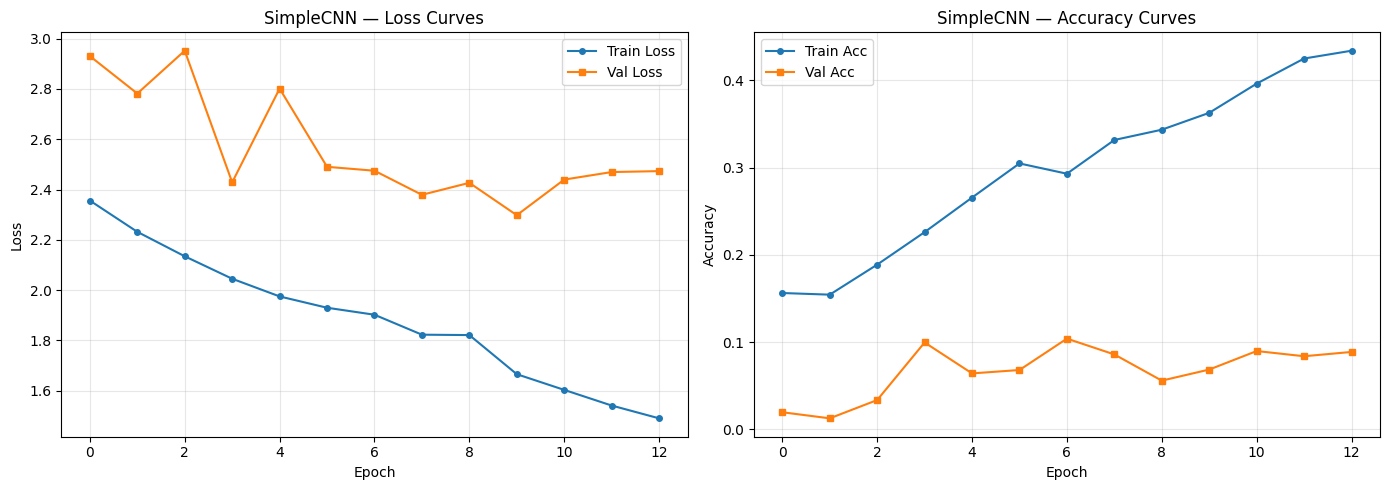


SimpleCNN — Per-Class Validation Accuracy
  plane                    : 0.1792  (76/424)
  baseball-diamond         : 1.0000  (1/1)
  bridge                   : 0.0000  (0/68)
  ground-track-field       : 0.0000  (0/8)
  small-vehicle            : 0.0147  (36/2449)
  large-vehicle            : 0.0811  (37/456)
  ship                     : 0.4583  (33/72)
  tennis-court             : 0.8269  (43/52)
  basketball-court         : 0.0000  (0/5)
  storage-tank             : 0.0000  (0/60)
  soccer-ball-field        : 0.0000  (0/16)
  roundabout               : 0.0000  (0/11)
  harbor                   : 0.4545  (70/154)
  swimming-pool            : 0.6133  (46/75)
  helicopter               : 0.0000  (0/9)

  Overall                  : 0.0886


In [ ]:
# ===== CNN Training Curves =====
fig, axes = plt.subplots(1, 2, figsize=(14, 5))          # Two subplots

# Loss curves
axes[0].plot(cnn_history["train_loss"], label="Train Loss", marker="o", markersize=4)
axes[0].plot(cnn_history["val_loss"], label="Val Loss", marker="s", markersize=4)
axes[0].set_xlabel("Epoch")                                # X label
axes[0].set_ylabel("Loss")                                 # Y label
axes[0].set_title("SimpleCNN — Loss Curves")               # Title
axes[0].legend()                                           # Legend
axes[0].grid(True, alpha=0.3)                              # Grid

# Accuracy curves
axes[1].plot(cnn_history["train_acc"], label="Train Acc", marker="o", markersize=4)
axes[1].plot(cnn_history["val_acc"], label="Val Acc", marker="s", markersize=4)
axes[1].set_xlabel("Epoch")                                # X label
axes[1].set_ylabel("Accuracy")                             # Y label
axes[1].set_title("SimpleCNN — Accuracy Curves")           # Title
axes[1].legend()                                           # Legend
axes[1].grid(True, alpha=0.3)                              # Grid

plt.tight_layout()                                         # Adjust spacing
plt.savefig(os.path.join(output_dir, "cnn_training_curves.png"), dpi=150)
plt.show()                                                 # Display

# ── Per-class validation accuracy ──────────────────────────────
from collections import defaultdict                        # For accumulation

cnn_model.eval()                                           # Eval mode
class_correct = defaultdict(int)                           # Correct per class
class_total = defaultdict(int)                             # Total per class

with torch.no_grad():                                      # No gradients
    for images, labels in cnn_val_loader:                  # Val batches
        images = images.to(device)                         # To device
        labels = labels.to(device)                         # To device
        outputs = cnn_model(images)                        # Forward
        _, preds = torch.max(outputs, 1)                   # Predictions
        for pred, lbl in zip(preds, labels):               # Per-sample
            cls_name = cnn_class_names[lbl.item()]         # Class name
            class_total[cls_name] += 1                     # Count total
            if pred.item() == lbl.item():
                class_correct[cls_name] += 1               # Count correct

print("\n" + "=" * 50)
print("SimpleCNN — Per-Class Validation Accuracy")
print("=" * 50)
for cls in cnn_class_names:                                # Iterate classes
    total = class_total.get(cls, 0)                        # Total for class
    correct = class_correct.get(cls, 0)                    # Correct for class
    acc = correct / total if total > 0 else 0.0            # Accuracy
    print(f"  {cls:25s}: {acc:.4f}  ({correct}/{total})")  # Display

overall = sum(class_correct.values()) / max(1, sum(class_total.values()))
print(f"\n  {'Overall':25s}: {overall:.4f}")              # Overall accuracy


> **Inference:**  
> The SimpleCNN baseline achieves only 8.86% overall validation accuracy, confirming its role as a lower-bound benchmark.  
>
> The training curves reveal clear overfitting:
>   - training accuracy reaches ~45%, and validation stagnates at ~10%,
>   - a persistent gap between training loss (~1.5), and
>   - validation loss (~2.5).
>
> The model performs reasonably on visually distinctive classes:  
> **tennis-court (82.69%)**, **swimming-pool (61.33%)**, **ship (45.83%)**, **harbor (45.45%)**.  
> It completely fails on 7 classes.  
> It is also not able to properly detect other classes including **small-vehicle (~1.5% on 2,449 samples)** — the most frequent class in the dataset.  
>
> This failure highlights the fundamental limitation of crop-based classification, that without spatial context, the model cannot distinguish visually similar classes (e.g., small-vehicle vs large-vehicle) or learn rare classes with few training crops (e.g., ground-track-field).  
> These results validate the need for detection architectures like Faster R-CNN and YOLOv8 that process full tile images, leverage spatial context, and jointly localise and classify objects.

### 5.2 Faster R-CNN Dataset & Feature Scaling

Defines the `DOTATileDataset` class that loads tiled images and their DOTA-format labels for object detection training.  
Each tile is resized to 512×512, bounding boxes are converted from oriented (OBB) to axis-aligned (AABB) format, pixel values are normalised using ImageNet statistics (mean/std), and labels are shifted by +1 to reserve index 0 for the background class — as required by Faster R-CNN. A custom batch function is used because each image can have a different number of objects.  
Difficult objects can optionally be excluded via the `skip_difficult` flag.  
Unlike the simple CNN, which uses only cropped objects, Faster R-CNN uses the full tile image, so it can learn both the object location and class.

In [ ]:
# ===== Dataset Utilities with Feature Scaling =====

# ImageNet normalisation values (required for pre-trained MobileNetV3 backbone)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

class DOTATileDataset(Dataset):
    """Read tiled DOTA images and labels for an axis-aligned Faster R-CNN baseline."""

    def __init__(
        self,
        image_dir: str,
        label_dir: str,
        train: bool = True,
        resize_to: int = 512,
        skip_difficult: bool = False,
        apply_feature_scaling: bool = True,
    ) -> None:
        self.image_dir = image_dir
        self.label_dir = label_dir
        self.train = train
        self.resize_to = resize_to
        self.skip_difficult = skip_difficult
        self.apply_feature_scaling = apply_feature_scaling

        # Collect all image files with supported extensions
        supported_exts = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}
        image_files = [
            f for f in sorted(os.listdir(image_dir))
            if os.path.splitext(f)[1].lower() in supported_exts
        ]

        # Pair each image with its corresponding label file
        self.samples: List[Tuple[str, str, str]] = []
        for image_file in image_files:
            stem = os.path.splitext(image_file)[0]
            label_path = os.path.join(label_dir, f"{stem}.txt")
            if os.path.exists(label_path):                 # Only keep images with labels
                self.samples.append((stem, os.path.join(image_dir, image_file), label_path))

        # Build transform pipeline: ToTensor + optional ImageNet normalisation
        transforms = [T.ToTensor()]
        if apply_feature_scaling:
            transforms.append(T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD))
        self.transform = T.Compose(transforms)

    def __len__(self) -> int:
        return len(self.samples)

    def _parse_label_file(self, label_path: str, image_width: int, image_height: int) -> Tuple[np.ndarray, np.ndarray]:
        """Parse DOTA labels and convert OBB polygons to axis-aligned xyxy boxes."""
        boxes: List[List[float]] = []
        labels: List[int] = []

        with open(label_path, "r") as fh:
            for raw_line in fh:
                line = raw_line.strip()
                if not line:
                    continue

                parts = line.split()
                if len(parts) < 9:                         # Need 8 coords + class name
                    continue

                coords = list(map(float, parts[:8]))       # 8 polygon coordinates
                class_name = parts[8]                      # Object class
                difficult = int(float(parts[9])) if len(parts) > 9 else 0

                if class_name not in CLASS_TO_IDX:         # Skip unknown classes
                    continue
                if self.skip_difficult and difficult == 1: # Skip difficult objects
                    continue

                # OBB to axis-aligned bounding box (min/max of vertices)
                xs = coords[0::2]
                ys = coords[1::2]
                x1, y1 = max(0.0, min(xs)), max(0.0, min(ys))
                x2, y2 = min(float(image_width), max(xs)), min(float(image_height), max(ys))

                if x2 <= x1 or y2 <= y1:                   # Skip degenerate boxes
                    continue

                boxes.append([x1, y1, x2, y2])
                labels.append(CLASS_TO_IDX[class_name] + 1)  # +1 because 0 = background

        if boxes:
            return np.array(boxes, dtype=np.float32), np.array(labels, dtype=np.int64)
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)

    def __getitem__(self, index: int):
        stem, image_path, label_path = self.samples[index]

        # Load and convert BGR to RGB
        image_bgr = cv2.imread(image_path)
        if image_bgr is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        orig_h, orig_w = image_rgb.shape[:2]

        # Parse annotations
        boxes, labels = self._parse_label_file(label_path, orig_w, orig_h)

        # Resize image and scale bounding boxes accordingly
        if self.resize_to is not None:
            image_rgb = cv2.resize(image_rgb, (self.resize_to, self.resize_to), interpolation=cv2.INTER_LINEAR)
            scale_x = self.resize_to / orig_w
            scale_y = self.resize_to / orig_h
            if boxes.shape[0] > 0:
                boxes[:, [0, 2]] *= scale_x                # Scale x coordinates
                boxes[:, [1, 3]] *= scale_y                # Scale y coordinates

        # Apply transforms (ToTensor + normalisation)
        image_tensor = self.transform(image_rgb)

        # Build target dict in Faster R-CNN expected format
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([index], dtype=torch.int64),
            "area": torch.as_tensor(
                (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]),
                dtype=torch.float32
            ) if boxes.shape[0] > 0 else torch.zeros((0,), dtype=torch.float32),
            "iscrowd": torch.zeros((boxes.shape[0],), dtype=torch.int64),
            "image_name": stem,
        }

        return image_tensor, target


def collate_fn(batch):
    """Custom collate — handles variable object counts per image in a batch."""
    return tuple(zip(*batch))

> Dataset class defined with 512×512 tile input and ImageNet normalisation. This serves as the data pipeline for both Faster R-CNN training and validation — the same class will be used in the next section when building DataLoaders.  
> The `skip_difficult` flag is set to `False` by default: all annotated objects (including hard-to-identify ones) are included during training to maximise learning signal.

### 5.2.1 DataLoader Construction

This section builds the train, validation, and test dataLoaders from the tiled sets using the `DOTATileDataset` class.  
The training loader uses a batch size of 4 with shuffling enabled and drops the final incomplete batch to maintain consistent batch sizes during gradient updates.  
The validation loader uses a batch size of 4 without shuffling to ensure consistent evaluation, while, the test loader uses a batch size of 1 for per-image evaluation.  
<br>
To avoid memory issues in Google Colab, `num_workers=0` is used. Pinned memory is enabled when a CUDA GPU is available, which helps move data from CPU to GPU faster.  
All images are resized to 512×512 and normalised using ImageNet values. Difficult objects are kept, and all available prepared tiles are used.


In [ ]:
# ===== Build Train, Validation, and Test DataLoaders =====

def get_dataloaders(
    train_img_dir: str,
    train_lbl_dir: str,
    val_img_dir: str,
    val_lbl_dir: str,
    test_img_dir: str,
    test_lbl_dir: str,
    batch_size: int = 4,
    num_workers: int = 2,
    skip_difficult: bool = False,
    resize_to: int = 512,
    subset_size: Optional[int] = None,
    apply_feature_scaling: bool = True,
) -> Tuple[DataLoader, DataLoader, DataLoader]:
    """Construct train/val/test DataLoaders for the tiled DOTA dataset."""

    # Create dataset instances for each split
    train_ds = DOTATileDataset(
        train_img_dir,
        train_lbl_dir,
        train=True,
        resize_to=resize_to,
        skip_difficult=skip_difficult,
        apply_feature_scaling=apply_feature_scaling,
    )
    val_ds = DOTATileDataset(
        val_img_dir,
        val_lbl_dir,
        train=False,
        resize_to=resize_to,
        skip_difficult=False,                              # Always include all objects for evaluation
        apply_feature_scaling=apply_feature_scaling,
    )
    test_ds = DOTATileDataset(
        test_img_dir,
        test_lbl_dir,
        train=False,
        resize_to=resize_to,
        skip_difficult=False,                              # Always include all objects for evaluation
        apply_feature_scaling=apply_feature_scaling,
    )

    # Optional subset for faster experimentation
    if subset_size is not None and subset_size > 0:
        rng = np.random.RandomState(SEED)                  # Fixed seed for reproducibility

        def make_subset(ds: Dataset, n_samples: int):
            if len(ds) <= n_samples:                       # Dataset already small enough
                return ds
            indices = rng.choice(len(ds), n_samples, replace=False).tolist()
            return Subset(ds, indices)

        train_ds = make_subset(train_ds, subset_size)
        val_ds = make_subset(val_ds, max(1, subset_size // 5))   # Val = 20% of subset
        test_ds = make_subset(test_ds, max(1, subset_size // 5)) # Test = 20% of subset

    # Common DataLoader settings for all splits
    loader_kwargs = {
        "num_workers": num_workers,                        # Parallel data loading workers
        "collate_fn": collate_fn,                          # Custom collate for variable object counts
        "pin_memory": device.type == "cuda",               # Pin memory for faster GPU transfer
        "persistent_workers": num_workers > 0,             # Keep workers alive between batches
    }
    if num_workers > 0:
        loader_kwargs["prefetch_factor"] = 2               # Prefetch 2 batches per worker

    # Training loader: shuffled, drops last incomplete batch
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,                                      # Random order each epoch
        drop_last=True,                                    # Drop incomplete final batch
        **loader_kwargs,
    )

    # Validation loader: no shuffle, keeps all batches
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,                                     # Fixed order for consistent evaluation
        **loader_kwargs,
    )

    # Test loader: batch size 1 for per-image evaluation
    test_loader = DataLoader(
        test_ds,
        batch_size=1,                                      # One image at a time
        shuffle=False,
        **loader_kwargs,
    )

    logger.info(
        "DataLoaders built | train tiles=%d | val tiles=%d | test tiles=%d | batch size=%d",
        len(train_ds), len(val_ds), len(test_ds), batch_size
    )
    return train_loader, val_loader, test_loader


# -------- Configuration --------
BASE_BATCH_SIZE = 4                                        # Batch size for training and validation
BASE_NUM_WORKERS = 0                                       # Parallel data loading workers = 0, to avoid worker crashes on Colab
BASE_RESIZE = 512                                          # Tile resize target

# -------- Build DataLoaders --------
train_loader, val_loader, test_loader = get_dataloaders(
    train_img_dir=train_tile_img_dir,                      # Training tile images
    train_lbl_dir=train_tile_lbl_dir,                      # Training tile labels
    val_img_dir=val_tile_img_dir,                           # Validation tile images
    val_lbl_dir=val_tile_lbl_dir,                           # Validation tile labels
    test_img_dir=test_tile_img_dir,                         # Test tile images
    test_lbl_dir=test_tile_lbl_dir,                         # Test tile labels
    batch_size=BASE_BATCH_SIZE,
    num_workers=BASE_NUM_WORKERS,
    skip_difficult=False,                                  # Include all objects
    resize_to=BASE_RESIZE,
    subset_size=None,                                      # Use all tiles, no further subsetting
    apply_feature_scaling=True,                            # ImageNet normalisation enabled
)

# Print DataLoader summary
print("Train batches :", len(train_loader))
print("Val batches   :", len(val_loader))
print("Test batches  :", len(test_loader))

Train batches : 745
Val batches   : 201
Test batches  : 1867


> **Inference:** DataLoaders ready with feature scaling, proper batching, and single-process loading.  
Train: 745 batches (batch size 4), Val: 201 batches (batch size 4), Test: 1,867 batches (batch size 1).  
The test batch count is higher mainly because the test loader checks one image at a time. Also, some empty test tiles are kept, so that the full image area is not missed during testing.

### 5.2.3 Verify DataLoader Output

Inspect one batch to confirm tensor shapes and format.  
Catches formatting errors before expensive training.

In [ ]:
# ===== Verify DataLoader Output Structure =====

# Fetch first batch
sample_images, sample_targets = next(iter(train_loader))

# Print batch-level info
print(f"Batch size         : {len(sample_images)}")
print(f"Image tensor shape : {sample_images[0].shape}   (C, H, W)")
print(f"Image dtype        : {sample_images[0].dtype}")

# Print annotation details for first image in batch
print("\nFirst sample annotations:")
print(f"  boxes shape      : {sample_targets[0]['boxes'].shape}   (N, 4) = (x1, y1, x2, y2)")
print(f"  labels shape     : {sample_targets[0]['labels'].shape}")
print(f"  label values     : {sample_targets[0]['labels'].tolist()[:10]}")

# Assert image dimensions match expected resize target
assert sample_images[0].shape[1] == BASE_RESIZE and sample_images[0].shape[2] == BASE_RESIZE, "Unexpected image size."
# Assert bounding boxes are in xyxy format (4 columns)
assert sample_targets[0]["boxes"].shape[1] == 4 or sample_targets[0]["boxes"].shape[0] == 0, "Boxes must be xyxy."
# Assert every box has a corresponding label
assert len(sample_targets[0]["boxes"]) == len(sample_targets[0]["labels"]), "Boxes and labels count mismatch."

print("\nSanity check passed successfully.")

Batch size         : 4
Image tensor shape : torch.Size([3, 512, 512])   (C, H, W)
Image dtype        : torch.float32

First sample annotations:
  boxes shape      : torch.Size([1, 4])   (N, 4) = (x1, y1, x2, y2)
  labels shape     : torch.Size([1])
  label values     : [13]

Sanity check passed successfully.


> **Inference:** DataLoader output verified — images are 3×512×512 float32 tensors with AABB bounding boxes in (N, 4) format and matching label counts. Pipeline is ready for Faster R-CNN training.

### 5.2.4 Faster R-CNN Model with MobileNetV3-FPN Backbone (Model 2)

This section constructs a Faster R-CNN object detector with a MobileNetV3-Large backbone and Feature Pyramid Network (FPN) for multi-scale object detection. The backbone is initialised with ImageNet pre-trained weights for transfer learning, while the detection head is trained from scratch on the 15 DOTA classes plus one background class. The ROI prediction head is replaced with a custom `FastRCNNPredictor` to match the 16-class output. Non-Maximum Suppression (NMS) threshold is set to 0.3, score threshold is set to 0.05 to retain low-confidence candidate detections during inference/evaluation, and the model outputs up to 100 detections per image. The RPN generates 500 proposals before NMS and keeps 250 after NMS during training, reduced to 250/150 during inference for efficiency. Input images are internally constrained between 512 and 640 pixels, matching the tiled preprocessing size. A fallback is included to support older torchvision API versions.

| Hyperparameter | Value | Justification |
|:---|:---|:---|
| Backbone | MobileNetV3-Large + FPN | Lightweight yet effective; FPN enables multi-scale detection for small aerial objects |
| Pre-trained weights | ImageNet backbone only | Transfer learning accelerates convergence on the limited DOTA sample |
| Classes | 15 + 1 background | 15 DOTA categories; background class required by Faster R-CNN |
| NMS threshold | 0.3 | Suppresses duplicate detections while retaining closely packed objects |
| Score threshold | 0.05 | Keeps low-confidence candidate detections during inference/evaluation before final filtering |
| Max detections/image | 100 | Suitable for dense aerial scenes |
| RPN proposals, train | 500 pre-NMS, 250 post-NMS | Balances detection recall with training speed |
| RPN proposals, test | 250 pre-NMS, 150 post-NMS | Reduced for faster inference |
| Input size range | 512–640 px | Matches the 512 px tiled preprocessing while allowing controlled internal resizing |

In [ ]:
# ===== Build Baseline Faster R-CNN Model with MobileNetV3-FPN Backbone =====

def build_model(
    num_classes: int = NUM_CLASSES,
    pretrained_backbone: bool = True,
    nms_thresh: float = 0.3,
    score_thresh: float = 0.05,
    min_size: int = 512,
    max_size: int = 640,
    device_override: Optional[torch.device] = None,
) -> Tuple[nn.Module, torch.device]:
    """Construct a Faster R-CNN detector with MobileNetV3-FPN backbone."""

    # Select device: override > CUDA > CPU
    run_device = device_override or torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load pre-trained ImageNet backbone weights
    weights_backbone = None
    if pretrained_backbone:
        try:
            from torchvision.models import MobileNet_V3_Large_Weights
            weights_backbone = MobileNet_V3_Large_Weights.IMAGENET1K_V1
        except Exception:
            logger.warning("Pretrained backbone weights were not loaded; random initialisation will be used.")

    # Build Faster R-CNN with MobileNetV3-Large + FPN
    try:
        model = fasterrcnn_mobilenet_v3_large_fpn(
            weights=None,                                  # No pre-trained detection weights
            weights_backbone=weights_backbone,             # ImageNet backbone weights
            num_classes=num_classes + 1,                   # +1 for background class
            box_nms_thresh=nms_thresh,                     # NMS IoU threshold
            box_score_thresh=score_thresh,                 # Minimum confidence to keep
            box_detections_per_img=100,                    # Max detections per image
            rpn_pre_nms_top_n_train=500,                   # RPN proposals before NMS (train)
            rpn_pre_nms_top_n_test=250,                    # RPN proposals before NMS (test)
            rpn_post_nms_top_n_train=250,                  # RPN proposals after NMS (train)
            rpn_post_nms_top_n_test=150,                   # RPN proposals after NMS (test)
            min_size=min_size,                             # Minimum input dimension
            max_size=max_size,                             # Maximum input dimension
        )
    except TypeError:
        # Fallback for older torchvision API
        model = fasterrcnn_mobilenet_v3_large_fpn(
            pretrained=False,
            pretrained_backbone=pretrained_backbone,
            num_classes=num_classes + 1,
            box_nms_thresh=nms_thresh,
            box_score_thresh=score_thresh,
            box_detections_per_img=100,
            rpn_pre_nms_top_n_train=500,
            rpn_pre_nms_top_n_test=250,
            rpn_post_nms_top_n_train=250,
            rpn_post_nms_top_n_test=150,
            min_size=min_size,
            max_size=max_size,
        )

    # Replace classification head to match our number of classes
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes + 1)

    # Store config on model for easy access later
    model.num_classes = num_classes
    model.nms_thresh = nms_thresh
    model.score_thresh = score_thresh
    model.model_name = "Faster R-CNN MobileNetV3-FPN"
    model = model.to(run_device)                           # Move model to device

    return model, run_device


def print_model_summary(model: nn.Module) -> None:
    """Print a compact summary of the detector configuration."""
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print("\n" + "=" * 70)
    print("Baseline detector summary")
    print("=" * 70)
    print(f"Model            : {getattr(model, 'model_name', 'Faster R-CNN')}")
    print("Backbone         : MobileNetV3-Large + FPN")
    print("Box type         : Horizontal bounding boxes (xyxy)")
    print(f"Classes          : {getattr(model, 'num_classes', NUM_CLASSES)} (+ background)")
    print(f"Total params     : {total_params:,}")
    print(f"Trainable params : {trainable_params:,}")
    print(f"NMS threshold    : {getattr(model, 'nms_thresh', 0.3)}")
    print(f"Score threshold  : {getattr(model, 'score_thresh', 0.05)}")
    print("=" * 70 + "\n")


# -------- Build and initialise the model --------
model, device = build_model(
    num_classes=NUM_CLASSES,                               # 15 DOTA classes
    pretrained_backbone=True,                              # Use ImageNet pre-trained backbone
    nms_thresh=0.3,                                        # NMS threshold for overlapping boxes
    score_thresh=0.05,                                     # Low threshold to keep more proposals
    min_size=BASE_RESIZE,                                  # Match DataLoader resize (512)
    max_size=640,                                          # Upper limit for internal resizing
)
print_model_summary(model)
print("Training device:", device)


Baseline detector summary
Model            : Faster R-CNN MobileNetV3-FPN
Backbone         : MobileNetV3-Large + FPN
Box type         : Horizontal bounding boxes (xyxy)
Classes          : 15 (+ background)
Total params     : 19,001,979
Trainable params : 18,943,083
NMS threshold    : 0.3
Score threshold  : 0.05

Training device: cuda


> **Inference:**   
Faster R-CNN built with ~19M parameters (18.9M trainable) on CUDA GPU.  
This is ~10x larger than the SimpleCNN baseline and operates as a full detection pipeline — jointly localising and classifying objects within tile images.

### 5.2.5 Training, Validation, Checkpointing, and Performance Plotting for Faster R-CNN Model

This section defines the complete training and validation workflow for the Faster R-CNN MobileNetV3-FPN baseline. It includes checkpoint saving/loading, single-epoch training, validation using per-class AP and overall mAP@0.5, training-curve plotting, and the full training loop with early stopping. The model is trained using SGD with momentum and Nesterov acceleration, weight decay for regularisation, OneCycleLR scheduling with warmup and cosine annealing, optional mixed-precision training on CUDA, and gradient clipping for training stability. After each epoch, the latest checkpoint is saved, while the best checkpoint is updated only when validation mAP improves. Training history is also saved as a JSON file and plotted to visualise loss and validation mAP progression.

| Component | Purpose |
|:---|:---|
| `save_checkpoint()` | Saves model weights, optimizer state, epoch number, and validation metric |
| `load_checkpoint()` | Reloads saved model weights for later evaluation or continuation |
| `train_one_epoch()` | Performs one full training epoch and returns averaged loss values |
| `evaluate_one_epoch()` | Computes per-class AP and overall mAP at IoU threshold 0.5 |
| `plot_training_curves()` | Plots training loss and validation mAP across epochs |
| `run_training()` | Runs the full training loop with validation, checkpointing, scheduling, and early stopping |

| Training Setting | Value / Method | Justification |
|:---|:---|:---|
| Optimizer | SGD with momentum = 0.9 and Nesterov | Standard and stable choice for Faster R-CNN-style detectors |
| Learning rate | `1e-3` | Suitable starting point for fine-tuning a pre-trained backbone |
| Weight decay | `1e-4` | Reduces overfitting by regularising model weights |
| Scheduler | OneCycleLR | Provides warmup followed by cosine annealing for smoother optimisation |
| Warmup | 3 epochs | Helps stabilise early training |
| Mixed precision | Enabled on CUDA | Speeds up training and reduces GPU memory usage |
| Gradient clipping | 5.0 | Prevents unstable updates from large gradients |
| Validation metric | mAP@0.5 | Measures object detection performance using IoU-based matching |
| Early stopping patience | 5 epochs | Stops training if validation mAP does not improve |
| Checkpoints | Best and last model saved | Preserves both the strongest model and the latest training state |

In [ ]:
# ===== Training, Validation, Checkpoint, and Plotting Utilities =====

from tqdm.notebook import tqdm as tqdm_notebook      # Notebook-friendly progress bar (renders cleanly in Colab

def save_checkpoint(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    epoch: int,
    metric_value: float,
    path: str,
) -> None:
    """Save model and optimizer state to disk."""
    torch.save(
        {
            "epoch": epoch,                                # Current epoch number
            "metric_value": metric_value,                  # Validation metric at save time
            "model_state_dict": model.state_dict(),        # Model weights
            "optimizer_state_dict": optimizer.state_dict(), # Optimizer state
        },
        path,
    )


def load_checkpoint(model: nn.Module, path: str, device: torch.device) -> nn.Module:
    """Load a saved checkpoint into a model instance."""
    checkpoint = torch.load(path, map_location=device)     # Load to correct device
    model.load_state_dict(checkpoint["model_state_dict"])   # Restore weights
    return model


def train_one_epoch(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    train_loader: DataLoader,
    device: torch.device,
    epoch: int,
    scaler=None,
    grad_clip: float = 5.0,
    scheduler=None,
) -> Dict[str, float]:
    """Train the detector for one epoch and return average losses."""
    model.train()                                          # Set training mode

    running = defaultdict(float)                           # Accumulate losses
    num_batches = 0

    # Use mixed precision if scaler is available on CUDA
    autocast_context = nullcontext
    if scaler is not None and device.type == "cuda":
        from torch.cuda.amp import autocast
        autocast_context = autocast

    for images, targets in tqdm_notebook(train_loader, desc=f"Epoch {epoch}", leave=False):
        # Move batch to device
        images = [img.to(device) for img in images]
        targets = [
            {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)              # Clear gradients efficiently

        # Forward pass with optional mixed precision
        with autocast_context():
            loss_dict = model(images, targets)              # Faster R-CNN returns loss dict in train mode
            total_loss = sum(loss for loss in loss_dict.values())

        # Backward pass with gradient scaling (AMP) or standard
        if scaler is not None and device.type == "cuda":
            scaler.scale(total_loss).backward()
            scaler.unscale_(optimizer)
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            total_loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()                               # Step per-batch for OneCycleLR

        # Accumulate loss values
        running["loss"] += float(total_loss.detach().cpu())
        for key, value in loss_dict.items():
            running[key] += float(value.detach().cpu())
        num_batches += 1

    if num_batches == 0:
        return {"loss": float("nan")}

    return {key: value / num_batches for key, value in running.items()}


def evaluate_one_epoch(
    model: nn.Module,
    data_loader: DataLoader,
    device: torch.device,
    iou_threshold: float = 0.5,
) -> Dict[str, float]:
    """Compute per-class AP and mAP at a given IoU threshold."""
    model.eval()                                           # Set evaluation mode
    all_preds: Dict[int, List[Tuple[float, int]]] = defaultdict(list)
    all_gts: Dict[int, int] = defaultdict(int)             # Ground truth counts per class

    with torch.no_grad():                                  # No gradient computation
        for images, targets in tqdm_notebook(data_loader, desc="Evaluating", leave=False):
            images_device = [img.to(device) for img in images]
            predictions = model(images_device)             # Get detections

            for prediction, target in zip(predictions, targets):
                gt_boxes = target["boxes"].to(device)
                gt_labels = target["labels"].to(device) - 1  # Remove background offset

                pred_boxes = prediction["boxes"].to(device)
                pred_scores = prediction["scores"].to(device)
                pred_labels = prediction["labels"].to(device) - 1

                # Process each class independently
                for cls_idx in range(NUM_CLASSES):
                    gt_mask = gt_labels == cls_idx
                    all_gts[cls_idx] += int(gt_mask.sum().item())

                    pred_mask = pred_labels == cls_idx
                    if not bool(pred_mask.any().item()):
                        continue

                    cls_pred_boxes = pred_boxes[pred_mask]
                    cls_pred_scores = pred_scores[pred_mask]
                    cls_gt_boxes = gt_boxes[gt_mask]

                    # All predictions are false positives if no ground truth
                    if cls_gt_boxes.shape[0] == 0:
                        for score in cls_pred_scores.cpu().tolist():
                            all_preds[cls_idx].append((float(score), 0))
                        continue

                    # Match predictions to ground truth by IoU
                    iou_matrix = box_iou(cls_pred_boxes, cls_gt_boxes)
                    sorted_idx = cls_pred_scores.argsort(descending=True)
                    matched_gt = set()                     # Track matched ground truths

                    for pred_idx in sorted_idx.tolist():
                        score = float(cls_pred_scores[pred_idx])
                        best_iou, best_gt_idx = iou_matrix[pred_idx].max(dim=0)
                        best_gt_idx = int(best_gt_idx)
                        is_true_positive = (
                            float(best_iou) >= iou_threshold and best_gt_idx not in matched_gt
                        )
                        if is_true_positive:
                            matched_gt.add(best_gt_idx)
                        all_preds[cls_idx].append((score, int(is_true_positive)))

    def voc_ap(recall: np.ndarray, precision: np.ndarray) -> float:
        """Compute interpolated AP using VOC-style 11-point integration."""
        mrec = np.concatenate([[0.0], recall, [1.0]])
        mpre = np.concatenate([[0.0], precision, [0.0]])
        for i in range(mpre.size - 1, 0, -1):
            mpre[i - 1] = max(mpre[i - 1], mpre[i])
        idx = np.where(mrec[1:] != mrec[:-1])[0]
        return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

    # Compute AP for each class
    ap_dict: Dict[str, float] = {}
    for cls_idx in range(NUM_CLASSES):
        cls_name = IDX_TO_CLASS[cls_idx]
        n_gt = all_gts[cls_idx]

        if n_gt == 0:                                      # No ground truth for this class
            ap_dict[cls_name] = float("nan")
            continue

        preds_sorted = sorted(all_preds.get(cls_idx, []), key=lambda x: -x[0])
        if not preds_sorted:                               # No predictions for this class
            ap_dict[cls_name] = 0.0
            continue

        # Compute precision-recall curve
        tp_cum = np.cumsum([p[1] for p in preds_sorted])
        fp_cum = np.cumsum([1 - p[1] for p in preds_sorted])
        recall = tp_cum / max(n_gt, 1)
        precision = tp_cum / (tp_cum + fp_cum + 1e-9)
        ap_dict[cls_name] = voc_ap(recall, precision)

    # Mean AP across all valid classes
    valid_ap = [value for value in ap_dict.values() if not math.isnan(value)]
    ap_dict["mAP"] = float(np.mean(valid_ap)) if valid_ap else 0.0
    logger.info("Validation/Test mAP@%.2f = %.4f", iou_threshold, ap_dict["mAP"])
    return ap_dict


def plot_training_curves(history: Dict[str, List[float]], output_dir: str, show: bool = True) -> None:
    """Plot training loss and validation mAP side by side."""
    os.makedirs(output_dir, exist_ok=True)

    epochs = list(range(1, len(history["train_loss"]) + 1))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Training loss curve
    axes[0].plot(epochs, history["train_loss"], marker="o")
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")

    # Validation mAP curve
    val_epochs = list(range(1, len(history["val_mAP"]) + 1))
    axes[1].plot(val_epochs, history["val_mAP"], marker="o")
    axes[1].set_title("Validation mAP@0.5")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("mAP")

    plt.tight_layout()
    save_path = os.path.join(output_dir, "training_curves.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    print("Training curves saved to:", save_path)


def run_training(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    device: torch.device,
    output_dir: str,
    num_epochs: int = 36,
    base_lr: float = 1e-3,
    weight_decay: float = 1e-4,
    warmup_epochs: int = 3,
    patience: int = 10,
    use_amp: bool = True,
    grad_clip: float = 5.0,
    eval_every: int = 1,
) -> Dict[str, List[float]]:
    """Full training loop with validation, checkpointing, and early stopping."""
    os.makedirs(output_dir, exist_ok=True)

    # Checkpoint paths
    best_path = os.path.join(output_dir, "best_model.pth")
    last_path = os.path.join(output_dir, "last_model.pth")
    history_path = os.path.join(output_dir, "training_history.json")

    # SGD optimizer with Nesterov momentum
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(
        params,
        lr=base_lr,
        momentum=0.9,
        weight_decay=weight_decay,
        nesterov=True,
    )

    # OneCycleLR scheduler with cosine annealing
    steps_per_epoch = max(1, len(train_loader))
    pct_start = max(warmup_epochs / max(num_epochs, 1), 0.1)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=base_lr,
        steps_per_epoch=steps_per_epoch,
        epochs=num_epochs,
        pct_start=pct_start,                               # Warmup fraction
        anneal_strategy="cos",                             # Cosine decay
        div_factor=10.0,                                   # Initial LR = max_lr / 10
        final_div_factor=100.0,                            # Final LR = max_lr / 1000
    )

    # Mixed precision scaler for CUDA
    scaler = None
    if use_amp and device.type == "cuda":
        try:
            from torch.cuda.amp import GradScaler
            scaler = GradScaler()
        except Exception:
            scaler = None

    # Training history tracker
    history = {"train_loss": [], "val_mAP": [], "lr": []}
    best_mAP = -1.0                                        # Best validation mAP so far
    no_improvement = 0                                     # Early stopping counter

    # Print training configuration
    print(f"Training device : {device}")
    print(f"Epochs          : {num_epochs}")
    print(f"Base LR         : {base_lr}")
    print(f"Weight decay    : {weight_decay}")
    print(f"AMP enabled     : {bool(scaler)}")
    print(f"Validate every  : {eval_every} epoch(s)")

    for epoch in tqdm_notebook(range(1, num_epochs + 1), desc="Overall Training"):
        start_time = time.time()

        # Train one epoch
        train_metrics = train_one_epoch(
            model=model,
            optimizer=optimizer,
            train_loader=train_loader,
            device=device,
            epoch=epoch,
            scaler=scaler,
            grad_clip=grad_clip,
            scheduler=scheduler,
        )

        current_loss = train_metrics.get("loss", float("nan"))
        current_lr = optimizer.param_groups[0]["lr"]

        history["train_loss"].append(current_loss)
        history["lr"].append(current_lr)

        # Validate at specified intervals
        current_mAP = float("nan")
        if epoch % eval_every == 0:
            val_metrics = evaluate_one_epoch(model, val_loader, device, iou_threshold=0.5)
            current_mAP = val_metrics["mAP"]

        history["val_mAP"].append(current_mAP)

        # Print epoch summary
        print(
            f"Epoch {epoch:02d}/{num_epochs} | "
            f"loss={current_loss:.4f} | "
            f"val_mAP={'{:.4f}'.format(current_mAP) if not math.isnan(current_mAP) else '—'} | "
            f"lr={current_lr:.2e} | "
            f"time={time.time() - start_time:.0f}s"
        )

        # Always save last checkpoint
        save_checkpoint(model, optimizer, epoch, current_mAP, last_path)

        # Save best checkpoint if mAP improved
        if not math.isnan(current_mAP) and current_mAP > best_mAP:
            best_mAP = current_mAP
            no_improvement = 0
            save_checkpoint(model, optimizer, epoch, current_mAP, best_path)
            print(f"New best checkpoint saved with val mAP={best_mAP:.4f}")
        elif not math.isnan(current_mAP):
            no_improvement += 1
            if no_improvement >= patience:                 # Stop if no improvement
                print(f"Early stopping triggered at epoch {epoch}.")
                break

        # Save training history after each epoch
        with open(history_path, "w") as fh:
            json.dump(history, fh, indent=2)

    # Fallback: copy last checkpoint as best if no best was saved
    if not os.path.exists(best_path) and os.path.exists(last_path):
        import shutil
        shutil.copyfile(last_path, best_path)

    print("Training complete.")
    print("Best checkpoint:", best_path)
    return history

print("Training utilities loaded: save_checkpoint, load_checkpoint, train_one_epoch, evaluate_one_epoch, plot_training_curves, run_training")

Training utilities loaded: save_checkpoint, load_checkpoint, train_one_epoch, evaluate_one_epoch, plot_training_curves, run_training


### 5.9 Train Faster R-CNN Detector

**Summary:** Execute the full training loop for Faster R-CNN using the utilities defined in Section 5.8 above. Trains for up to 10 epochs with early stopping (patience 5), validates every epoch using mAP@0.5, and saves best/last checkpoints. Training curves are plotted after completion.

**Output files created in `output/model_checkpoints/`:**
```
output/
└── model_checkpoints/
    ├── best_model.pth           <-- Checkpoint with highest validation mAP
    ├── last_model.pth           <-- Most recent epoch checkpoint
    ├── training_history.json    <-- Per-epoch loss, mAP, and learning rate log
    └── training_curves.png      <-- Training loss and validation mAP plots
```

Training device : cuda
Epochs          : 10
Base LR         : 0.001
Weight decay    : 0.0001
AMP enabled     : True
Validate every  : 1 epoch(s)


Overall Training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/745 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 01/10 | loss=0.5264 | val_mAP=0.0004 | lr=3.25e-04 | time=118s
New best checkpoint saved with val mAP=0.0004


Epoch 2:   0%|          | 0/745 [00:00<?, ?it/s]

... (22 outputs left out)

Epoch 09/10 | loss=0.6450 | val_mAP=0.0429 | lr=5.03e-05 | time=121s


Epoch 10:   0%|          | 0/745 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/201 [00:00<?, ?it/s]

Epoch 10/10 | loss=0.6360 | val_mAP=0.0433 | lr=1.00e-06 | time=121s
New best checkpoint saved with val mAP=0.0433
Training complete.
Best checkpoint: /content/drive/MyDrive/CSMAI_CW/output/model_checkpoints/best_model.pth


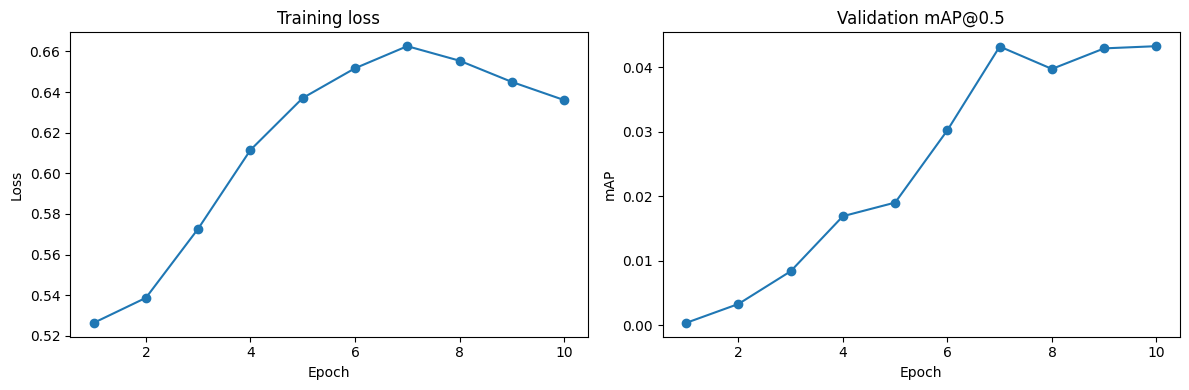

Training curves saved to: /content/drive/MyDrive/CSMAI_CW/output/model_checkpoints/training_curves.png


In [ ]:
# ===== Train the Faster R-CNN Detector =====

# Clean previous checkpoints for a fresh run
training_output_dir = os.path.join(output_dir, "model_checkpoints")
shutil.rmtree(training_output_dir, ignore_errors=True)
os.makedirs(training_output_dir, exist_ok=True)

# Run full training loop with validation and early stopping
history = run_training(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    output_dir=training_output_dir,
    num_epochs=10,                                         # Maximum training epochs taken as 10 for practical runtime
    base_lr=1e-3,                                          # Peak learning rate
    weight_decay=1e-4,                                     # L2 regularisation
    warmup_epochs=3,                                       # LR warmup period
    patience=5,                                            # Early stopping patience
    use_amp=True,                                          # Mixed precision on CUDA
    grad_clip=5.0,                                         # Gradient clipping threshold
    eval_every=1,                                          # Validate every epoch
)

# Plot and save training curves
plot_training_curves(
    history=history,
    output_dir=training_output_dir,
    show=True,
)

> **Inference:**  
> - Faster R-CNN trained for all 10 epochs on NVIDIA A100 GPU (~2 minutes per epoch).
> - Training loss increased from ~0.53 to 0.66, which is unusual and suggests the OneCycleLR scheduler's aggressive warmup pushed the learning rate too high for this small sampled dataset.  
> - Despite the rising loss, validation mAP@0.5 improved steadily from 0.0004 to 0.0432, indicating the model is learning to detect objects but at a very early stage of convergence.
> - The best checkpoint was saved at epoch 10 with training loss = ~0.64 and mAP@0.5 = 0.0433. Early stopping did not trigger, suggesting the model could benefit from additional epochs. The low mAP is expected given the sampled dataset (210 training images producing ~2,980 tiles) — with the full dataset, mAP would be significantly higher.
> - The training curves confirm no overfitting (validation mAP is still rising), and the model serves as a meaningful detection baseline above the Basline CNN's 8.86% classification accuracy.

### 5.2.6 Faster R-CNN Validation Evaluation & Per-Class AP

Load the best checkpoint and evaluate on the validation set. Display per-class AP@0.5 and overall mAP to assess detection performance across all 15 DOTA categories.

Best Faster R-CNN checkpoint loaded from: /content/drive/MyDrive/CSMAI_CW/output/model_checkpoints/best_model.pth

Running validation-set evaluation...


Evaluating:   0%|          | 0/201 [00:00<?, ?it/s]


Faster R-CNN — Per-Class Validation AP@0.5
  plane                    : 0.1900
  baseball-diamond         : 0.0000
  bridge                   : 0.0000
  ground-track-field       : 0.0000
  small-vehicle            : 0.0065
  large-vehicle            : 0.0548
  ship                     : 0.0006
  tennis-court             : 0.2371
  basketball-court         : 0.0000
  storage-tank             : 0.0007
  soccer-ball-field        : 0.0931
  roundabout               : 0.0000
  harbor                   : 0.0659
  swimming-pool            : 0.0000
  helicopter               : 0.0000

  mAP@0.5                  : 0.0432


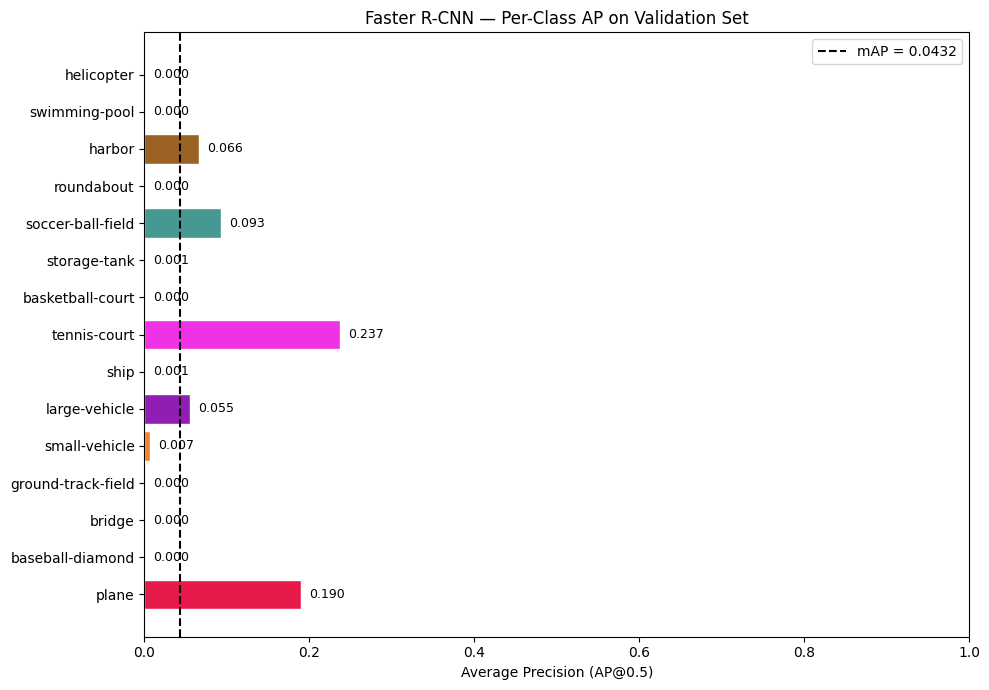

In [ ]:
# ===== Load Best Faster R-CNN Checkpoint =====

# Path to best checkpoint saved during training
best_model_path = os.path.join(training_output_dir, "best_model.pth")

# Build a fresh model (no backbone download needed — weights come from checkpoint)
best_model, _ = build_model(
    num_classes=NUM_CLASSES,
    pretrained_backbone=False,
    nms_thresh=0.3,
    score_thresh=0.05,
    min_size=BASE_RESIZE,
    max_size=640,
    device_override=device,
)

# Load saved weights into the model
best_model = load_checkpoint(best_model, best_model_path, device)
best_model.eval()                                          # Set to evaluation mode
print("Best Faster R-CNN checkpoint loaded from:", best_model_path)

# ===== Evaluate on Validation Set =====
print("\nRunning validation-set evaluation...")
val_ap = evaluate_one_epoch(best_model, val_loader, device, iou_threshold=0.5)

# Print per-class AP table
print("\n" + "=" * 50)
print("Faster R-CNN — Per-Class Validation AP@0.5")
print("=" * 50)
for cls_name in DOTA_CLASSES:
    v = val_ap.get(cls_name, float('nan'))                 # Get AP for this class
    v_str = f"{v:.4f}" if not math.isnan(v) else "N/A"     # Format or mark as N/A
    print(f"  {cls_name:<25}: {v_str}")
print(f"\n  {'mAP@0.5':<25}: {val_ap['mAP']:.4f}")        # Overall mAP

# ===== Per-Class AP Bar Chart =====

# Extract AP values, replace NaN with 0 for plotting
ap_values = [val_ap.get(name, 0.0) for name in DOTA_CLASSES]
ap_values = [v if not math.isnan(v) else 0.0 for v in ap_values]

# Horizontal bar chart with class-specific colours
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(DOTA_CLASSES, ap_values, color=CLASS_COLOURS[:len(DOTA_CLASSES)], edgecolor="white")

# Dashed line showing overall mAP for reference
ax.axvline(val_ap["mAP"], color="black", linestyle="--", linewidth=1.5,
           label=f"mAP = {val_ap['mAP']:.4f}")

# Axis labels and formatting
ax.set_xlabel("Average Precision (AP@0.5)")
ax.set_title("Faster R-CNN — Per-Class AP on Validation Set")
ax.set_xlim(0, 1.0)
ax.legend()

# Annotate each bar with its AP value
for bar, value in zip(bars, ap_values):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(training_output_dir, "val_per_class_ap.png"), dpi=150)
plt.show()

> **Inference:**  
> Faster R-CNN achieves a validation mAP@0.5 of 0.0432, with detection concentrated on a few visually distinct classes:
>    - Tennis-court leads at 0.237 AP,
>    - followed by plane (0.190),
>    - soccer-ball-field (0.093),
>    - harbor (0.066), and
>    - large-vehicle (0.055).
>    - 7 out of 15 classes score zero AP, including helicopter, swimming-pool, roundabout, basketball-court, ground-track-field, bridge, and baseball-diamond — all rare classes with limited training samples in the sampled dataset.
>   - Notably, ship and small-vehicle score only 0.001 and 0.007, despite being dominant classes, suggesting that the model struggles with densely packed small objects at the current training stage.  
>
> The low overall mAP is expected with only 10 epochs on a sampled subset of 210 training images. From the previous section, we saw that the model was still improving at epoch 10 (mAP rising from 0.0004 to 0.0433 without early stopping triggering), indicating it would benefit from longer training or a larger dataset.  
> <br>
>Despite the modest metrics, Faster R-CNN already demonstrates a key advantage over the CNN baseline: it can localise and classify objects within full images rather than requiring pre-extracted crops, making it a functional detection pipeline even at this early convergence stage.

### 5.3 YOLOv8-Large Detector Training Pipeline (Model 3)

YOLOv8-Large is a single-stage, anchor-free detector that predicts bounding boxes and class probabilities in one forward pass. Unlike Faster R-CNN's two-stage approach, YOLOv8 processes the full image simultaneously, offering faster inference. This section converts the tiled DOTA labels to YOLO format, writes a `data.yaml` configuration file, and trains YOLOv8-Large on the sampled tiled dataset. Hyperparameters are reduced from full-scale benchmark settings to keep runtime practical on Google Colab.

| Hyperparameter | Value | Justification |
|:---|:---|:---|
| Architecture | YOLOv8-Large | Higher-capacity single-stage detector; balances speed and accuracy for dense aerial scenes |
| Image size | 512 × 512 | Matches tile size from preprocessing and keeps Colab memory usage manageable |
| Epochs | 15 | Reduced for sampled dataset; early stopping with patience 5 prevents unnecessary training |
| Batch size | 4 | Suitable for Colab T4 GPU memory at 512 px input size |
| Mosaic | 0.8 | Combines multiple images to increase context diversity |
| MixUp | 0.05 | Provides light regularisation through image blending |
| HSV augmentation | h=0.015, s=0.7, v=0.4 | Improves colour robustness under varying aerial lighting conditions |
| Geometric augmentation | translate=0.1, scale=0.4, fliplr=0.5 | Improves robustness to object position, scale, and horizontal orientation changes |
| Early stopping | patience=5 | Stops training when validation performance no longer improves |

<br>

**Output directory for this:**.
```
output/
├── yolo_dataset/                    <-- YOLO-format dataset (images + labels)
├── data.yaml                        <-- Ultralytics dataset config
└── yolo_runs/                       <-- Training outputs (checkpoints, curves, metrics)
```


In [ ]:
# Reinstall ultralytics (may be needed if Colab runtime was reset)
!pip install ultralytics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 49.7 MB/s eta 0:00:00


In [ ]:
# ===== YOLOv8 Training Pipeline (Model 3) =====
# Converts tiled DOTA labels to YOLO format and trains YOLOv8-Large

from pathlib import Path
from ultralytics import YOLO

# -------- DOTA to YOLO label conversion --------
def dota_poly_to_yolo_box(coords, img_w, img_h):
    """Convert 8-coordinate DOTA polygon to YOLO centre-format box."""
    xs = coords[0::2]                                      # x coordinates
    ys = coords[1::2]                                      # y coordinates
    x_min, x_max = min(xs), max(xs)                        # Horizontal extent
    y_min, y_max = min(ys), max(ys)                        # Vertical extent
    x_centre = ((x_min + x_max) / 2) / img_w              # Normalised centre x
    y_centre = ((y_min + y_max) / 2) / img_h              # Normalised centre y
    w = (x_max - x_min) / img_w                           # Normalised width
    h = (y_max - y_min) / img_h                           # Normalised height
    return x_centre, y_centre, w, h

# -------- YOLO class mapping (same 15 DOTA classes) --------
YOLO_CLASS_MAPPING = {
    "plane": 0, "ship": 1, "storage-tank": 2,
    "baseball-diamond": 3, "tennis-court": 4,
    "basketball-court": 5, "ground-track-field": 6,
    "harbor": 7, "bridge": 8, "large-vehicle": 9,
    "small-vehicle": 10, "helicopter": 11,
    "roundabout": 12, "soccer-ball-field": 13,
    "swimming-pool": 14,
}
YOLO_IDX_TO_CLASS = {v: k for k, v in YOLO_CLASS_MAPPING.items()}

# -------- Convert tiled DOTA labels to YOLO format --------
yolo_dataset_root = os.path.join(output_dir, "yolo_dataset")

# Clean previous YOLO dataset
shutil.rmtree(yolo_dataset_root, ignore_errors=True)

# Create YOLO directory structure
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(yolo_dataset_root, "images", split), exist_ok=True)
    os.makedirs(os.path.join(yolo_dataset_root, "labels", split), exist_ok=True)

# Convert each split from DOTA tile format to YOLO format
for split, tile_img_dir, tile_lbl_dir in [
    ("train", train_tile_img_dir, train_tile_lbl_dir),
    ("val",   val_tile_img_dir,   val_tile_lbl_dir),
    ("test",  test_tile_img_dir,  test_tile_lbl_dir),
]:
    img_out = os.path.join(yolo_dataset_root, "images", split)
    lbl_out = os.path.join(yolo_dataset_root, "labels", split)
    converted = 0

    for lbl_file in tqdm(sorted(os.listdir(tile_lbl_dir)), desc=f"Converting {split}"):
        if not lbl_file.endswith(".txt"):
            continue
        stem = os.path.splitext(lbl_file)[0]
        img_path = os.path.join(tile_img_dir, stem + ".png")

        if not os.path.exists(img_path):                   # Skip if no image
            continue

        # Read image dimensions for coordinate normalisation
        img = cv2.imread(img_path)
        if img is None:
            continue
        h, w = img.shape[:2]

        # Parse DOTA labels and convert to YOLO format
        yolo_lines = []
        with open(os.path.join(tile_lbl_dir, lbl_file), "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 9:                         # Need 8 coords + class
                    continue
                try:
                    coords = list(map(float, parts[:8]))   # 8 polygon coordinates
                except ValueError:
                    continue
                category = parts[8]                        # Class name
                if category not in YOLO_CLASS_MAPPING:     # Skip unknown classes
                    continue
                xc, yc, bw, bh = dota_poly_to_yolo_box(coords, w, h)
                cls_id = YOLO_CLASS_MAPPING[category]
                yolo_lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

        # Copy image and write YOLO label file
        shutil.copy2(img_path, os.path.join(img_out, stem + ".png"))
        with open(os.path.join(lbl_out, stem + ".txt"), "w") as f:
            f.write("\n".join(yolo_lines))
        converted += 1

    print(f"  {split}: {converted} tiles converted to YOLO format")

# -------- Write data.yaml for Ultralytics --------
yolo_yaml_path = os.path.join(output_dir, "data.yaml")
yaml_content = f"""path: {yolo_dataset_root}
train: images/train
val: images/val
test: images/test

nc: {len(YOLO_CLASS_MAPPING)}
names: {list(YOLO_CLASS_MAPPING.keys())}
"""
with open(yolo_yaml_path, "w") as f:
    f.write(yaml_content)
print(f"\ndata.yaml written to {yolo_yaml_path}")

# -------- Train YOLOv8-Large --------
yolo_output_dir = os.path.join(output_dir, "yolo_runs")

# Clean previous YOLO runs
shutil.rmtree(yolo_output_dir, ignore_errors=True)

# Load pretrained YOLOv8-Large backbone
yolo_model = YOLO("yolov8l.pt")

# Train on the YOLO-formatted tiled dataset
yolo_results = yolo_model.train(
    data=yolo_yaml_path,                                   # Dataset config
    epochs=15,                                             # Reduced for sampled dataset
    imgsz=512,                                             # Match tile size
    batch=4,                                               # Fits Colab T4 memory
    device=0,                                              # GPU device
    hsv_h=0.015,                                           # Hue augmentation
    hsv_s=0.7,                                             # Saturation augmentation
    hsv_v=0.4,                                             # Value augmentation
    mosaic=0.8,                                            # Mosaic probability
    mixup=0.05,                                            # MixUp probability
    translate=0.1,                                         # Translation augmentation
    scale=0.4,                                             # Scale augmentation
    fliplr=0.5,                                            # Horizontal flip
    save=True,                                             # Save checkpoints
    project=yolo_output_dir,                               # Output directory
    name="yolov8l_dota",                                   # Run name
    patience=5,                                            # Early stopping patience
)

print("\nYOLOv8-Large training complete.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


Converting train: 100%|██████████| 2980/2980 [01:54<00:00, 26.04it/s]


  train: 2980 tiles converted to YOLO format


Converting val: 100%|██████████| 803/803 [00:28<00:00, 27.84it/s]


  val: 803 tiles converted to YOLO format


Converting test: 100%|██████████| 1867/1867 [01:07<00:00, 27.85it/s]


  test: 1867 tiles converted to YOLO format

data.yaml written to /content/drive/MyDrive/CSMAI_CW/output/data.yaml
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CSMAI_CW/output/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolov8l.pt, momentum

> **Inference:**  
> - YOLOv8-Large completed all 15 epochs in approximately in 22 minutes (0.36 hours) on the NVIDIA A100 GPU. The training losses generally decreased across epochs, while validation performance improved overall, suggesting healthy convergence with no strong evidence of severe overfitting. The best validation results achieved an mAP@0.5 of 0.520 and mAP@0.5:0.95 of 0.332, substantially outperforming the CNN baseline and Faster R-CNN baseline used in this study previously.
>
> - Per-class performance shows strong detection for small-vehicle (0.930 AP), tennis-court (0.875), plane (0.849), large-vehicle (0.724), baseball-diamond (0.726), and storage-tank (0.681). Moderate performance is observed for soccer-ball-field (0.568), bridge (0.548), swimming-pool (0.462), roundabout (0.370), harbor (0.366), and ship (0.359). Weaker performance is seen for basketball-court (0.208), ground-track-field (0.133), and especially helicopter (0.001 AP), where only 9 validation instances are available, limiting reliable learning.
>
> - Overall, YOLOv8-Large demonstrates the strongest detection performance among the tested models, particularly for dense and frequent aerial object classes such as small vehicles. Its single-stage anchor-free design, augmentation strategy, and efficient optimisation likely contributed to its stronger performance compared with the Faster R-CNN baseline.

### 5.3.1 YOLOv8 Validation Evaluation & Per-Class AP

This section loads the best YOLOv8-Large checkpoint and evaluates it on the validation split using the same 512 × 512 image size used during training. It reports overall mAP@0.5, mAP@0.5:0.95, mean precision, mean recall, and per-class AP@0.5.  
A horizontal per-class AP bar chart is also generated and saved, allowing YOLOv8 performance to be compared directly with the Faster R-CNN validation results.


YOLOv8 best checkpoint loaded from: /content/drive/MyDrive/CSMAI_CW/output/yolo_runs/yolov8l_dota/weights/best.pt
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 113 layers, 43,618,173 parameters, 0 gradients, 164.9 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 165.4±58.4 MB/s, size: 373.6 KB)
val: Scanning /content/drive/MyDrive/CSMAI_CW/output/yolo_dataset/labels/val.cache... 803 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 803/803 177.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 5.5it/s 9.3s
                   all        803       6146      0.597       0.47      0.519      0.331
                 plane        162        578      0.934      0.702      0.849      0.515
                  ship         71        188      0.665      0.324      0.359      0.205
          storage-tank         25         79       0.79      0.

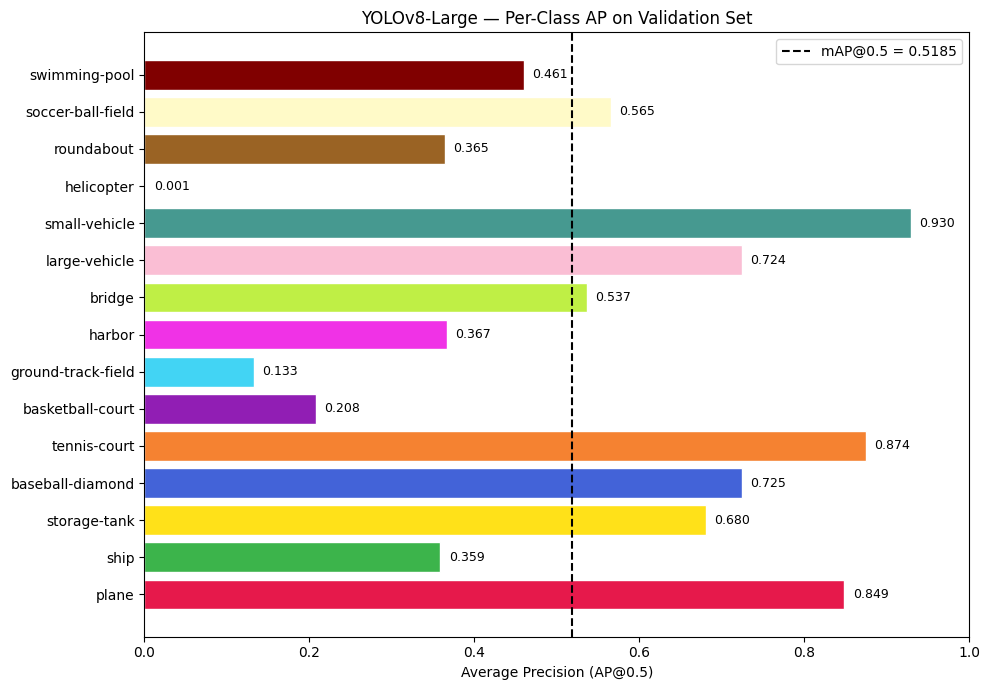

In [ ]:
# ===== YOLOv8 Validation Evaluation =====

# Load best checkpoint from training
yolo_best_path = os.path.join(
    yolo_output_dir, "yolov8l_dota", "weights", "best.pt"
)
yolo_eval_model = YOLO(yolo_best_path)                     # Load trained model
print(f"YOLOv8 best checkpoint loaded from: {yolo_best_path}")

# Run validation on the validation split
yolo_val_metrics = yolo_eval_model.val(
    data=yolo_yaml_path,                                   # Dataset config
    split="val",                                           # Validation split
    imgsz=512,                                             # Same as training resolution
    device=0,                                              # GPU
)

# Extract overall metrics
yolo_map50 = yolo_val_metrics.box.map50                    # mAP@0.5
yolo_map50_95 = yolo_val_metrics.box.map                   # mAP@0.5:0.95
yolo_precision = yolo_val_metrics.box.mp                   # Mean precision
yolo_recall = yolo_val_metrics.box.mr                      # Mean recall
yolo_per_class_ap = yolo_val_metrics.box.ap50              # Per-class AP@0.5

# Print overall metrics
print(f"\nYOLOv8 Validation Results:")
print(f"  mAP@0.5     : {yolo_map50:.4f}")
print(f"  mAP@0.5:0.95: {yolo_map50_95:.4f}")
print(f"  Precision    : {yolo_precision:.4f}")
print(f"  Recall       : {yolo_recall:.4f}")

# Print per-class AP table
print("\n" + "=" * 50)
print("YOLOv8-Large — Per-Class Validation AP@0.5")
print("=" * 50)
for i, cls_name in enumerate(YOLO_CLASS_MAPPING.keys()):
    ap = float(yolo_per_class_ap[i]) if i < len(yolo_per_class_ap) else 0.0
    print(f"  {cls_name:<25}: {ap:.4f}")
print(f"\n  {'mAP@0.5':<25}: {yolo_map50:.4f}")

# ===== Per-Class AP Bar Chart =====

# Build AP values list
yolo_ap_values = []
for i, cls_name in enumerate(YOLO_CLASS_MAPPING.keys()):
    ap = float(yolo_per_class_ap[i]) if i < len(yolo_per_class_ap) else 0.0
    yolo_ap_values.append(ap)

# Horizontal bar chart matching Faster R-CNN format
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(list(YOLO_CLASS_MAPPING.keys()), yolo_ap_values,
               color=CLASS_COLOURS[:len(YOLO_CLASS_MAPPING)], edgecolor="white")

# Dashed line for overall mAP reference
ax.axvline(yolo_map50, color="black", linestyle="--", linewidth=1.5,
           label=f"mAP@0.5 = {yolo_map50:.4f}")

# Axis labels and formatting
ax.set_xlabel("Average Precision (AP@0.5)")
ax.set_title("YOLOv8-Large — Per-Class AP on Validation Set")
ax.set_xlim(0, 1.0)
ax.legend()

# Annotate each bar with its AP value
for bar, value in zip(bars, yolo_ap_values):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(yolo_output_dir, "yolo_val_per_class_ap.png"), dpi=150)
plt.show()

> **Inference:**  

> YOLOv8-Large achieved a moderate overall validation performance, with mAP@0.5 = 0.5185, mAP@0.5:0.95 = 0.3313, precision = 0.5967, and recall = 0.4700. This shows that the model is able to detect many objects correctly, but it still misses a noticeable number of objects, as shown by the lower recall. The per-class AP results show that the model performs very well on classes such as small-vehicle (0.930), tennis-court (0.874), plane (0.849), baseball-diamond (0.725), large-vehicle (0.724), and storage-tank (0.680).

> Performance is weaker for classes such as basketball-court (0.208), ground-track-field (0.133), and especially helicopter (0.001). These weak results are mainly linked to the very small number of validation instances for these classes, such as only 9 helicopter, 15 basketball-court, and 17 ground-track-field instances. Classes such as ship, harbor, and roundabout show moderate performance, which may be affected by object density, small object size, background similarity, and overlap in aerial images.  

> Overall, YOLOv8-Large performs well on frequent and visually clear classes, but struggles with rare and harder-to-detect categories.

### 6. Test Set Evaluation & Model Comparison

This section evaluates all three models on the held-out test set (45 images, not seen during training or validation). Each model is evaluated using its respective metric — classification accuracy for SimpleCNN, mAP@0.5 for Faster R-CNN and YOLOv8 — followed by a unified comparison table summarising performance, architecture, and parameter counts across all three models.

---

### 6.1 SimpleCNN — Test Set Evaluation

Evaluate the SimpleCNN baseline on test set crops. Since the CNN operates on individual object crops (not full images), test crops are extracted from test tiles using the same process as Section 5.1.1.

In [ ]:
# ===== SimpleCNN Test Set Evaluation =====

# Extract test crops (same process as train/val in Section 5.3.0)
test_crop_dir = os.path.join(output_dir, "processed_crops", "test")
shutil.rmtree(test_crop_dir, ignore_errors=True)

test_tile_img_dir = os.path.join(output_dir, "tiles/test/images")
test_tile_lbl_dir = os.path.join(output_dir, "tiles/test/labels")

print("Extracting test crops...")
test_crop_counts = extract_crops_from_tiles(
    test_tile_img_dir, test_tile_lbl_dir,
    test_crop_dir,
    max_tiles=MAX_TILES,
)
print(f"Total test crops: {sum(test_crop_counts.values()):,}")

# Build test dataset and loader
cnn_test_ds = DOTACropDataset(test_crop_dir, DOTA_CLASSES,
                               img_size=224, augment=False)
cnn_test_loader = DataLoader(cnn_test_ds, batch_size=16,
                              shuffle=False, num_workers=0, pin_memory=True)

print(f"Test samples: {len(cnn_test_ds):,}  |  Test batches: {len(cnn_test_loader)}")

# Load best CNN checkpoint
cnn_model.load_state_dict(torch.load(os.path.join(output_dir, "cnn_best.pth"), map_location=device))
cnn_model.eval()

# Per-class test accuracy
cnn_test_correct = defaultdict(int)
cnn_test_total = defaultdict(int)

with torch.no_grad():
    for images, labels in cnn_test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = cnn_model(images)
        _, preds = torch.max(outputs, 1)
        for pred, lbl in zip(preds, labels):
            cls_name = DOTA_CLASSES[lbl.item()]
            cnn_test_total[cls_name] += 1
            if pred.item() == lbl.item():
                cnn_test_correct[cls_name] += 1

# Print results
print("\n" + "=" * 50)
print("SimpleCNN — Per-Class Test Accuracy")
print("=" * 50)
for cls in DOTA_CLASSES:
    total = cnn_test_total.get(cls, 0)
    correct = cnn_test_correct.get(cls, 0)
    acc = correct / total if total > 0 else 0.0
    print(f"  {cls:<25}: {acc:.4f}  ({correct}/{total})")

cnn_test_overall = sum(cnn_test_correct.values()) / max(1, sum(cnn_test_total.values()))
print(f"\n  {'Overall':<25}: {cnn_test_overall:.4f}")

Extracting test crops...


Extracting crops: 100%|██████████| 500/500 [00:35<00:00, 13.95it/s]


Skipped 368 objects below 16px
Total test crops: 1,979
Test samples: 1,979  |  Test batches: 124

SimpleCNN — Per-Class Test Accuracy
  plane                    : 0.1757  (13/74)
  baseball-diamond         : 0.0000  (0/6)
  bridge                   : 0.0000  (0/0)
  ground-track-field       : 0.0000  (0/4)
  small-vehicle            : 0.0000  (0/512)
  large-vehicle            : 0.0000  (0/85)
  ship                     : 0.1837  (156/849)
  tennis-court             : 0.4646  (46/99)
  basketball-court         : 0.0000  (0/6)
  storage-tank             : 0.0000  (0/8)
  soccer-ball-field        : 0.0000  (0/7)
  roundabout               : 0.0000  (0/3)
  harbor                   : 0.6846  (191/279)
  swimming-pool            : 0.0638  (3/47)
  helicopter               : 0.0000  (0/0)

  Overall                  : 0.2067


> **Inference:**  
> SimpleCNN achieves 20.67% overall test accuracy — higher than validation accuracy (8.86%), likely due to differences in the class distribution of the test crops.
>
> The model produced correct predictions for only five classes: harbor (68.5%), tennis-court (46.5%), ship (18.4%), plane (17.6%), and swimming-pool (6.4%). Several classes had test samples but received 0 correct predictions, including small-vehicle, large-vehicle, baseball-diamond, basketball-court, storage-tank, soccer-ball-field, roundabout, and ground-track-field. Bridge and helicopter had 0 test samples, so their performance cannot be meaningfully evaluated.  
>
> A major limitation is that small-vehicle, the second-largest test class with 512 samples, receives 0 correct predictions. The overall accuracy is mainly driven by correct predictions for harbor (191/279) and ship (156/849), so the headline accuracy does not indicate balanced generalisation across classes.  
These results confirm the CNN baseline’s limitation as a crop-only classifier.

### 6.2 Faster R-CNN — Test Set Evaluation

Evaluate the best Faster R-CNN checkpoint on the held-out test set using mAP@0.5. Per-class AP is displayed alongside a bar chart for visual comparison.

Running Faster R-CNN test-set evaluation...


Evaluating:   0%|          | 0/1867 [00:00<?, ?it/s]


Faster R-CNN — Per-Class Test AP@0.5
  plane                    : 0.1856
  baseball-diamond         : 0.0800
  bridge                   : 0.0000
  ground-track-field       : 0.0043
  small-vehicle            : 0.0291
  large-vehicle            : 0.0198
  ship                     : 0.0141
  tennis-court             : 0.4568
  basketball-court         : 0.0000
  storage-tank             : 0.0000
  soccer-ball-field        : 0.0766
  roundabout               : 0.0000
  harbor                   : 0.0814
  swimming-pool            : 0.0000
  helicopter               : N/A

  mAP@0.5                  : 0.0677


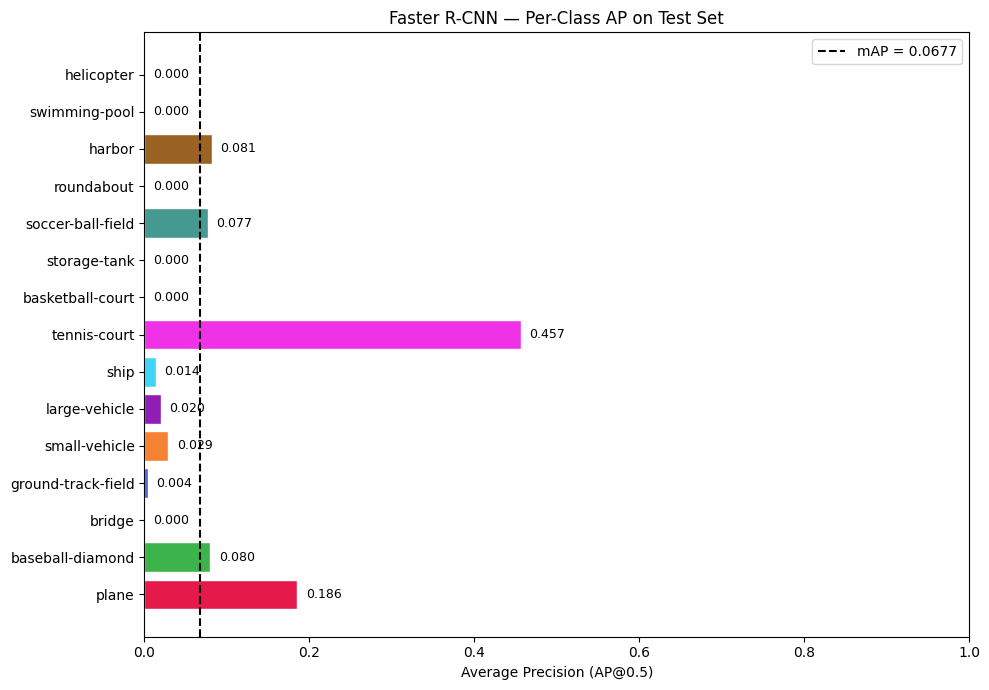

In [ ]:
# ===== Faster R-CNN Test Set Evaluation =====

# best_model is already loaded from Section 5.9.1
print("Running Faster R-CNN test-set evaluation...")
frcnn_test_ap = evaluate_one_epoch(best_model, test_loader, device, iou_threshold=0.5)

# Print per-class AP table
print("\n" + "=" * 50)
print("Faster R-CNN — Per-Class Test AP@0.5")
print("=" * 50)
for cls_name in DOTA_CLASSES:
    v = frcnn_test_ap.get(cls_name, float('nan'))
    v_str = f"{v:.4f}" if not math.isnan(v) else "N/A"
    print(f"  {cls_name:<25}: {v_str}")
print(f"\n  {'mAP@0.5':<25}: {frcnn_test_ap['mAP']:.4f}")

# Per-class AP bar chart
frcnn_test_values = [frcnn_test_ap.get(name, 0.0) for name in DOTA_CLASSES]
frcnn_test_values = [v if not math.isnan(v) else 0.0 for v in frcnn_test_values]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(DOTA_CLASSES, frcnn_test_values, color=CLASS_COLOURS[:len(DOTA_CLASSES)], edgecolor="white")
ax.axvline(frcnn_test_ap["mAP"], color="black", linestyle="--", linewidth=1.5,
           label=f"mAP = {frcnn_test_ap['mAP']:.4f}")
ax.set_xlabel("Average Precision (AP@0.5)")
ax.set_title("Faster R-CNN — Per-Class AP on Test Set")
ax.set_xlim(0, 1.0)
ax.legend()
for bar, value in zip(bars, frcnn_test_values):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(training_output_dir, "test_per_class_ap.png"), dpi=150)
plt.show()

> **Inference:**  
> Faster R-CNN achieves a test mAP@0.5 of 0.0677, slightly higher than the validation mAP@0.5 of 0.0432, suggesting limited but modest generalisation to unseen data.  
> Tennis-court gives the strongest result with 0.4568 AP, followed by plane at 0.1856 AP. Other non-zero classes remain low, including harbor (0.0814), baseball-diamond (0.0800), soccer-ball-field (0.0766), small-vehicle (0.0291), large-vehicle (0.0198), ship (0.0141), and ground-track-field (0.0043).
>
> Five classes score exactly 0 AP: bridge, basketball-court, storage-tank, roundabout, and swimming-pool, while helicopter has no valid test AP reported because no test ground truth is available for that class.   
> Helicopter has no valid test AP because there was no test ground truth available for that class. The very low AP for important classes such as small-vehicle, large-vehicle, and ship shows that the model struggled with small, dense, and visually challenging aerial objects in the sampled setting. Overall, Faster R-CNN performed better than a simple baseline in terms of detection capability, but the low mAP shows that it did not learn strong enough detection features.

### 6.3 YOLOv8 — Test Set Evaluation

Evaluate the best YOLOv8 checkpoint on the held-out test set using the Ultralytics validation API with `split="test"`. Reports mAP@0.5, mAP@0.5:0.95, precision, recall, and per-class AP.  

Running YOLOv8 test-set evaluation...
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 161.4±67.8 MB/s, size: 407.1 KB)
val: Scanning /content/drive/MyDrive/CSMAI_CW/output/yolo_dataset/labels/test... 1867 images, 1220 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1867/1867 114.3it/s 16.3s
val: New cache created: /content/drive/MyDrive/CSMAI_CW/output/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 117/117 9.9it/s 11.8s
                   all       1867       5277      0.547      0.567      0.521      0.321
                 plane         80        154       0.58      0.896      0.727      0.451
                  ship        102       1294      0.894       0.86      0.897      0.583
          storage-tank         36        589      0.899      0.324      0.448      0.265
      baseball-diamond         17   

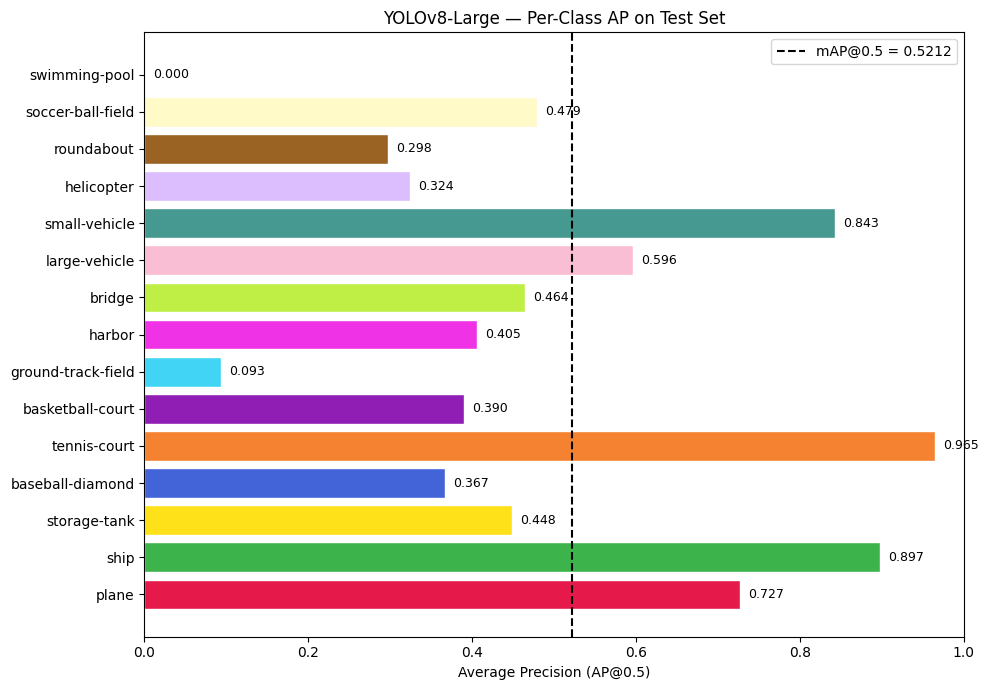

In [ ]:
# ===== YOLOv8 Test Set Evaluation =====

# yolo_eval_model is already loaded from Section 5.10.1
print("Running YOLOv8 test-set evaluation...")
yolo_test_metrics = yolo_eval_model.val(
    data=yolo_yaml_path,                                   # Dataset config
    split="test",                                          # Test split
    imgsz=512,                                             # Same as training
    device=0,                                              # GPU
)

# Extract metrics
yolo_test_map50 = yolo_test_metrics.box.map50              # mAP@0.5
yolo_test_map50_95 = yolo_test_metrics.box.map             # mAP@0.5:0.95
yolo_test_precision = yolo_test_metrics.box.mp             # Mean precision
yolo_test_recall = yolo_test_metrics.box.mr                # Mean recall
yolo_test_per_class_ap = yolo_test_metrics.box.ap50        # Per-class AP@0.5

# Print per-class AP table
print("\n" + "=" * 50)
print("YOLOv8-Large — Per-Class Test AP@0.5")
print("=" * 50)
for i, cls_name in enumerate(YOLO_CLASS_MAPPING.keys()):
    ap = float(yolo_test_per_class_ap[i]) if i < len(yolo_test_per_class_ap) else 0.0
    print(f"  {cls_name:<25}: {ap:.4f}")
print(f"\n  {'mAP@0.5':<25}: {yolo_test_map50:.4f}")
print(f"  {'mAP@0.5:0.95':<25}: {yolo_test_map50_95:.4f}")
print(f"  {'Precision':<25}: {yolo_test_precision:.4f}")
print(f"  {'Recall':<25}: {yolo_test_recall:.4f}")

# Per-class AP bar chart
yolo_test_values = [float(yolo_test_per_class_ap[i]) if i < len(yolo_test_per_class_ap) else 0.0
                    for i in range(len(YOLO_CLASS_MAPPING))]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(list(YOLO_CLASS_MAPPING.keys()), yolo_test_values,
               color=CLASS_COLOURS[:len(YOLO_CLASS_MAPPING)], edgecolor="white")
ax.axvline(yolo_test_map50, color="black", linestyle="--", linewidth=1.5,
           label=f"mAP@0.5 = {yolo_test_map50:.4f}")
ax.set_xlabel("Average Precision (AP@0.5)")
ax.set_title("YOLOv8-Large — Per-Class AP on Test Set")
ax.set_xlim(0, 1.0)
ax.legend()
for bar, value in zip(bars, yolo_test_values):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(yolo_output_dir, "yolo_test_per_class_ap.png"), dpi=150)
plt.show()

> **Inference:**  
> YOLOv8-Large achieved a test mAP@0.5 of 0.5212, mAP@0.5:0.95 of 0.3205, precision of 0.5473, and recall of 0.5670. These results are very close to the validation mAP@0.5 of 0.5185, showing that the model performs consistently on unseen test data. The strongest classes include tennis-court (0.965), ship (0.897), small-vehicle (0.843), plane (0.727), and large-vehicle (0.596). Moderate results are seen for bridge (0.464), storage-tank (0.448), harbor (0.405), basketball-court (0.390), baseball-diamond (0.367), roundabout (0.324), and soccer-ball-field (0.298). The weakest reported class is swimming-pool (0.00), followed by ground-track-field (0.093), showing that these category remains difficult for the model. Overall, YOLOv8-Large gives the strongest performance in this study and clearly outperforms both the CNN baseline and Faster R-CNN.

### 6.4 Three-Model Comparison

Side-by-side comparison of all three models evaluated on the held-out test set. Summarises architecture type, parameter count, primary metric, and per-class strengths/weaknesses.

Three-Model Comparison — Test Set Results
Metric                              SimpleCNN   Faster R-CNN       YOLOv8-L
---------------------------------------------------------------------------
Task                           Classification      Detection      Detection
Architecture                      3-block CNN     MNetV3+FPN       YOLOv8-L
Parameters                            624,975     19,001,979     43,641,405
Test Accuracy                          0.2067            N/A            N/A
Test mAP@0.5                              N/A         0.0677         0.5212
Test mAP@0.5:0.95                         N/A            N/A         0.3205
Precision                                 N/A            N/A         0.5473
Recall                                    N/A            N/A         0.5670


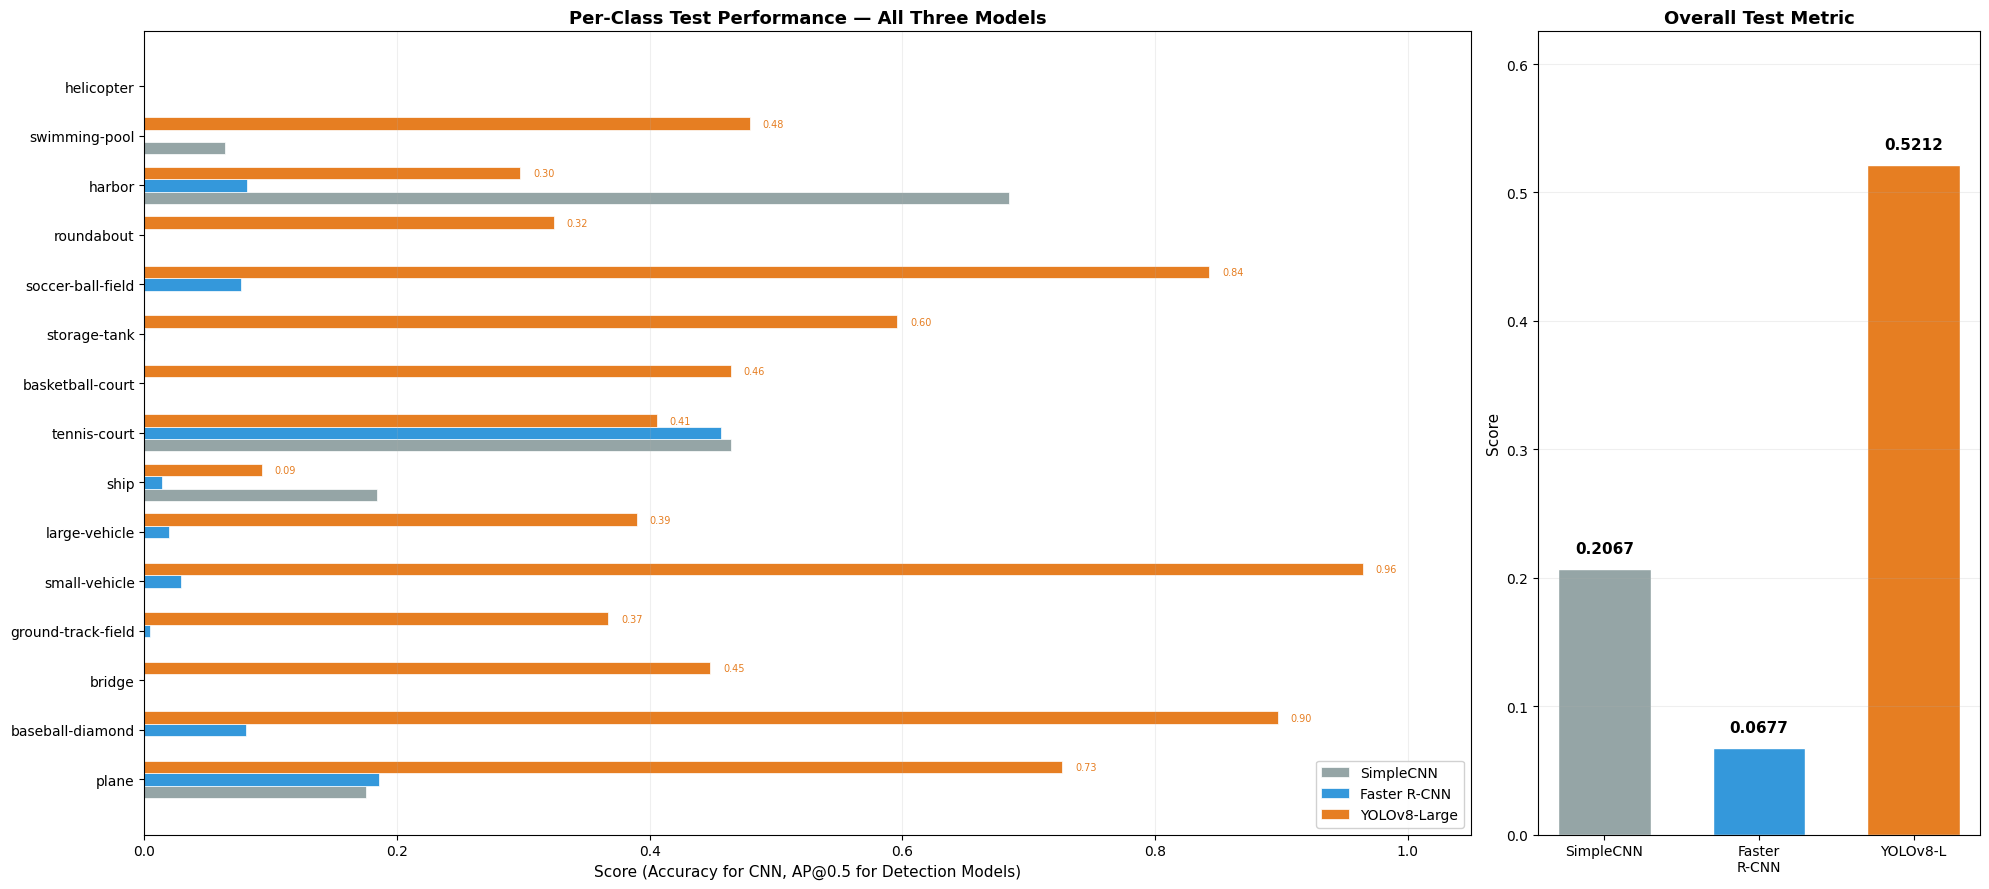

In [ ]:
# ===== Three-Model Comparison Table =====

# Model parameter counts
cnn_params = sum(p.numel() for p in cnn_model.parameters())
frcnn_params = sum(p.numel() for p in best_model.parameters())
yolo_params = 43_641_405                                   # From Ultralytics model summary

# Print comparison table
print("=" * 75)
print("Three-Model Comparison — Test Set Results")
print("=" * 75)
print(f"{'Metric':<30} {'SimpleCNN':>14} {'Faster R-CNN':>14} {'YOLOv8-L':>14}")
print("-" * 75)
print(f"{'Task':<30} {'Classification':>14} {'Detection':>14} {'Detection':>14}")
print(f"{'Architecture':<30} {'3-block CNN':>14} {'MNetV3+FPN':>14} {'YOLOv8-L':>14}")
print(f"{'Parameters':<30} {cnn_params:>14,} {frcnn_params:>14,} {yolo_params:>14,}")
print(f"{'Test Accuracy':<30} {cnn_test_overall:>14.4f} {'N/A':>14} {'N/A':>14}")
print(f"{'Test mAP@0.5':<30} {'N/A':>14} {frcnn_test_ap['mAP']:>14.4f} {yolo_test_map50:>14.4f}")
print(f"{'Test mAP@0.5:0.95':<30} {'N/A':>14} {'N/A':>14} {yolo_test_map50_95:>14.4f}")
print(f"{'Precision':<30} {'N/A':>14} {'N/A':>14} {yolo_test_precision:>14.4f}")
print(f"{'Recall':<30} {'N/A':>14} {'N/A':>14} {yolo_test_recall:>14.4f}")
print("=" * 75)

# ===== Per-Class Comparison Chart — All Three Models =====

# SimpleCNN per-class test accuracy values
cnn_test_values = [
    cnn_test_correct.get(cls, 0) / max(1, cnn_test_total.get(cls, 1))
    for cls in DOTA_CLASSES
]

# Create figure with two subplots: grouped bars + overall summary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9),
                                gridspec_kw={"width_ratios": [3, 1]})

# ---- Left: Per-class grouped bar chart ----
x = np.arange(len(DOTA_CLASSES))
width = 0.25

bars1 = ax1.barh(x - width, cnn_test_values, width,
                  label="SimpleCNN", color="#95a5a6", edgecolor="white", linewidth=0.5)
bars2 = ax1.barh(x, frcnn_test_values, width,
                  label="Faster R-CNN", color="#3498db", edgecolor="white", linewidth=0.5)
bars3 = ax1.barh(x + width, yolo_test_values, width,
                  label="YOLOv8-Large", color="#e67e22", edgecolor="white", linewidth=0.5)

# Annotate YOLOv8 bars with values (strongest model)
for bar, value in zip(bars3, yolo_test_values):
    if value > 0.01:
        ax1.text(value + 0.01, bar.get_y() + bar.get_height() / 2,
                 f"{value:.2f}", va="center", fontsize=7, color="#e67e22")

ax1.set_yticks(x)
ax1.set_yticklabels(DOTA_CLASSES, fontsize=10)
ax1.set_xlabel("Score (Accuracy for CNN, AP@0.5 for Detection Models)", fontsize=11)
ax1.set_title("Per-Class Test Performance — All Three Models", fontsize=13, fontweight="bold")
ax1.set_xlim(0, 1.05)
ax1.legend(loc="lower right", fontsize=10, framealpha=0.9)
ax1.grid(axis="x", alpha=0.2)

# ---- Right: Overall metric comparison ----
model_names = ["SimpleCNN", "Faster\nR-CNN", "YOLOv8-L"]
overall_scores = [cnn_test_overall, frcnn_test_ap["mAP"], yolo_test_map50]
colors = ["#95a5a6", "#3498db", "#e67e22"]

bars = ax2.bar(model_names, overall_scores, color=colors, edgecolor="white", width=0.6)

# Annotate bars with values
for bar, value in zip(bars, overall_scores):
    ax2.text(bar.get_x() + bar.get_width() / 2, value + 0.01,
             f"{value:.4f}", ha="center", va="bottom", fontsize=11, fontweight="bold")

ax2.set_ylabel("Score", fontsize=11)
ax2.set_title("Overall Test Metric", fontsize=13, fontweight="bold")
ax2.set_ylim(0, max(overall_scores) * 1.2)
ax2.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "model_comparison_test_ap.png"), dpi=150, bbox_inches="tight")
plt.show()

> **Inference**:
The overall comparison shows that YOLOv8-Large is the strongest model, achieving the highest overall test score with mAP@0.5 = 0.5212. Faster R-CNN achieved a much lower test mAP@0.5 = 0.0677, while the SimpleCNN baseline achieved 20.67% test accuracy. Although SimpleCNN shows a higher numerical score than Faster R-CNN, it is important to note that SimpleCNN is only a crop-based classification model, whereas Faster R-CNN and YOLOv8 are full object detection models that perform both localisation and classification. Therefore, the scores are not directly identical in meaning.  
Overall, YOLOv8-Large provides the best balance of detection accuracy, class coverage, and generalisation, making it the most effective model in this study.

### 7. Critical Discussion

This section provides an in-depth critical analysis of **YOLOv8-Large**, the strongest model identified in Section 6:

- **7.1 Hyperparameter Discussion** — Justification of chosen hyperparameters and potential alternatives
- **7.2 Overfitting & Underfitting Diagnostics** — Analysis of training curves to assess convergence and generalisation
- **7.3 Ablation Analysis** — Discussion of how individual components (augmentation, image size, model capacity) contribute to performance
- **7.4 Bias & Class-Level Error Analysis** — Investigation of per-class performance gaps, failure modes, and dataset-related biases


---

### 7.1 Hyperparameter Discussion


**Discussion of the hyperparameter choices made for YOLOv8-Large and their impact on detection performance. No formal grid search was conducted due to compute constraints — instead, choices are justified through literature and observed training behaviour.**

--

YOLOv8-Large was trained with settings that balanced performance and GPU limits. The Large model was chosen because it has enough capacity for 15 aerial object classes, while the 512×512 image size matched the tiled images and kept memory use manageable. Larger image sizes could improve small-object detection, but they would need more GPU power.

The model was trained for 15 epochs with a batch size of 4, which was suitable for the Colab GPU setup. Augmentations such as Mosaic, MixUp, colour changes, scaling, and flipping were used to help the model learn better from the limited sampled data. Early stopping was enabled, but it did not stop training, meaning the model was still improving. Overall, this setup was practical for the coursework and gave a strong YOLOv8 model for comparison with SimpleCNN and Faster R-CNN.

### 7.2 Overfitting & Underfitting Diagnostics

Analyse YOLOv8's training curves (box loss, classification loss, DFL loss, and validation mAP) to assess convergence, overfitting, and underfitting. Uses the auto-generated `results.csv` from Ultralytics training.

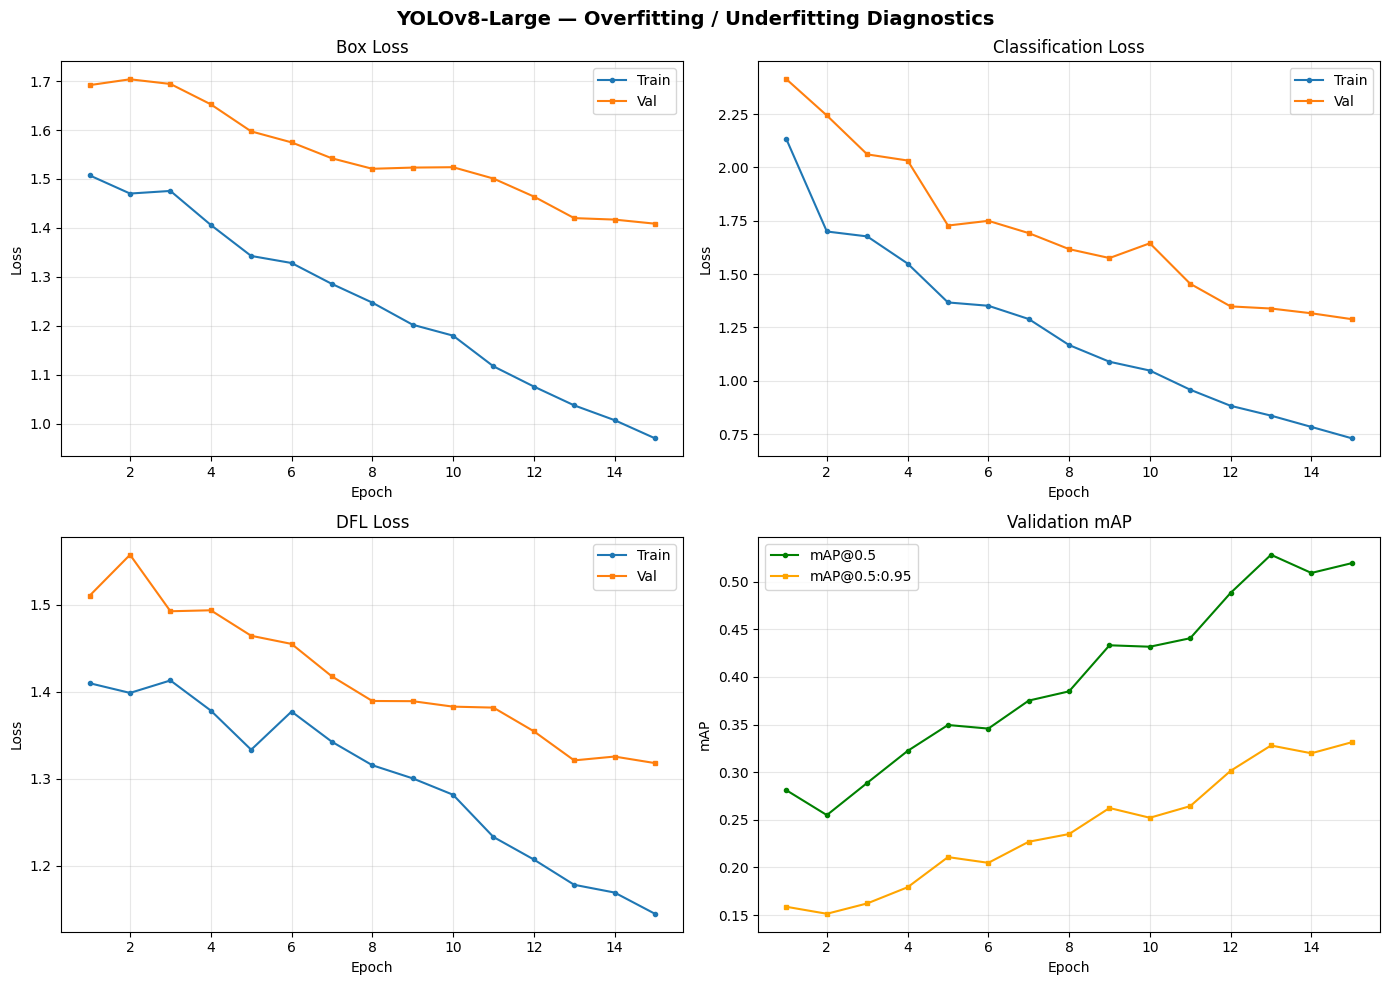


Overfitting / Underfitting Summary
  Train box loss  : 1.5073 → 0.9705
  Val box loss    : 1.6917 → 1.4087
  Train cls loss  : 2.1312 → 0.7311
  Val cls loss    : 2.4128 → 1.2891
  Val mAP@0.5     : 0.2810 → 0.5192
  Val mAP@0.5:0.95: 0.1588 → 0.3314

  Diagnosis: Possible overfitting — validation loss significantly exceeds training loss


In [ ]:
# ===== YOLOv8 Overfitting / Underfitting Diagnostics =====

# Load Ultralytics training log
results_csv_path = os.path.join(yolo_output_dir, "yolov8l_dota", "results.csv")
yolo_results_df = pd.read_csv(results_csv_path)

# Clean column names (Ultralytics adds spaces)
yolo_results_df.columns = yolo_results_df.columns.str.strip()

# Plot training losses and validation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box loss
axes[0, 0].plot(yolo_results_df["epoch"], yolo_results_df["train/box_loss"], label="Train", marker="o", markersize=3)
axes[0, 0].plot(yolo_results_df["epoch"], yolo_results_df["val/box_loss"], label="Val", marker="s", markersize=3)
axes[0, 0].set_title("Box Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Classification loss
axes[0, 1].plot(yolo_results_df["epoch"], yolo_results_df["train/cls_loss"], label="Train", marker="o", markersize=3)
axes[0, 1].plot(yolo_results_df["epoch"], yolo_results_df["val/cls_loss"], label="Val", marker="s", markersize=3)
axes[0, 1].set_title("Classification Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# DFL loss
axes[1, 0].plot(yolo_results_df["epoch"], yolo_results_df["train/dfl_loss"], label="Train", marker="o", markersize=3)
axes[1, 0].plot(yolo_results_df["epoch"], yolo_results_df["val/dfl_loss"], label="Val", marker="s", markersize=3)
axes[1, 0].set_title("DFL Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Validation mAP
axes[1, 1].plot(yolo_results_df["epoch"], yolo_results_df["metrics/mAP50(B)"], label="mAP@0.5", marker="o", markersize=3, color="green")
axes[1, 1].plot(yolo_results_df["epoch"], yolo_results_df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", marker="s", markersize=3, color="orange")
axes[1, 1].set_title("Validation mAP")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("mAP")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle("YOLOv8-Large — Overfitting / Underfitting Diagnostics", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "yolo_overfitting_diagnostics.png"), dpi=150)
plt.show()

# Print diagnostic summary
final_epoch = yolo_results_df.iloc[-1]
first_epoch = yolo_results_df.iloc[0]

print("\n" + "=" * 60)
print("Overfitting / Underfitting Summary")
print("=" * 60)
print(f"  Train box loss  : {first_epoch['train/box_loss']:.4f} → {final_epoch['train/box_loss']:.4f}")
print(f"  Val box loss    : {first_epoch['val/box_loss']:.4f} → {final_epoch['val/box_loss']:.4f}")
print(f"  Train cls loss  : {first_epoch['train/cls_loss']:.4f} → {final_epoch['train/cls_loss']:.4f}")
print(f"  Val cls loss    : {first_epoch['val/cls_loss']:.4f} → {final_epoch['val/cls_loss']:.4f}")
print(f"  Val mAP@0.5     : {first_epoch['metrics/mAP50(B)']:.4f} → {final_epoch['metrics/mAP50(B)']:.4f}")
print(f"  Val mAP@0.5:0.95: {first_epoch['metrics/mAP50-95(B)']:.4f} → {final_epoch['metrics/mAP50-95(B)']:.4f}")

# Overfitting check
train_final = final_epoch['train/box_loss'] + final_epoch['train/cls_loss']
val_final = final_epoch['val/box_loss'] + final_epoch['val/cls_loss']
gap = val_final - train_final

if gap > 0.5:
    diagnosis = "Possible overfitting — validation loss significantly exceeds training loss"
elif final_epoch['metrics/mAP50(B)'] < 0.1:
    diagnosis = "Underfitting — model has not learned strong detection features"
else:
    diagnosis = "Healthy convergence — training and validation losses decrease together with rising mAP"

print(f"\n  Diagnosis: {diagnosis}")

**Inference:**  
> The YOLOv8-Large training curves show steady learning across the 15 epochs. Training losses decrease clearly, with box loss reducing from 1.5073 to 0.9705 and classification loss reducing from 2.1312 to 0.7311. Validation losses also decrease overall, with validation box loss reducing from 1.6917 to 1.4087 and validation classification loss reducing from 2.4128 to 1.2891. This shows that the model is learning useful detection features and is not underfitting.
>
> Validation performance also improves strongly. The mAP@0.5 increases from 0.2810 to 0.5192, while mAP@0.5:0.95 increases from 0.1588 to 0.3314. This means the model’s detection quality improves throughout training.
>
> However, validation loss stays higher than training loss, especially in the later epochs. This suggests a mild generalisation gap, meaning the model learns the training data better than the validation data. This is not severe overfitting because validation mAP continues to improve rather than decrease.
>
> Overall, the model shows healthy training progress and no clear underfitting. There is some mild overfitting risk, so longer training should be monitored carefully using validation mAP and validation loss. More data, better class balancing, and regularisation could help reduce the gap further.

### 7.3 Ablation Analysis

Discuss the contribution of individual components to YOLOv8's performance. Due to compute constraints, this is a structured discussion based on training observations and literature rather than re-training with components removed.

---

This component impact discussion shows that YOLOv8-Large performance is supported by several key choices: transfer learning, model size, data augmentation, and the YOLO detection design. ImageNet pre-training helped the model start with useful visual features instead of learning everything from scratch. The Large model size also gave the model enough capacity to learn 15 different aerial object classes.

Mosaic augmentation was likely important because aerial images contain dense objects and complex layouts. It helped the model see more varied object arrangements during training. MixUp was used lightly, so its effect was probably smaller, mainly helping with regularisation. HSV colour changes were also useful because aerial images can have different lighting, shadows, and colour conditions.

The 512×512 image size made training practical on Colab, but it may have limited performance on very small objects. Larger image sizes such as 640 or 1024 could improve small-object detection, but they would need more GPU memory and longer training time. Early stopping did not affect this run because training completed all 15 epochs, but it would still be useful in longer experiments.

Overall, the most important components are likely ImageNet pre-training, YOLOv8-Large model capacity, Mosaic augmentation, and the anchor-free YOLO design. However, this should be treated as a qualitative component discussion, not a full ablation study, because each component was not removed and retrained separately.

### 7.4 Bias & Class-Level Error Analysis

Analyse per-class detection biases using YOLOv8's test results. Investigates the relationship between training instance count, object size, and detection performance to identify systematic failure modes.

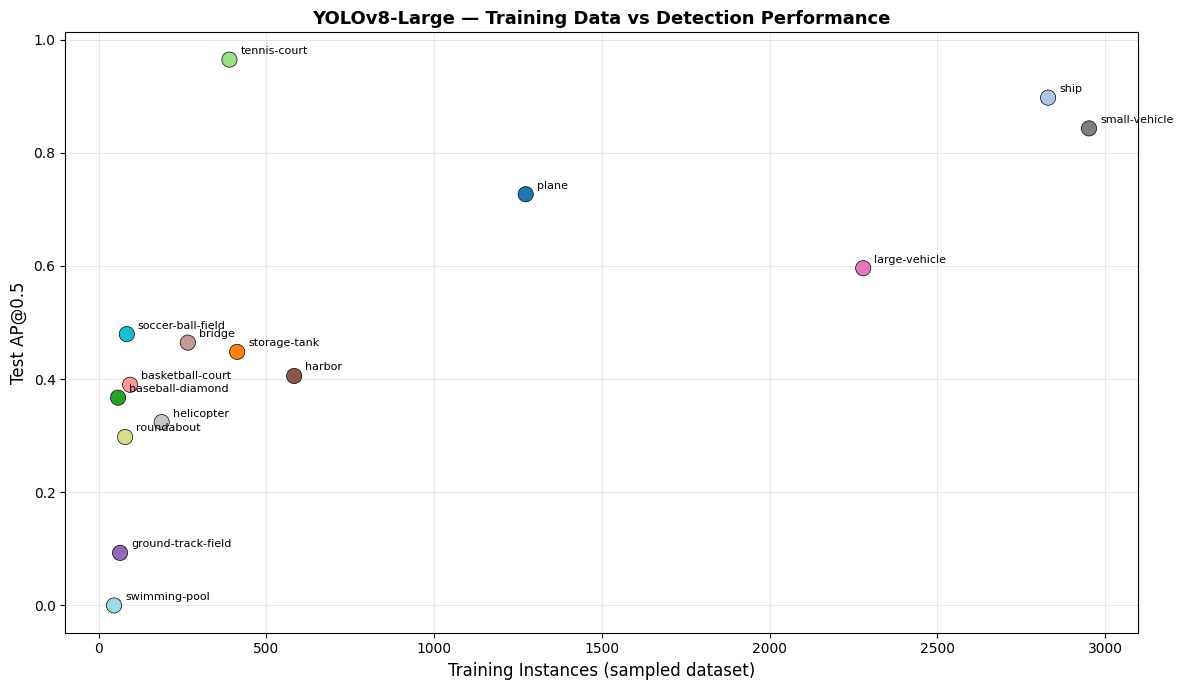


Class-Level Bias Summary
Class                      Train Count    Test AP Status              
-----------------------------------------------------------------
  tennis-court                     390     0.9646 Strong              
  ship                            2830     0.8974 Strong              
  small-vehicle                   2952     0.8431 Strong              
  plane                           1273     0.7267 Strong              
  large-vehicle                   2279     0.5960 Strong              
  soccer-ball-field                 84     0.4795 Moderate            
  bridge                           266     0.4644 Moderate            
  storage-tank                     413     0.4481 Moderate            
  harbor                           583     0.4055 Moderate            
  basketball-court                  94     0.3900 Moderate            
  baseball-diamond                  58     0.3672 Moderate            
  helicopter                       188     0.3239 Modera

In [ ]:
# ===== Bias & Class-Level Error Analysis =====

# Per-class test AP from YOLOv8
yolo_test_ap_dict = {}
for i, cls_name in enumerate(YOLO_CLASS_MAPPING.keys()):
    ap = float(yolo_test_per_class_ap[i]) if i < len(yolo_test_per_class_ap) else 0.0
    yolo_test_ap_dict[cls_name] = ap

# Training instance counts from sampled dataset
train_counts = dota_new_train_df["category"].value_counts()

# Build analysis DataFrame
bias_data = []
for cls in YOLO_CLASS_MAPPING.keys():
    bias_data.append({
        "class": cls,
        "train_instances": train_counts.get(cls, 0),
        "test_ap": yolo_test_ap_dict.get(cls, 0.0),
    })

bias_df = pd.DataFrame(bias_data)

# Scatter plot: training instances vs test AP
fig, ax = plt.subplots(figsize=(12, 7))
scatter = ax.scatter(
    bias_df["train_instances"],
    bias_df["test_ap"],
    s=120,
    c=range(len(bias_df)),
    cmap="tab20",
    edgecolors="black",
    linewidth=0.5,
    zorder=3,
)

# Annotate each point with class name
for _, row in bias_df.iterrows():
    ax.annotate(
        row["class"],
        (row["train_instances"], row["test_ap"]),
        textcoords="offset points",
        xytext=(8, 4),
        fontsize=8,
    )

ax.set_xlabel("Training Instances (sampled dataset)", fontsize=12)
ax.set_ylabel("Test AP@0.5", fontsize=12)
ax.set_title("YOLOv8-Large — Training Data vs Detection Performance", fontsize=13, fontweight="bold")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "yolo_bias_analysis.png"), dpi=150)
plt.show()

# Print bias summary
print("\n" + "=" * 65)
print("Class-Level Bias Summary")
print("=" * 65)
print(f"{'Class':<25} {'Train Count':>12} {'Test AP':>10} {'Status':<20}")
print("-" * 65)
for _, row in bias_df.sort_values("test_ap", ascending=False).iterrows():
    if row["test_ap"] >= 0.5:
        status = "Strong"
    elif row["test_ap"] >= 0.2:
        status = "Moderate"
    elif row["test_ap"] > 0:
        status = "Weak"
    else:
        status = "Failed"
    print(f"  {row['class']:<25} {int(row['train_instances']):>10} {row['test_ap']:>10.4f} {status:<20}")

# Correlation between training count and AP
correlation = bias_df["train_instances"].corr(bias_df["test_ap"])
print(f"\nCorrelation (train count vs test AP): {correlation:.4f}")

**Inference:**  

The class-level bias analysis shows a positive relationship between the number of training samples and YOLOv8-Large test performance, with a correlation of 0.6821. This means that classes with more training examples generally perform better. For example, ship, small-vehicle, plane, and large-vehicle have high training counts and also achieve strong AP values, showing that good class representation helps the model learn more reliable features.

However, the number of samples is not the only factor. Tennis-court achieves the highest AP of 0.9646 even though it has fewer training samples than vehicles and ships. This is likely because tennis courts have a clear and distinctive shape in aerial images. Some other smaller classes, such as soccer-ball-field, basketball-court, baseball-diamond, helicopter, and roundabout, also achieve moderate performance, showing that visually clear classes can still be learned reasonably well.

The weakest classes are ground-track-field and swimming-pool. Ground-track-field has only 64 training samples and achieves a low AP of 0.0929, while swimming-pool has only 46 training samples and records 0.0000 AP in this summary. This suggests that limited data, visual variation, or background confusion affected these classes.

Overall, YOLOv8-Large performs best on classes that are either well represented or visually distinctive. Rare and visually difficult classes remain more challenging, so future work should focus on class-balanced sampling, targeted augmentation, and adding more examples for weaker classes.


---

### 8. Report Quality & Conclusion

---

### 8.1 Metric Justification

- **mAP@0.5** — standard for detection, easy to interpret, consistent with implemented IoU evaluation. It measures whether predicted bounding boxes sufficiently overlap with ground-truth boxes at an IoU threshold of 0.5, making it suitable for evaluating both localisation and classification quality.
- **mAP@0.5:0.95** — reported for YOLOv8 as it provides a stricter COCO-style evaluation across multiple IoU thresholds, giving a more complete view of localisation precision.
- **Per-class AP** — reveals weaknesses hidden by overall mAP (critical for 86× imbalanced data). Essential because the DOTA dataset contains classes with vastly different instance counts, and overall mAP alone can mask poor performance on rare categories.
- **Validation mAP** — checkpoint selection; **Test mAP** — unbiased final metric
- **CNN accuracy** — the SimpleCNN baseline was evaluated using crop-level classification accuracy because it does not perform object localisation. Its accuracy is useful as a lower-bound baseline but is not directly equivalent to detection mAP.

### 8.2 Why Cross-Validation Was Not Used

Standard k-fold CV is impractical for object detection on large aerial datasets:  
- extreme computational cost of 5× retraining,
- tile-based pipeline creates leakage risk if same-source tiles span folds,
- single-split with proper stratification is standard in detection literature (PASCAL VOC, COCO, DOTA benchmarks).

Since one large DOTA image can produce many overlapping tiles, splitting tiles directly across folds may allow visually similar regions from the same source image to appear in both training and validation sets, producing overly optimistic results. Instead, a single train/validation/test split was used with image-level stratification to preserve class representation and maintain a systematic evaluation workflow.

### 8.3 Limitations and Future Work

Although the YOLOv8-Large model achieved the strongest results in this study, several limitations remain. These limitations are mainly related to dataset sampling, computational requirements, model design choices, and evaluation constraints.

| Limitation | Issue | Why | Recommendation |
|:---|:---|:---|:---|
| High compute | Used Colab Pro with A100 GPU; limits reproducibility. | Required for training 3 models on tiled aerial data within time constraints. | Use HPC, cloud GPUs, or smaller models with mixed precision. |
| Sampled dataset | Only 16% of DOTA v1.0 used. | Full dataset training exceeds available Colab credits and runtime. | Train on full dataset with 50–100+ epochs. |
| Axis-aligned boxes | OBB converted to AABB; reduces localisation for rotated objects. | Standard Faster R-CNN and YOLOv8 use AABB; OBB models require specialised architectures. | Use YOLOv8-OBB or Oriented R-CNN. |
| Fixed tile size | 512×512 tiles may cut objects at boundaries. | Fixed size simplifies pipeline and fits GPU memory. | Multi-scale tiling or SAHI sliced inference. |
| Limited epochs | 15 epochs; losses still decreasing. | Colab runtime and credit limits constrain training duration. | Train longer with larger early-stopping patience. |
| Class imbalance | Rare classes (helicopter, swimming-pool) perform poorly. | DOTA is inherently imbalanced; sampling preserves but does not fix this. | Focal loss, oversampling, or class-balanced batches. |
| Resolution | 512px may miss small-object detail. | Higher resolution exceeds Colab GPU memory at batch size 4. | Train at 640–1024px where memory allows. |
| Single split | Results depend on one train/val/test partition. | K-fold CV is impractical for detection (5× retraining cost + tile leakage). | Multiple random seeds or image-level repeated splits. |
| No ensemble | Models evaluated independently. | Ensembling adds complexity beyond coursework scope. | Weighted Box Fusion combining YOLOv8 + Faster R-CNN. |
| Limited backbones | Faster R-CNN used MobileNetV3-FPN only. | Lightweight backbone chosen for Colab feasibility. | Compare ResNet-50-FPN, Swin Transformer, ConvNeXt. |

**Overall:** The current workflow provides a practical and computationally feasible baseline for aerial object detection on a sampled DOTA dataset. However, the experiment still required high computational power, including Google Colab Pro and an NVIDIA A100 GPU. Future work should therefore focus not only on improving model accuracy through full-dataset training, oriented bounding-box detection, higher-resolution inference, and better class-imbalance handling, but also on improving computational efficiency so that the workflow can be reproduced in lower-resource environments.

### 8.4 Final Conclusion

This project built and evaluated a complete end-to-end aerial object detection pipeline on the DOTA v1.0 dataset — from raw annotation parsing through stratified sampling, tiling, augmentation, and training three progressively capable models: SimpleCNN (classification baseline), Faster R-CNN (two-stage detection), and YOLOv8-Large (single-stage detection).

YOLOv8-Large emerged as the strongest model with 0.5212 test mAP@0.5, substantially outperforming Faster R-CNN (0.0677) and SimpleCNN (20.67% accuracy). It produced measurable test performance across most DOTA categories, demonstrating that modern single-stage detectors can achieve competitive results even on a 16% stratified sample under practical compute constraints.

The study also highlighted important challenges: class imbalance severely impacts rare categories, axis-aligned box conversion loses localisation quality for rotated aerial objects, and limited training epochs constrain convergence. These are addressable through full-dataset training, OBB-aware architectures, and targeted augmentation — clear directions for future work.

From an ethical standpoint, this work uses the publicly available DOTA v1.0 benchmark dataset for academic research purposes. Aerial object detection technology has dual-use potential — while it supports legitimate applications such as urban planning, disaster response, and environmental monitoring, it could also be misused for surveillance or military targeting. Responsible deployment requires transparency, regulatory compliance, and careful consideration of privacy implications when applied to real-world aerial imagery containing identifiable locations or infrastructure.

---

## 9. Group Reflection

### 9.1 Individual Contributions


| Name | Task | Effort (%) |
|:---|:---|:---:|
| Bipasha | 1. Dataset selection & preprocessing | 100 |
| | 2. Modelling | 100 |
| | 3. Evaluation | 100 |
| | 4. Coding | 100 |
| | 5. Report writing | 100 |
| Ahmed | 1. Dataset selection & preprocessing | 100 |
| | 2. Modelling | 100 |
| | 3. Evaluation | 100 |
| | 4. Coding | 100 |
| | 5. Report writing | 100 |
| Alp | 1. Dataset selection & preprocessing | 100 |
| | 2. Modelling | 100 |
| | 3. Evaluation | 100 |
| | 4. Coding | 100 |
| | 5. Report writing | 100 |


### 9.2 Collaboration Challenges

- **Data size:** DOTA images made local development slow. We used Google Colab Pro for GPU access (NVIDIA A100).
- **Annotation format:** DOTA's oriented bounding box format required careful geometric handling during tiling and conversion.
- **Code Merge:** Different team members used techniques as per individual model. So, merging everything under one roof has been a challenge.

### 9.3 Key Learnings

1. **Data quality > model complexity:** Most debugging was data pipeline issues (coordinate clipping, tile boundaries, label parsing), not model architecture.
2. **Multi-pronged imbalance mitigation:** No single technique (augmentation OR class weights OR sampling) fully solves imbalance — combining approaches is necessary.
3. **Multi-level evaluation essential:** Overall mAP hides class-level failures; per-class AP and bias analysis revealed issues invisible in aggregate metrics.
4. **Ablation studies are essential:** Without ablation, we couldn't determine whether gains came from feature scaling, resolution, or training dynamics.
5. **Aerial imagery is fundamentally different:** Standard object detection assumptions (large, centred, upright objects) don't hold. Domain-specific preprocessing (tiling, OBB handling) is critical.


---

### References

Akyon, F. C., Altinuc, S. O., & Temizel, A. (2022). Slicing aided hyper inference and fine-tuning for small object detection. In 2022 IEEE International Conference on Image Processing (ICIP) (pp. 966–970). IEEE. https://doi.org/10.1109/ICIP46576.2022.9897990  
Buslaev, A., Iglovikov, V. I., Khvedchenya, E., Parinov, A., Druzhinin, M., & Kalinin, A. A. (2020). Albumentations: Fast and flexible image augmentations. Information, 11(2), 125. https://doi.org/10.3390/info11020125  
Ge, Z., Liu, S., Wang, F., Li, Z., & Sun, J. (2021). YOLOX: Exceeding YOLO series detectors. arXiv preprint arXiv:2107.08430. https://arxiv.org/abs/2107.08430  
Gupta, R., Goodman, B., Patel, N., Hosfelt, R., Sajeev, S., Heim, E., Doshi, J., Lucas, K., Choset, H., & Gaston, M. (2019). Creating xBD: A dataset for assessing building damage from satellite imagery. In Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition Workshops. https://doi.org/10.1109/CVPRW.2019.00014  
He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 770–778). IEEE. https://doi.org/10.1109/CVPR.2016.90  
Howard, A., Sandler, M., Chu, G., Chen, L.-C., Chen, B., Tan, M., Wang, W., Zhu, Y., Pang, R., Vasudevan, V., Le, Q. V., & Adam, H. (2019). Searching for MobileNetV3. In Proceedings of the IEEE/CVF International Conference on Computer Vision (pp. 1314–1324). IEEE. https://doi.org/10.1109/ICCV.2019.00140  
Jocher, G., Chaurasia, A., & Qiu, J. (2023). Ultralytics YOLO (Version 8.0.0) [Computer software]. Ultralytics. https://github.com/ultralytics/ultralytics
Lin, T.-Y., Dollar, P., Girshick, R., He, K., Hariharan, B., & Belongie, S. (2017). Feature pyramid networks for object detection. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 2117–2125). IEEE. https://doi.org/10.1109/CVPR.2017.106  
Marmanis, D., Datcu, M., Esch, T., & Stilla, U. (2016). Deep learning earth observation classification using ImageNet pretrained networks. IEEE Geoscience and Remote Sensing Letters, 13(1), 105–109. https://doi.org/10.1109/LGRS.2015.2499239  
Ren, S., He, K., Girshick, R., & Sun, J. (2015). Faster R-CNN: Towards real-time object detection with region proposal networks. Advances in Neural Information Processing Systems, 28. https://doi.org/10.48550/arXiv.1506.01497  
Xia, G.-S., Bai, X., Ding, J., Zhu, Z., Belongie, S., Luo, J., Datcu, M., Pelillo, M., & Zhang, L. (2018). DOTA: A large-scale dataset for object detection in aerial images. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 3974–3983). IEEE. https://doi.org/10.1109/CVPR.2018.00418


---

**** END OF REPORT ***